# EDA: sprzedaż w czasie (część I), w podziale na klasy A/B/C/D (część II) i wg asortymentu (część III)
Rok, miesiąc, dzień tygodnia i święta. Sprzedaż = wiersze z `TypDok == 21` i `DokId != -1` (puste dni i ruchy magazynowe nie wchodzą do liczenia).

Źródło danych: `dane/interim/fact_inka_final_stan_dzienny.parquet` (klucz towaru to `SKU`; kalendarz — `CzySwieto`, `CzyZamkniety`, `CzyNiedzielaHandlowa` — bierzemy z pliku, a nie liczymy drugi raz).

## Jak korzystać z tego notatnika (wersja z objaśnieniami)
Przed każdą komórką z kodem jest komórka zatytułowana **„Objaśnienie”**. Zawsze ma ten sam układ: po co jest komórka, jakie pojęcia wprowadza, co robi kod i jak czytać wynik. Objaśnienia zakładają, że uczysz się analizy danych i nie znasz jeszcze szeregów czasowych. Liczby przytoczone w objaśnieniach pochodzą z ostatniego uruchomienia i po zmianie danych mogą się nieco różnić.

**Kolejność.** Komórki uruchamiaj od góry do dołu. Zmienne tworzone w jednej komórce są używane w następnych, a po restarcie jądra wszystkie znikają, mimo że stare wyniki nadal widać na ekranie. Wyjątkiem jest część III, którą można uruchomić samodzielnie.

### Słowniczek
| Pojęcie | Znaczenie |
|---|---|
| **Szereg czasowy** | Liczby uporządkowane w czasie, w równych odstępach, np. sprzedaż dzień po dniu. |
| **Trend** | Długookresowy kierunek zmian: wzrost, spadek albo poziom stały. |
| **Sezonowość** | Wzorzec powtarzający się w stałym okresie, np. co tydzień lub co rok. |
| **Efekt kalendarzowy** | Wpływ świąt i dni wolnych na sprzedaż. |
| **Reszta (szum)** | To, czego nie wyjaśniają trend ani sezonowość. |
| **Dekompozycja** | Rozłożenie szeregu na trend, sezonowość i resztę. |
| **Opóźnienie (lag)** | Wartość szeregu sprzed określonej liczby kroków, np. sprzed 7 dni. |
| **Autokorelacja (ACF)** | Podobieństwo szeregu do jego własnej przesuniętej kopii. |
| **Stacjonarność** | Własność szeregu, którego średnia i rozrzut nie zmieniają się w czasie. |
| **Średnia krocząca** | Średnia z ostatnich N obserwacji, liczona dla każdego dnia. Wygładza szereg. |
| **Prognoza** | Przewidywana wartość szeregu w przyszłości. |
| **Baseline (punkt odniesienia)** | Najprostsza sensowna prognoza. Każdy model musi ją pokonać. |
| **Zbiór uczący i testowy** | Dane, na których model się uczy, i późniejsze dane, na których sprawdzamy prognozę. |
| **Walidacja krocząca** | Wielokrotna ocena prognozy na kolejnych okresach, zawsze tylko z danych wcześniejszych. |
| **MAE, WAPE, MAPE** | Miary błędu prognozy: w jednostkach sprzedaży (MAE) i w procentach (WAPE, MAPE). |
| **Cecha** | Kolumna podawana modelowi na wejściu, np. dzień tygodnia. |
| **Zmienna celu** | Wielkość, którą model ma przewidzieć. |
| **Wyciek danych** | Błąd polegający na użyciu informacji z przyszłości, niedostępnej w chwili prognozy. |
| **Ziarno danych** | To, co opisuje jeden wiersz tabeli, np. jeden dzień albo para (dzień, towar). |
| **Analiza ABC** | Podział towarów na klasy według udziału w sprzedaży. |

### Mapa notatnika
- **Część I (sekcje 1–7):** sprzedaż całego sklepu w czasie. Rok, miesiąc, dzień tygodnia, święta, szeregi czasowe i cechy dla modelu.
- **Część II (sekcje 8–15):** to samo w podziale na klasy towarów A/B/C/D i zapis pliku z cechami.
- **Część III (sekcje 16–19):** szeregi czasowe dla grup towarowych i ocena prostej prognozy.

#### Objaśnienie: przygotowanie środowiska
**Po co ta komórka.** Zanim cokolwiek policzymy, wczytujemy biblioteki i ustawiamy wygląd wykresów. Ta komórka nie daje żadnego wyniku, ale bez niej żadna następna nie zadziała.

**Biblioteki.**
- `pandas` (`pd`): tabele danych (`DataFrame`) i kolumny (`Series`). To podstawowe narzędzie w całym notatniku.
- `numpy` (`np`): szybkie obliczenia na tablicach liczb.
- `matplotlib` (`plt`): wykresy.
- `holidays`: lista świąt państwowych w Polsce, razem z ruchomymi (Wielkanoc, Boże Ciało).
- `easter`: funkcja licząca datę Wielkanocy dla podanego roku.

**Co robi kod.**
- `swieta_polska(years)` zwraca słownik „data: nazwa święta”. Blok `try/except` obsługuje starsze wersje biblioteki, które nie znają parametru `language`.
- `os.chdir("../..")` przechodzi do głównego katalogu projektu, żeby ścieżki typu `dane/interim/...` działały niezależnie od tego, skąd uruchamiasz notatnik.
- `plt.rcParams.update(...)` ustawia styl raz dla wszystkich wykresów (siatka, brak górnej i prawej ramki).
- `zl` to formatowanie osi: `12345` pokaże się jako `12 345`.
- `DNI` i `MIES` to polskie skróty używane jako podpisy na wykresach.



In [1]:
# Importy, ustawienia wykresów i katalog główny projektu
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import holidays
from dateutil.easter import easter

def swieta_polska(years):
    # nazwy świąt po polsku niezależnie od domyślnego języka biblioteki; daty ruchome liczymy osobno (easter)
    try:
        return holidays.Poland(years=years, language="pl")
    except TypeError:                      # starsza wersja biblioteki bez parametru language
        return holidays.Poland(years=years)

if os.path.basename(os.getcwd()) != "analiza_sprzedazy_w_sklepie":
    os.chdir("../..")

# Kolory: kolejność jak w palecie (niebieski, pomarańczowy, morski); szary dla tła i siatki
NIEB, POM, MOR, SZARY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"
LATA_KOL = {2023: NIEB, 2024: POM, 2025: MOR}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "font.size": 10,
})
zl = mtick.FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", " "))   # 12 345
DNI = ["Pn", "Wt", "Śr", "Cz", "Pt", "So", "Nd"]
MIES = ["sty", "lut", "mar", "kwi", "maj", "cze", "lip", "sie", "wrz", "paź", "lis", "gru"]

#### Objaśnienie: wczytanie danych i wybór sprzedaży
**Po co ta komórka.** Wczytujemy dane z pliku i zostawiamy tylko te wiersze, które są sprzedażą.

**Pojęcia.**
- **Parquet** to format pliku z danymi tabelarycznymi. Jest dużo szybszy i mniejszy niż CSV, a do tego pozwala wczytać tylko wybrane kolumny (`columns=kol`). Przy pliku z milionami wierszy to oszczędza pamięć.
- **Tabela faktów**: każdy wiersz to jedno zdarzenie, tutaj jedna pozycja z dokumentu (np. z paragonu) dla jednego towaru w jednym dniu.
- **Kalendarz**: cechy dnia (`CzySwieto`, `CzyZamkniety` itd.) są takie same dla wszystkich towarów, więc po `drop_duplicates()` zostaje jeden wiersz na dzień.

**Co robi kod.**
- `df[(df["DokId"] != -1) & (df["TypDok"] == 21)]` to filtr. Typ dokumentu 21 oznacza sprzedaż, a `DokId == -1` to sztuczne wiersze „pustych dni” bez dokumentu. Znak `&` oznacza „i jednocześnie”.
- `assert ...is_unique` to kontrola jakości: jeśli dla jednej daty byłyby dwie różne flagi, notatnik zatrzyma się z komunikatem zamiast liczyć na błędnych danych.
- `del df` usuwa dużą tabelę z pamięci, bo dalej potrzebna jest tylko `sprzedaz`.

**Jak czytać wynik.** Mamy około 3,37 mln wierszy sprzedaży od 2 stycznia 2023 do 31 stycznia 2026. Tabela `describe()` pokazuje, że typowa pozycja to 1 sztuka (mediana `IloscPlus` = 1) za około 4 zł (mediana `Wartosc`). Średnia jest wyższa od mediany, bo nieliczne duże pozycje ciągną ją w górę.

In [2]:
# Wczytanie tylko potrzebnych kolumn (cały plik jest duży)
PLIK = "dane/interim/fact_inka_final_stan_dzienny.parquet"
kol = ["SKU", "Data", "DokId", "TypDok", "IloscPlus", "Wartosc"]
df = pd.read_parquet(PLIK, columns=kol)

# Kalendarz z pliku: jeden wiersz na dzień (cechy dnia są takie same dla wszystkich towarów)
KOL_KAL = ["CzySwieto", "CzyZamkniety", "CzyNiedzielaHandlowa", "CzyDlugiWeekend", "CzyRoboczy"]
kal_pq = pd.read_parquet(PLIK, columns=["Data"] + KOL_KAL).drop_duplicates()
assert kal_pq["Data"].is_unique, "kalendarz w pliku nie jest jednoznaczny (różne flagi dla tej samej daty)"
kal_pq = kal_pq.set_index("Data").sort_index()

sprzedaz = df[(df["DokId"] != -1) & (df["TypDok"] == 21)]
print(f"Wierszy sprzedaży: {len(sprzedaz):,}".replace(",", " "))
print(f"Zakres dat sprzedaży: {sprzedaz['Data'].min().date()} … {sprzedaz['Data'].max().date()}")
print(sprzedaz[["IloscPlus", "Wartosc"]].describe().round(2))
del df

Wierszy sprzedaży: 3 373 975
Zakres dat sprzedaży: 2023-01-02 … 2026-01-31
        IloscPlus     Wartosc
count  3373975.00  3373975.00
mean         1.08        5.36
std          0.77        5.53
min          0.00        0.01
25%          1.00        2.66
50%          1.00        4.06
75%          1.00        6.47
max        100.00      634.15


## 1. Sprzedaż dzienna
Dla każdego dnia: wartość sprzedaży (`Wartosc`), liczba paragonów (unikalne `DokId`), liczba pozycji i średnia wartość paragonu. Dni bez sprzedaży dostają 0.

#### Objaśnienie: z pozycji paragonów robimy szereg czasowy
**Po co ta komórka.** To najważniejszy krok przygotowawczy. Z milionów pojedynczych pozycji robimy tabelę `dz`, w której **jeden wiersz to jeden dzień**. Taka tabela to już szereg czasowy.

**Pojęcia.**
- **Szereg czasowy** to liczby uporządkowane w czasie, w równych odstępach. Tutaj: sprzedaż dzień po dniu.
- **Agregacja** to zamiana wielu wierszy w jeden przez sumowanie lub liczenie. `groupby("Data")` grupuje pozycje z tego samego dnia.
- **Pełny kalendarz**: szereg musi mieć wiersz dla *każdego* dnia, także tego bez sprzedaży. Inaczej „7 wierszy wstecz” nie znaczyłoby „tydzień temu”.

**Co robi kod.**
- `agg(...)` liczy dla każdego dnia cztery miary: wartość w zł, liczbę sztuk, liczbę paragonów (`nunique` liczy różne `DokId`) i liczbę pozycji (`size`).
- `pd.date_range(..., freq="D")` tworzy listę wszystkich dni, a `reindex(kalendarz, fill_value=0)` dopasowuje do niej tabelę. Dni bez sprzedaży dostają 0, bo sklep faktycznie nic nie sprzedał.
- `dz.index.dayofweek` daje numer dnia tygodnia: 0 to poniedziałek, 6 to niedziela.
- `SredniParagon` liczymy tylko tam, gdzie były paragony (`.where(...)`), żeby nie dzielić przez zero.
- Dwa `assert` sprawdzają spójność: lista świąt z pliku musi zgadzać się z biblioteką `holidays`, a dzień bez sprzedaży musi być dokładnie dniem oznaczonym jako zamknięty.

**Jak czytać wynik.** Kalendarz ma 1126 dni, z czego 952 ze sprzedażą i 174 bez. Typowy dzień handlowy to około 19 tys. zł (średnia 19 005, mediana 18 603). Rozpiętość od 3 tys. do 35 tys. zł zapowiada, że są dni bardzo nietypowe: niedziele handlowe na dole i dni przedświąteczne na górze.

In [3]:
# Tabela dzienna na pełnym kalendarzu (dni bez sprzedaży = 0)
dz = sprzedaz.groupby("Data").agg(
    Wartosc=("Wartosc", "sum"),
    Sztuki=("IloscPlus", "sum"),
    Paragony=("DokId", "nunique"),
    Pozycje=("DokId", "size"),
)
kalendarz = pd.date_range(dz.index.min(), dz.index.max(), freq="D")
dz = dz.reindex(kalendarz, fill_value=0)
dz.index.name = "Data"
dz["Rok"] = dz.index.year
dz["Miesiac"] = dz.index.month
dz["DzienTyg"] = dz.index.dayofweek          # 0 = poniedziałek
dz["Handlowy"] = dz["Wartosc"] > 0           # dzień, w którym była sprzedaż
dz["SredniParagon"] = (dz["Wartosc"] / dz["Paragony"]).where(dz["Paragony"] > 0)

# Święta państwowe: nazwy z biblioteki holidays (zna ruchome, np. Wielkanoc i Boże Ciało),
# a flaga dnia z pliku (CzySwieto). Obie listy muszą się zgadzać w zakresie danych.
sw = swieta_polska(range(dz.index.year.min(), dz.index.year.max() + 1))
swieta = pd.Series({pd.Timestamp(d): n for d, n in sw.items()}).sort_index()
dz["Swieto"] = kal_pq["CzySwieto"].reindex(dz.index).eq(1)
dz["Zamkniety"] = kal_pq["CzyZamkniety"].reindex(dz.index).eq(1)
dz["NdHandlowaPrawo"] = kal_pq["CzyNiedzielaHandlowa"].reindex(dz.index).eq(1)
assert set(dz.index[dz["Swieto"]]) == set(swieta.index[(swieta.index >= dz.index.min()) & (swieta.index <= dz.index.max())]), \
    "CzySwieto z pliku różni się od biblioteki holidays"
# kontrola: dzień bez sprzedaży to dokładnie dzień zamknięty według pliku
assert (dz["Handlowy"] == ~dz["Zamkniety"]).all(), "dni bez sprzedaży nie pokrywają się z CzyZamkniety"

print(f"Dni w kalendarzu: {len(dz)}, dni ze sprzedażą: {dz['Handlowy'].sum()}, bez sprzedaży: {(~dz['Handlowy']).sum()}")
print(dz.loc[dz['Handlowy'], 'Wartosc'].describe().round(0))

Dni w kalendarzu: 1126, dni ze sprzedażą: 952, bez sprzedaży: 174
count      952.0
mean     19005.0
std       3465.0
min       3151.0
25%      17340.0
50%      18603.0
75%      20593.0
max      35314.0
Name: Wartosc, dtype: float64


#### Objaśnienie: dlaczego w niektóre dni sprzedaż wynosi zero
**Po co ta komórka.** W szeregu czasowym zero może znaczyć dwie różne rzeczy: „sklep był otwarty, ale nikt nic nie kupił” albo „sklep był zamknięty”. Dla prognozy to ogromna różnica, więc sprawdzamy, skąd biorą się zera.

**Co robi kod.**
- `dz[~dz["Handlowy"]]` wybiera dni bez sprzedaży. Znak `~` to zaprzeczenie („nie”).
- `np.where(warunek, a, b)` działa jak „jeżeli, to, w przeciwnym razie”. Zagnieżdżone dwa razy daje trzy etykiety: święto, niedziela, inny.
- `value_counts()` liczy, ile razy wystąpiła każda etykieta.

**Jak czytać wynik.** Ze 174 dni bez sprzedaży 133 to niedziele objęte zakazem handlu, a 41 to święta. Kategoria „inny” ma 0 dni, czyli nie ma ani jednego niewyjaśnionego zamknięcia od poniedziałku do soboty. To dobra wiadomość: każde zero w danych da się przewidzieć z kalendarza. Sklep sprzedawał w 21 niedziel handlowych, a w dwie niedziele dozwolone przepisami (30.04.2023 i 27.08.2023) był mimo to zamknięty.

**Wniosek na przyszłość.** Skoro zera wynikają z kalendarza, a kalendarz znamy z góry, model nie musi ich zgadywać. Wystarczy w dni zamknięte ustawić prognozę na 0.

In [4]:
# Które dni są bez sprzedaży: niedziele (zakaz handlu) i święta
zamkniete = dz[~dz["Handlowy"]].copy()
zamkniete["Powod"] = np.where(zamkniete["Swieto"], "święto",
                       np.where(zamkniete["DzienTyg"] == 6, "niedziela", "inny"))
print(zamkniete["Powod"].value_counts())
print("Niedziele handlowe (ze sprzedażą):", int(((dz["DzienTyg"] == 6) & dz["Handlowy"]).sum()))
nd_bez = dz.index[dz["NdHandlowaPrawo"] & ~dz["Handlowy"]]
print("Niedziele handlowe z kalendarza (CzyNiedzielaHandlowa=1), w które sklep nie sprzedawał:", [str(d.date()) for d in nd_bez])
inne = zamkniete[zamkniete["Powod"] == "inny"]
print("Dni zamknięte bez wyjaśnienia (poniedziałek-sobota, nie święto):", len(inne))
if len(inne): print(inne.index.date)

Powod
niedziela    133
święto        41
Name: count, dtype: int64
Niedziele handlowe (ze sprzedażą): 21
Niedziele handlowe z kalendarza (CzyNiedzielaHandlowa=1), w które sklep nie sprzedawał: ['2023-04-30', '2023-08-27']
Dni zamknięte bez wyjaśnienia (poniedziałek-sobota, nie święto): 0


## 2. Rok
W pełnym roku porównujemy lata 2023–2025. Rok 2023 zaczyna się 2 stycznia (pierwsza sprzedaż), a styczeń 2026 to tylko jeden miesiąc, więc pokazujemy go osobno.

#### Objaśnienie: trend, czyli długookresowy kierunek
**Po co ta komórka.** Zaczynamy od najszerszego spojrzenia: czy sprzedaż z roku na rok rośnie, czy spada. Taki długookresowy kierunek nazywamy **trendem**.

**Co robi kod.**
- `groupby("Rok").agg(...)` sumuje wartości w obrębie roku. Suma kolumny `Handlowy` (prawda/fałsz) daje liczbę dni handlowych, bo prawda liczy się jako 1.
- `SrednioNaDzien` to wartość podzielona przez liczbę dni handlowych. Ta miara jest uczciwsza od sumy rocznej, bo lata mają różną liczbę dni otwartych.
- `pct_change()` liczy zmianę procentową względem poprzedniego wiersza, czyli rok do roku. Liczymy ją tylko dla pełnych lat 2023–2025.

**Jak czytać wynik.** Sprzedaż to 5,74 mln zł w 2023, 5,97 mln w 2024 (wzrost o 4,0%) i 5,90 mln w 2025 (spadek o 1,1%). Trend jest więc słaby i prawie płaski. Rok 2026 to tylko styczeń, dlatego nie porównujemy go z pełnymi latami.

**Uwaga.** Wartość w złotówkach zawiera zmiany cen. Wzrost o 4% może oznaczać większą sprzedaż, wyższe ceny albo jedno i drugie. Liczba paragonów prawie się nie zmienia (267 tys. w 2023 i 2024, 263 tys. w 2025), a średni paragon rośnie z 21,5 do 22,4 zł. Wzrost w 2024 pochodził więc z wyższych kwot na paragonie, a nie z większej liczby klientów.

        Wartosc  DniHandlowe  Paragony  SrednioNaDzien  SredniParagon  \
Rok                                                                     
2023  5742696.5          307    266848         18705.9           21.5   
2024  5969821.5          310    266670         19257.5           22.4   
2025  5904087.7          309    263487         19107.1           22.4   
2026   476476.3           26     20733         18326.0           23.0   

      ZmianaRR_%  
Rok               
2023         NaN  
2024         4.0  
2025        -1.1  
2026         NaN  


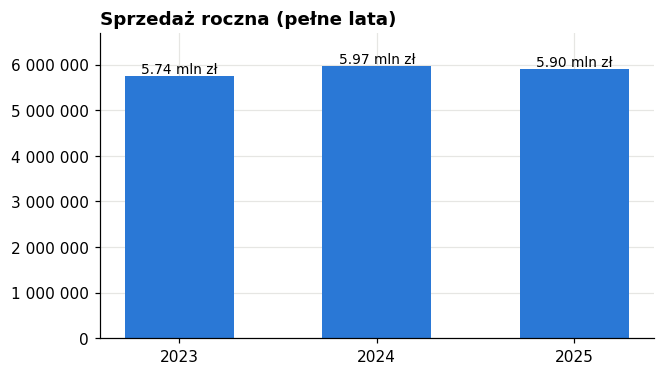

In [5]:
# Sprzedaż roczna, liczba dni handlowych i średnia na dzień handlowy
rok = dz.groupby("Rok").agg(
    Wartosc=("Wartosc", "sum"),
    DniHandlowe=("Handlowy", "sum"),
    Paragony=("Paragony", "sum"),
)
rok["SrednioNaDzien"] = rok["Wartosc"] / rok["DniHandlowe"]
rok["SredniParagon"] = rok["Wartosc"] / rok["Paragony"]
rok["ZmianaRR_%"] = rok.loc[[2023, 2024, 2025], "Wartosc"].pct_change() * 100   # tylko pełne lata
print(rok.round(1))

pelne = rok.loc[[2023, 2024, 2025]]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.bar(pelne.index.astype(str), pelne["Wartosc"], color=NIEB, width=0.55)
for x, v in zip(pelne.index.astype(str), pelne["Wartosc"]):
    ax.text(x, v, f"{v/1e6:.2f} mln zł", ha="center", va="bottom", fontsize=9)
ax.yaxis.set_major_formatter(zl)
ax.set_title("Sprzedaż roczna (pełne lata)")
ax.set_ylim(0, pelne["Wartosc"].max() * 1.12)
plt.show()

#### Objaśnienie: porównanie rok do roku
**Po co ta komórka.** Sprawdzamy, czy kształt roku powtarza się w kolejnych latach. Jeśli linie trzech lat mają podobne górki i dołki, to znak, że istnieje **sezonowość roczna**.

**Pojęcia.**
- **Sezonowość** to wzorzec, który powtarza się w stałym okresie, np. co roku albo co tydzień.
- **Rok do roku**: porównujemy ten sam miesiąc w dwóch kolejnych latach (styczeń ze styczniem), a nie miesiąc z poprzednim miesiącem. Dzięki temu sezonowość nie zaburza porównania.

**Co robi kod.**
- `groupby(["Rok", "Miesiac"])` grupuje po dwóch kolumnach naraz.
- `unstack(0)` przestawia tabelę z długiej na szeroką: lata stają się kolumnami, miesiące zostają wierszami. Taki układ łatwo narysować i porównać.
- `pct_change(axis=1)` liczy zmianę procentową między sąsiednimi kolumnami, czyli między latami. Bierzemy tylko pełne lata 2023–2025.
- Druga tabela to zmiana średniej **na dzień handlowy**. Miesiąc z dodatkowym świętem ma mniej dni handlowych i jego suma spada, choć popyt się nie zmienił.

**Jak czytać wynik.** Na wykresie szukaj wspólnego kształtu trzech linii. W tabeli wartość 7,9 przy styczniu 2024 oznacza, że styczeń 2024 był o 7,9% lepszy od stycznia 2023. Zmiany mają różne znaki w różnych miesiącach (np. marzec 2025: −6,5%, kwiecień 2025: +8,6%). Duża część takich skoków to przesuwanie się Wielkanocy między marcem a kwietniem, a nie realna zmiana popytu.

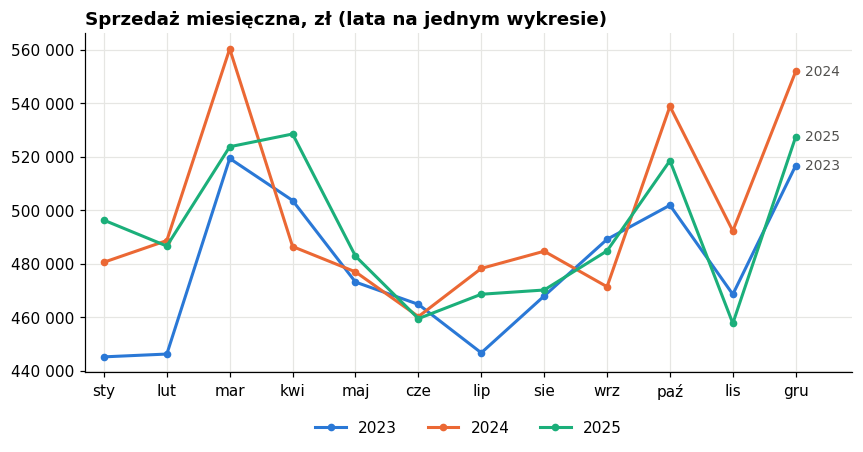

Zmiana sumy miesiąca r/r, %:
Rok      2023  2024  2025
Miesiac                  
sty       NaN   7.9   3.3
lut       NaN   9.5  -0.4
mar       NaN   7.9  -6.5
kwi       NaN  -3.4   8.6
maj       NaN   0.8   1.2
cze       NaN  -1.0  -0.2
lip       NaN   7.1  -2.0
sie       NaN   3.6  -3.0
wrz       NaN  -3.6   2.8
paź       NaN   7.4  -3.8
lis       NaN   5.1  -7.0
gru       NaN   6.8  -4.4

Zmiana średniej na dzień handlowy r/r, %:
Rok      2023  2024  2025
Miesiac                  
sty       NaN   7.9   3.3
lut       NaN   5.1   3.7
mar       NaN   7.9  -2.9
kwi       NaN  -7.1   4.6
maj       NaN   5.0  -2.8
cze       NaN  -1.0   3.8
lip       NaN   3.1  -2.0
sie       NaN  -0.3   0.7
wrz       NaN   0.2  -1.1
paź       NaN   3.4  -3.8
lis       NaN   5.1  -3.0
gru       NaN   6.8  -8.0


In [6]:
# Miesiące w kolejnych latach: ten sam miesiąc rok do roku
mies = dz.groupby(["Rok", "Miesiac"]).agg(Wartosc=("Wartosc", "sum"), DniHandlowe=("Handlowy", "sum"))
mies_suma = mies["Wartosc"].unstack(0)

fig, ax = plt.subplots(figsize=(9, 4))
for r in [2023, 2024, 2025]:
    ax.plot(MIES, mies_suma[r].values, marker="o", ms=4, lw=2, color=LATA_KOL[r], label=str(r))
    ax.text(11.15, mies_suma[r].iloc[-1], str(r), color="#52514e", va="center", fontsize=9)
ax.yaxis.set_major_formatter(zl)
ax.set_xlim(-0.3, 11.9)
ax.set_title("Sprzedaż miesięczna, zł (lata na jednym wykresie)")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.show()

# Zmiana rok do roku dla każdego miesiąca (procent), tylko pełne lata (2026 ma niepełny ostatni miesiąc)
PELNE = [2023, 2024, 2025]
zm = mies_suma[PELNE].pct_change(axis=1) * 100
print("Zmiana sumy miesiąca r/r, %:")
print(zm.round(1).rename(index=dict(zip(range(1, 13), MIES))))

# To samo w przeliczeniu na dzień handlowy: usuwa efekt różnej liczby dni handlowych (święta, niedziele handlowe)
na_dzien = (mies["Wartosc"] / mies["DniHandlowe"]).unstack(0)[PELNE]
print("\nZmiana średniej na dzień handlowy r/r, %:")
print((na_dzien.pct_change(axis=1) * 100).round(1).rename(index=dict(zip(range(1, 13), MIES))))

## 3. Miesiąc (sezonowość)
Suma miesięczna zależy od liczby dni handlowych, więc porównujemy **średnią sprzedaż na dzień handlowy od poniedziałku do soboty**. Indeks 1,00 to średnia całego roku.

#### Objaśnienie: indeks sezonowości
**Po co ta komórka.** Chcemy odpowiedzieć , o ile dany miesiąc jest lepszy lub gorszy od przeciętnego. Do tego służy **indeks sezonowości**.

**Pojęcie.** Indeks to średnia sprzedaż dzienna w miesiącu podzielona przez średnią sprzedaż dzienną w całym roku. Wartość 1,00 to miesiąc przeciętny, 1,10 to miesiąc o 10% lepszy, 0,90 o 10% słabszy.

**Dlaczego średnia dzienna, a nie suma miesiąca.** Luty ma mniej dni niż marzec, a liczba niedziel i świąt w miesiącu się zmienia. Suma karałaby krótsze miesiące. Bierzemy więc tylko dni od poniedziałku do soboty ze sprzedażą i liczymy średnią na dzień.

**Co robi kod.**
- `pnso` to filtr: dni Pn–So, handlowe, z pełnych lat.
- `sr_mies / sr_rok` dzieli tabelę (miesiące × lata) przez średnią roczną. Pandas sam dopasowuje kolumny po nazwie roku.
- Trzy słupki obok siebie dla każdego miesiąca pozwalają sprawdzić, czy wzorzec jest stabilny.

**Jak czytać wynik.** Grudzień ma indeks 1,09–1,14 we wszystkich trzech latach, a lipiec około 0,90. Wzorzec powtarza się co roku, więc sezonowość roczna istnieje, ale jest łagodna: różnica między najlepszym a najsłabszym miesiącem to około 20%. Dla porównania różnice między dniami tygodnia (następna sekcja) są podobnej wielkości, a zdarzają się co tydzień.

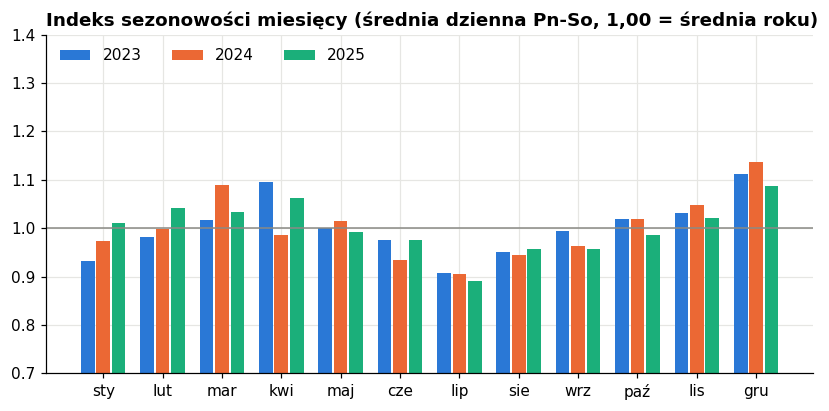

Rok      2023  2024  2025
Miesiac                  
sty      0.93  0.97  1.01
lut      0.98  1.00  1.04
mar      1.02  1.09  1.03
kwi      1.10  0.99  1.06
maj      1.00  1.02  0.99
cze      0.98  0.93  0.98
lip      0.91  0.91  0.89
sie      0.95  0.94  0.96
wrz      0.99  0.96  0.96
paź      1.02  1.02  0.99
lis      1.03  1.05  1.02
gru      1.11  1.14  1.09


In [7]:
# Indeks sezonowości miesięcy: średnia dzienna (Pn-So, dni ze sprzedażą) / średnia roku
pnso = dz[(dz["DzienTyg"] < 6) & dz["Handlowy"] & (dz["Rok"] <= 2025)]
sr_mies = pnso.groupby(["Rok", "Miesiac"])["Wartosc"].mean().unstack(0)
sr_rok = pnso.groupby("Rok")["Wartosc"].mean()
idx = sr_mies / sr_rok

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(12)
w = 0.26
for i, r in enumerate([2023, 2024, 2025]):
    ax.bar(x + (i - 1) * w, idx[r].values, width=w - 0.03, color=LATA_KOL[r], label=str(r))
ax.axhline(1, color=SZARY, lw=1)
ax.set_xticks(x); ax.set_xticklabels(MIES)
ax.set_ylim(0.7, 1.4)
ax.set_title("Indeks sezonowości miesięcy (średnia dzienna Pn-So, 1,00 = średnia roku)")
ax.legend(frameon=False, ncol=3, loc="upper left")
plt.show()
print(idx.round(2).rename(index=dict(zip(range(1, 13), MIES))))

## 4. Dzień tygodnia

#### Objaśnienie: sezonowość tygodniowa
**Po co ta komórka.** W handlu najsilniejszy powtarzalny wzorzec to zwykle rytm tygodnia. Sprawdzamy, jak sprzedaż zależy od dnia tygodnia.

**Co robi kod.**
- `hd = dz[dz["Handlowy"]]` bierze tylko dni ze sprzedażą. Gdybyśmy zostawili dni zamknięte, zera zaniżyłyby średnie.
- `agg` liczy dla każdego dnia tygodnia: liczbę takich dni, średnią i medianę wartości, średnią liczbę paragonów i średni paragon.
- Trzy wykresy rozkładają sprzedaż na czynniki: **sprzedaż = liczba paragonów × średnia wartość paragonu**.

**Średnia a mediana.** Mediana to wartość środkowa: połowa dni jest poniżej, połowa powyżej. Jest odporna na dni nietypowe. Gdy średnia jest wyraźnie wyższa od mediany, kilka bardzo dobrych dni (np. przedświątecznych) ciągnie średnią w górę.

**Jak czytać wynik.** Od poniedziałku do czwartku sprzedaż wynosi około 18,0–18,5 tys. zł, w piątek 21,1 tys., w sobotę 21,6 tys. Niedziele handlowe to tylko około 5,3 tys. zł, czyli jedna czwarta soboty, i jest ich zaledwie 21. Rozkład na czynniki pokazuje, skąd bierze się weekendowy wzrost. W piątek przybywa klientów (około 920 paragonów zamiast 860) i rośnie paragon (22,8 zł zamiast około 21,5). W sobotę klientów jest mniej niż w piątek, ale robią największe zakupy (24,4 zł na paragon).

    DniHandlowe  SredniaWartosc  MedianaWartosc  SrednieParagony  \
Pn          153         18050.4         17690.0            843.6   
Wt          157         18354.4         17800.0            865.6   
Śr          155         18162.2         17802.9            857.9   
Cz          153         18539.1         18149.0            859.4   
Pt          156         21095.2         20591.7            922.7   
So          157         21635.6         21460.4            887.7   
Nd           21          5259.5          4519.6            238.3   

    SredniParagon  
Pn           21.4  
Wt           21.2  
Śr           21.1  
Cz           21.6  
Pt           22.8  
So           24.4  
Nd           21.7  


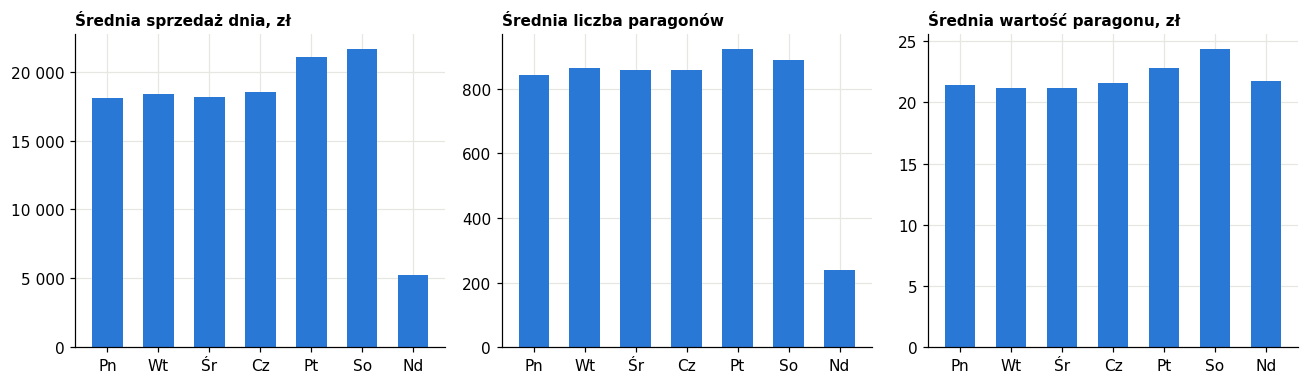

In [8]:
# Średnia sprzedaż, paragony i średni paragon wg dnia tygodnia (tylko dni handlowe)
hd = dz[dz["Handlowy"]]
dow = hd.groupby("DzienTyg").agg(
    DniHandlowe=("Wartosc", "size"),
    SredniaWartosc=("Wartosc", "mean"),
    MedianaWartosc=("Wartosc", "median"),
    SrednieParagony=("Paragony", "mean"),
    SredniParagon=("SredniParagon", "mean"),
)
dow.index = DNI
print(dow.round(1))

fig, axs = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, kol_, tyt, fmt in [
    (axs[0], "SredniaWartosc", "Średnia sprzedaż dnia, zł", zl),
    (axs[1], "SrednieParagony", "Średnia liczba paragonów", zl),
    (axs[2], "SredniParagon", "Średnia wartość paragonu, zł", None),
]:
    ax.bar(dow.index, dow[kol_], color=NIEB, width=0.6)
    ax.set_title(tyt, fontsize=10)
    if fmt: ax.yaxis.set_major_formatter(fmt)
plt.tight_layout(); plt.show()

Liczba dni handlowych:
Rok  2023  2024  2025
Pn     49    50    50
Wt     50    53    51
Śr     50    50    51
Cz     51    49    49
Pt     51    50    50
So     51    51    50
Nd      5     7     8

Średnia sprzedaż dnia, zł
Rok     2023     2024     2025
Pn   17621.3  18361.1  18124.3
Wt   17762.6  18645.9  18711.3
Śr   17635.2  18446.3  18458.7
Cz   18175.1  18882.6  18669.3
Pt   20778.5  21322.7  21256.9
So   21539.3  21758.8  21640.2
Nd    4846.2   5734.0   5319.3

Średnia liczba paragonów
Rok   2023   2024   2025
Pn   851.4  847.0  834.8
Wt   866.3  867.2  867.9
Śr   853.2  858.4  865.2
Cz   869.1  858.4  855.9
Pt   936.9  925.0  912.6
So   901.7  889.1  876.0
Nd   212.8  253.9  249.0

Średnia wartość paragonu, zł
Rok  2023  2024  2025
Pn   20.7  21.7  21.7
Wt   20.5  21.5  21.5
Śr   20.6  21.5  21.3
Cz   20.9  22.0  21.8
Pt   22.1  23.0  23.3
So   23.9  24.4  24.7
Nd   22.5  22.1  21.1

Indeks sprzedaży (1,00 = średnia Pn-So danego roku):
Rok  2023  2024  2025
Pn   0.93  0.94  0

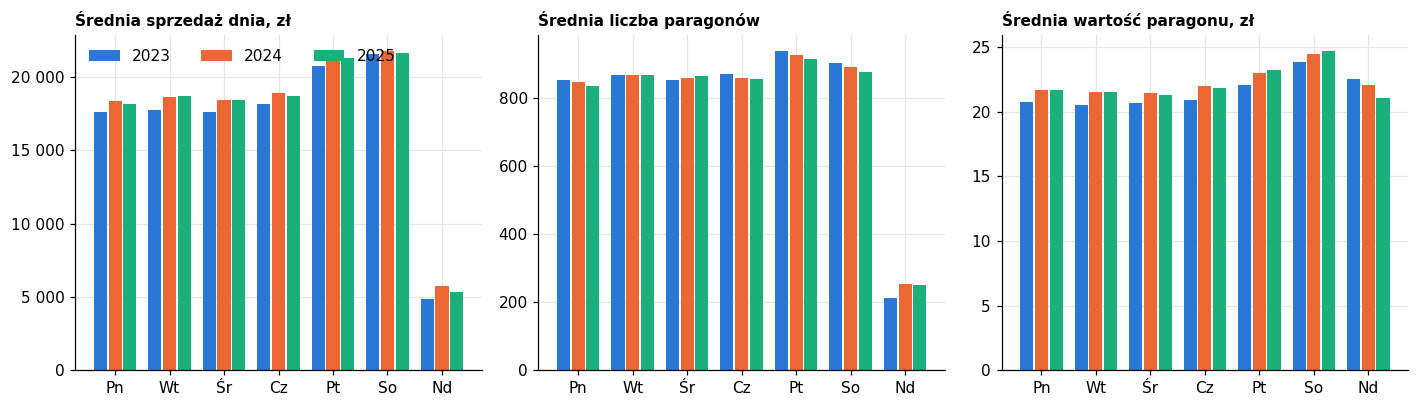

In [9]:
# Dzień tygodnia w każdym roku: sprzedaż, paragony i średni paragon (tylko dni handlowe, pełne lata)
LATA = [2023, 2024, 2025]
MIARY = [("Wartosc", "Średnia sprzedaż dnia, zł"), ("Paragony", "Średnia liczba paragonów"), ("SredniParagon", "Średnia wartość paragonu, zł")]
hd_l = hd[hd["Rok"].isin(LATA)]
dow_r = {k: hd_l.groupby(["DzienTyg", "Rok"])[k].mean().unstack().set_axis(DNI) for k, _ in MIARY}
dni_r = hd_l.groupby(["DzienTyg", "Rok"]).size().unstack().set_axis(DNI)

print("Liczba dni handlowych:"); print(dni_r.to_string()); print()
for k, tyt in MIARY:
    print(tyt); print(dow_r[k].round(1).to_string()); print()

# Indeks: dzień tygodnia / średnia Pn-So tego samego roku (porównuje kształt tygodnia, a nie poziom)
idx_r = {k: dow_r[k].iloc[:6] / dow_r[k].iloc[:6].mean() for k, _ in MIARY}
print("Indeks sprzedaży (1,00 = średnia Pn-So danego roku):"); print(idx_r["Wartosc"].round(2).to_string())

fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
x, w = np.arange(7), 0.27
for ax, (k, tyt) in zip(axs, MIARY):
    for i, r in enumerate(LATA):
        ax.bar(x + (i - 1) * w, dow_r[k][r].values, width=w - 0.03, color=LATA_KOL[r], label=str(r))
    ax.set_xticks(x); ax.set_xticklabels(DNI); ax.set_title(tyt, fontsize=10)
    if k != "SredniParagon": ax.yaxis.set_major_formatter(zl)
axs[0].legend(frameon=False, ncol=3, loc="upper left")
plt.tight_layout(); plt.show()

#### Objaśnienie: zmienność, czyli jak bardzo dni różnią się między sobą
**Po co ta komórka.** Średnia mówi, ile sprzedajemy typowo. Nie mówi, jak bardzo poszczególne dni od niej odbiegają. Ta **zmienność** decyduje o tym, jak dokładna może być prognoza.

**Jak czytać wykres pudełkowy (boxplot).**
- Pomarańczowa kreska w środku to mediana.
- Pudełko obejmuje środkowe 50% dni (od pierwszego do trzeciego kwartyla).
- „Wąsy” sięgają do typowych wartości skrajnych.
- Pojedyncze kropki to **wartości odstające**, czyli dni wyjątkowo dobre lub słabe.

Wąskie pudełko oznacza dzień przewidywalny, szerokie dzień kapryśny. Kropki wysoko nad pudełkami to niemal zawsze dni przed świętami.

**Co robi kod.** `dane_box` to lista siedmiu tablic, po jednej na dzień tygodnia. Druga część liczy średnią dla każdego dnia tygodnia osobno w każdym roku.

**Jak czytać tabelę.** Wzorzec tygodnia jest stabilny w czasie: w każdym roku piątek i sobota są o około 3 tys. zł lepsze od dni Pn–Cz. To ważne, bo prognoza opiera się na założeniu, że wzorzec z przeszłości powtórzy się w przyszłości. Gdyby rytm tygodnia zmieniał się z roku na rok, to założenie byłoby słabe.

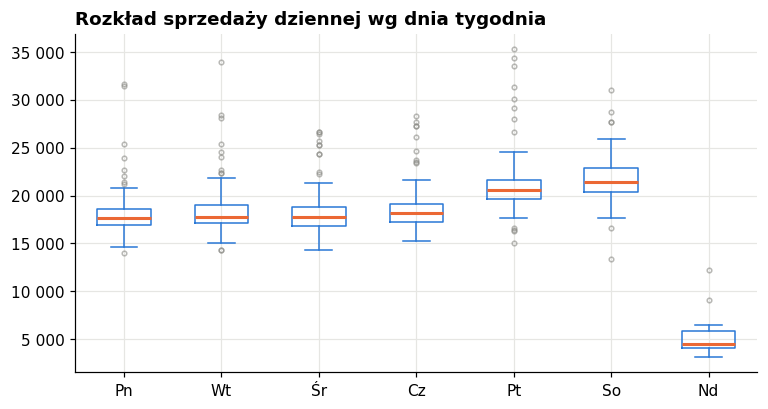

Rok     2023     2024     2025
Pn   17621.0  18361.0  18124.0
Wt   17763.0  18646.0  18711.0
Śr   17635.0  18446.0  18459.0
Cz   18175.0  18883.0  18669.0
Pt   20778.0  21323.0  21257.0
So   21539.0  21759.0  21640.0
Nd    4846.0   5734.0   5319.0


In [10]:
# Rozrzut sprzedaży dziennej w ciągu tygodnia (Pn-Nd, tylko dni ze sprzedażą)
dane_box = [hd.loc[hd["DzienTyg"] == i, "Wartosc"].values for i in range(7)]
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(dane_box, tick_labels=DNI, showfliers=True, widths=0.55,
           boxprops=dict(color=NIEB), medianprops=dict(color=POM, lw=2),
           whiskerprops=dict(color=NIEB), capprops=dict(color=NIEB),
           flierprops=dict(marker="o", ms=3, markeredgecolor=SZARY, alpha=0.6))
ax.yaxis.set_major_formatter(zl)
ax.set_title("Rozkład sprzedaży dziennej wg dnia tygodnia")
plt.show()

# Dzień tygodnia w kolejnych latach (średnia, tylko dni handlowe)
dow_rok = hd[hd["Rok"] <= 2025].groupby(["DzienTyg", "Rok"])["Wartosc"].mean().unstack()
dow_rok.index = DNI
print(dow_rok.round(0))

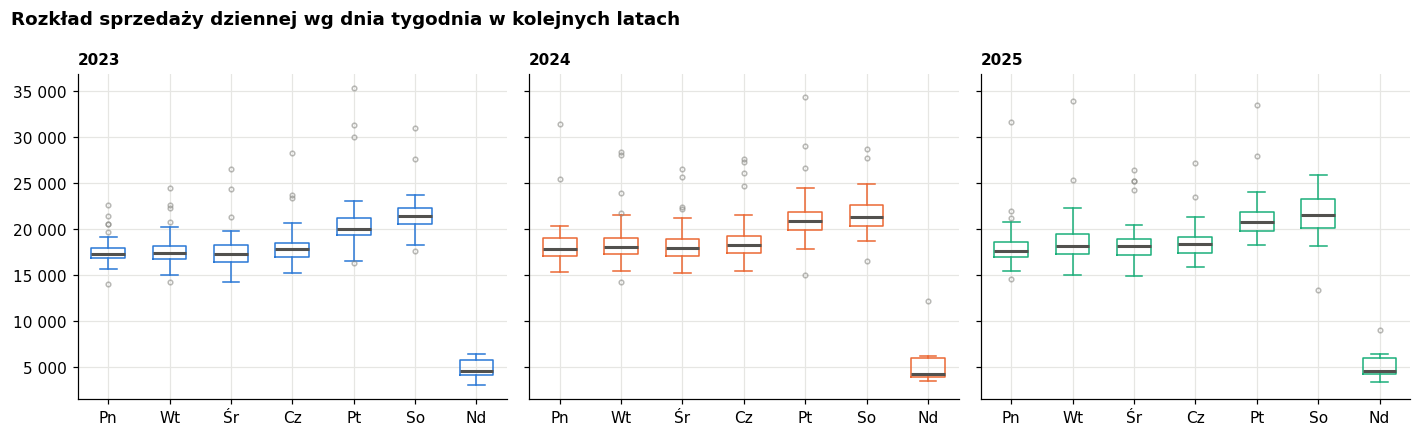

Mediana, zł:
Rok     2023     2024     2025
Pn   17327.0  17877.0  17677.0
Wt   17405.0  18099.0  18157.0
Śr   17305.0  18006.0  18172.0
Cz   17877.0  18313.0  18416.0
Pt   20088.0  20932.0  20841.0
So   21452.0  21369.0  21618.0
Nd    4602.0   4297.0   4607.0

Rozstęp międzykwartylowy (IQR), zł:
Rok    2023    2024    2025
Pn   1117.0  1905.0  1606.0
Wt   1400.0  1755.0  2166.0
Śr   1830.0  1839.0  1732.0
Cz   1537.0  1789.0  1741.0
Pt   1858.0  1970.0  2124.0
So   1798.0  2312.0  3187.0
Nd   1599.0  2018.0  1753.0

IQR jako % mediany (im mniej, tym dzień bardziej przewidywalny):
Rok  2023  2024  2025
Pn    6.4  10.7   9.1
Wt    8.0   9.7  11.9
Śr   10.6  10.2   9.5
Cz    8.6   9.8   9.5
Pt    9.2   9.4  10.2
So    8.4  10.8  14.7
Nd   34.8  47.0  38.1

Liczba dni odstających:
Rok  2023  2024  2025
Pn      6     2     4
Wt      5     5     2
Śr      3     4     4
Cz      3     4     2
Pt      4     4     2
So      3     3     1
Nd      0     1     1


In [11]:
# Rozrzut sprzedaży dziennej wg dnia tygodnia, osobno w każdym roku (tylko dni ze sprzedażą, pełne lata)
fig, axs = plt.subplots(1, len(LATA), figsize=(13, 4), sharey=True)
for ax, r in zip(axs, LATA):
    hr = hd[hd["Rok"] == r]
    dane_r = [hr.loc[hr["DzienTyg"] == i, "Wartosc"].values for i in range(7)]
    ax.boxplot(dane_r, tick_labels=DNI, showfliers=True, widths=0.55,
               boxprops=dict(color=LATA_KOL[r]), medianprops=dict(color="#52514e", lw=2),
               whiskerprops=dict(color=LATA_KOL[r]), capprops=dict(color=LATA_KOL[r]),
               flierprops=dict(marker="o", ms=3, markeredgecolor=SZARY, alpha=0.6))
    ax.set_title(str(r), fontsize=10)
axs[0].yaxis.set_major_formatter(zl)
plt.suptitle("Rozkład sprzedaży dziennej wg dnia tygodnia w kolejnych latach", x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

# Liczby do wykresu: mediana, rozstęp międzykwartylowy (szerokość pudełka) i jego udział w medianie
hd_l = hd[hd["Rok"].isin(LATA)]
g = hd_l.groupby(["DzienTyg", "Rok"])["Wartosc"]
mediana = g.median().unstack().set_axis(DNI)
iqr = (g.quantile(0.75) - g.quantile(0.25)).unstack().set_axis(DNI)
print("Mediana, zł:"); print(mediana.round(0).to_string()); print()
print("Rozstęp międzykwartylowy (IQR), zł:"); print(iqr.round(0).to_string()); print()
print("IQR jako % mediany (im mniej, tym dzień bardziej przewidywalny):"); print((100 * iqr / mediana).round(1).to_string()); print()

# Dni odstające wg reguły wykresu pudełkowego (poza 1,5 x IQR od pudełka), policzone w obrębie roku i dnia tygodnia
q1, q3 = g.transform(lambda v: v.quantile(0.25)), g.transform(lambda v: v.quantile(0.75))
odst = (hd_l["Wartosc"] > q3 + 1.5 * (q3 - q1)) | (hd_l["Wartosc"] < q1 - 1.5 * (q3 - q1))
print("Liczba dni odstających:"); print(odst.groupby([hd_l["DzienTyg"], hd_l["Rok"]]).sum().unstack().set_axis(DNI).to_string())

## 5. Święta
Sklep jest zamknięty w święta i większość niedziel. Sprawdzamy, jak sprzedaż zachowuje się **wokół** świąt (dni przed i po), na tle zwykłych dni. Punkt odniesienia dla każdego dnia to mediana sprzedaży **tego samego dnia tygodnia** w oknie ±6 tygodni, z pominięciem dni blisko świąt.

#### Objaśnienie: lista świąt
**Po co ta komórka.** Wypisujemy wszystkie święta państwowe z okresu danych, żeby mieć je przed oczami przy dalszej analizie.

**Dlaczego święta są ważne w szeregach czasowych.** Święto działa na sprzedaż inaczej niż trend i sezonowość:
- w samo święto sklep jest zamknięty, więc sprzedaż wynosi 0,
- przed świętem klienci kupują na zapas, więc sprzedaż rośnie,
- po święcie sprzedaż często spada, bo zapasy są zrobione.

Do tego część świąt jest **ruchoma**: Wielkanoc, Zielone Świątki i Boże Ciało wypadają co roku w innym dniu. Sama sezonowość miesięczna tego nie uchwyci, bo Wielkanoc bywa w marcu albo w kwietniu.

**Co robi kod.** `swieta` to seria „data: nazwa”, zbudowana w sekcji 1. `to_string()` wypisuje ją w całości, bez skracania długich tabel.

**Efekt kalendarzowy.** Tak nazywamy wpływ świąt i dni wolnych na szereg. W tym notatniku jest to osobny, bardzo ważny składnik zmienności.

In [12]:
# Lista świąt w danych
print(swieta.to_string())

2023-01-01                                  Nowy Rok
2023-01-06                       Święto Trzech Króli
2023-04-09                     Niedziela Wielkanocna
2023-04-10                  Poniedziałek Wielkanocny
2023-05-01                          Święto Państwowe
2023-05-03            Święto Narodowe Trzeciego Maja
2023-05-28                           Zielone Świątki
2023-06-08                        Dzień Bożego Ciała
2023-08-15    Wniebowzięcie Najświętszej Marii Panny
2023-11-01           Uroczystość Wszystkich Świętych
2023-11-11            Narodowe Święto Niepodległości
2023-12-25          Boże Narodzenie (pierwszy dzień)
2023-12-26             Boże Narodzenie (drugi dzień)
2024-01-01                                  Nowy Rok
2024-01-06                       Święto Trzech Króli
2024-03-31                     Niedziela Wielkanocna
2024-04-01                  Poniedziałek Wielkanocny
2024-05-01                          Święto Państwowe
2024-05-03            Święto Narodowe Trzecieg

#### Objaśnienie: jak zmierzyć, czy dzień był „lepszy niż zwykle”
**Po co ta komórka.** Chcemy ocenić wpływ świąt. Nie wystarczy porównać dnia przedświątecznego ze średnią, bo sobota i tak jest lepsza od wtorku. Potrzebujemy porównania ze **zwykłym dniem tego samego rodzaju**.

**Pomysł.** Dla każdego dnia liczymy „bazę”: medianę sprzedaży z tego samego dnia tygodnia w oknie 6 tygodni przed i 6 tygodni po, z pominięciem dni w okolicach świąt. Potem dzielimy sprzedaż dnia przez tę bazę.

**Wskaźnik = sprzedaż dnia / baza.** Wartość 1,00 oznacza dzień zwykły, 1,50 dzień o 50% lepszy od normy, 0,70 dzień o 30% słabszy.

**Co robi kod.**
- Pętla `for d in swieta.index` zaznacza dni odległe o najwyżej 4 dni od dowolnego święta (`BliskoSwieta`). Operator `|=` to „lub”: dzień jest oznaczony, jeśli leży blisko choć jednego święta.
- `zwykle` to dni handlowe Pn–So, które nie leżą blisko świąt.
- Funkcja `baza(data)` wybiera z nich ten sam dzień tygodnia w odległości do 42 dni i zwraca medianę. Sam oceniany dzień jest pominięty (`zwykle.index != data`), bo inaczej wchodziłby do własnej normy i ściągał wskaźnik w stronę 1,00. Gdy takich dni jest mniej niż 3, zwraca brak (`NaN`).

**Jak czytać wynik.** Wskaźnik ma medianę 1,00 i odchylenie 0,12, czyli typowy dzień różni się od swojej normy o kilkanaście procent. Skrajne wartości to 0,58 i 1,95: zdarzają się dni o połowę słabsze i prawie dwa razy lepsze od zwykłych.

**Ważne zastrzeżenie.** Okno sięga także w przyszłość (6 tygodni *po* danym dniu). Do opisu danych to w porządku, ale takiej wielkości nie wolno podać modelowi prognozującemu, bo w dniu prognozy przyszłości nie znamy. Ten błąd nazywa się **wyciekiem danych**.

In [13]:
# Punkt odniesienia: mediana tego samego dnia tygodnia w oknie ±42 dni, bez dni z okolic świąt
BLISKO = 4   # dni od święta, które uznajemy za "okolice świąt"
blisko_swieta = np.zeros(len(dz), dtype=bool)
for d in swieta.index:
    blisko_swieta |= (np.abs((dz.index - d).days) <= BLISKO)
dz["BliskoSwieta"] = blisko_swieta

zwykle = dz[dz["Handlowy"] & ~dz["BliskoSwieta"] & (dz["DzienTyg"] < 6)]
def baza(data):
    # bez samego ocenianego dnia, żeby nie wchodził do własnej normy
    okno = zwykle[(zwykle["DzienTyg"] == data.dayofweek) & (zwykle.index != data)
                  & ((zwykle.index - data).days.to_series(index=zwykle.index).abs() <= 42)]
    return okno["Wartosc"].median() if len(okno) >= 3 else np.nan

dz["Baza"] = [baza(d) if (h and w < 6) else np.nan for d, h, w in zip(dz.index, dz["Handlowy"], dz["DzienTyg"])]
dz["Wskaznik"] = dz["Wartosc"] / dz["Baza"]       # 1,00 = tyle co zwykle
print(dz.loc[dz["Wskaznik"].notna(), "Wskaznik"].describe().round(2))

count    930.00
mean       1.02
std        0.12
min        0.58
25%        0.96
50%        1.00
75%        1.05
max        1.95
Name: Wskaznik, dtype: float64


#### Objaśnienie: profil sprzedaży wokół święta
**Po co ta komórka.** Sprawdzamy, jak wygląda sprzedaż w kolejnych dniach przed i po święcie. Taki wzór nazywamy **profilem święta**.

**Co robi kod.**
- `WYBRANE` to słownik: nazwa święta i jego daty w kolejnych latach. Wielkanoc liczy funkcja `easter(y)`, a Boże Ciało to Wielkanoc plus 60 dni.
- `OFFS = range(-7, 4)` to przesunięcia: od 7 dni przed świętem do 3 dni po. Zero to samo święto.
- Dla każdego święta i każdego przesunięcia pobieramy wskaźnik z poprzedniej komórki, a potem uśredniamy po latach (`.mean()`).

**Jak czytać wykres.** Każdy panel to jedno święto. Słupek nad linią 1,00 oznacza sprzedaż powyżej normy. Kolor pomarańczowy to ponad 15% powyżej, szary ponad 15% poniżej. Brak słupka oznacza zamknięty sklep albo niedzielę (wskaźnik liczymy tylko dla Pn–So).

**Jak czytać wynik.** Przed Bożym Narodzeniem sprzedaż rośnie stopniowo: tydzień wcześniej jest o 20% wyższa, a 3 i 2 dni przed świętem o 63–69%. Dzień przed świętem (Wigilia) wypada poniżej normy, około 0,90, bo sklep pracuje krócej. Od 2025 roku Wigilia jest dniem wolnym, więc ta wartość pochodzi z lat 2023 i 2024. Dwa dni po święcie sprzedaż to 0,72 normy. Wielkanoc ma podobny kształt: szczyt 2–3 dni wcześniej (1,50–1,62).

**Wniosek dla prognozy.** Efekt święta nie dotyczy jednego dnia, tylko około dwóch tygodni. Dlatego w sekcji 7 powstają cechy typu „ile dni do święta”, a nie tylko „czy dziś jest święto”.

    Boże Narodzenie (25.12)  Wielkanoc (niedziela)  \
-7                     1.22                    NaN   
-6                     1.19                   1.11   
-5                     1.15                   1.25   
-4                     1.24                   1.31   
-3                     1.63                   1.50   
-2                     1.69                   1.62   
-1                     0.90                   0.93   
 0                      NaN                    NaN   
 1                      NaN                    NaN   
 2                     0.72                   0.82   
 3                     0.87                   0.94   

    Wszystkich Świętych (1.11)  Nowy Rok (1.01)  Boże Ciało  3 Maja  
-7                        1.02              NaN        1.06    0.99  
-6                        0.98              NaN        1.00    1.06  
-5                        1.06             0.72        1.11    1.03  
-4                        1.05             0.87         NaN    1.09  
-

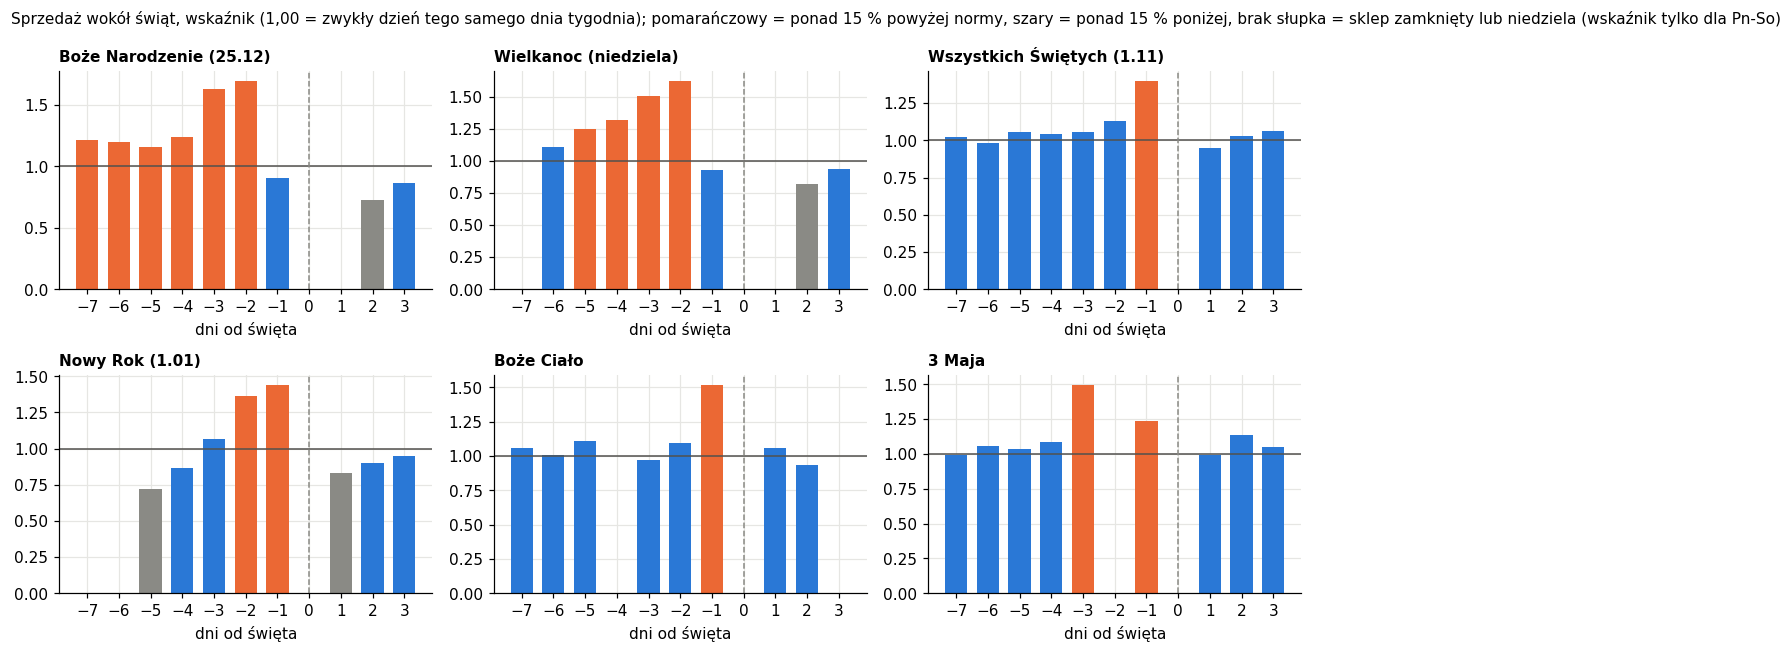

In [14]:
# Profil sprzedaży wokół wybranych świąt: wskaźnik dla dni od -7 do +3 względem święta
lata = range(dz.index.year.min(), dz.index.year.max() + 1)
WYBRANE = {                                   # daty liczymy wprost (nie po nazwach), więc działa w każdym języku biblioteki
    "Boże Narodzenie (25.12)": [pd.Timestamp(y, 12, 25) for y in lata],
    "Wielkanoc (niedziela)": [pd.Timestamp(easter(y)) for y in lata],
    "Wszystkich Świętych (1.11)": [pd.Timestamp(y, 11, 1) for y in lata],
    "Nowy Rok (1.01)": [pd.Timestamp(y, 1, 1) for y in lata],
    "Boże Ciało": [pd.Timestamp(easter(y)) + pd.Timedelta(days=60) for y in lata],
    "3 Maja": [pd.Timestamp(y, 5, 3) for y in lata],
}
OFFS = list(range(-7, 4))
profile = {}
for nazwa, daty in WYBRANE.items():
    wiersze = []
    for d in daty:
        w = {o: dz["Wskaznik"].get(d + pd.Timedelta(days=o), np.nan) for o in OFFS}
        wiersze.append(w)
    profile[nazwa] = pd.DataFrame(wiersze).mean()
prof = pd.DataFrame(profile)
print(prof.round(2))

fig, axs = plt.subplots(2, 3, figsize=(12, 6), sharey=False)
for ax, nazwa in zip(axs.ravel(), prof.columns):
    s = prof[nazwa]
    kol_ = [POM if v > 1.15 else (NIEB if np.isnan(v) or v >= 0.85 else SZARY) for v in s.values]
    ax.bar(s.index, s.fillna(0).values, color=kol_, width=0.7)
    ax.axhline(1, color="#52514e", lw=1)
    ax.axvline(0, color=SZARY, lw=1, ls="--")
    ax.set_title(nazwa, fontsize=10)
    ax.set_xticks(OFFS)
    ax.set_xlabel("dni od święta")
plt.suptitle("Sprzedaż wokół świąt, wskaźnik (1,00 = zwykły dzień tego samego dnia tygodnia); pomarańczowy = ponad 15 % powyżej normy, szary = ponad 15 % poniżej, brak słupka = sklep zamknięty lub niedziela (wskaźnik tylko dla Pn-So)", x=0.01, ha="left", fontsize=10)
plt.tight_layout(); plt.show()

Boże Narodzenie (25.12)
  2023: 25.12 (Pn) | inne święta w oknie: Boże Narodzenie (drugi dzień) (+1)
  2024: 25.12 (Śr) | inne święta w oknie: Boże Narodzenie (drugi dzień) (+1)
  2025: 25.12 (Cz) | inne święta w oknie: Wigilia Bożego Narodzenia (-1), Boże Narodzenie (drugi dzień) (+1)
        -7    -6    -5    -4    -3    -2   -1   0   1     2     3
2023  1.29  1.15  1.20  1.28  1.40  1.38  NaN NaN NaN  0.89  0.93
2024  1.19  1.34  1.24  1.20   NaN  1.75  0.9 NaN NaN  0.70  0.80
2025  1.18  1.09  1.03   NaN  1.85  1.95  NaN NaN NaN  0.58   NaN

Wielkanoc (niedziela)
  2023: 09.04 (Nd) | inne święta w oknie: Poniedziałek Wielkanocny (+1)
  2024: 31.03 (Nd) | inne święta w oknie: Poniedziałek Wielkanocny (+1)
  2025: 20.04 (Nd) | inne święta w oknie: Poniedziałek Wielkanocny (+1)
      -7    -6    -5    -4    -3    -2    -1   0   1     2     3
2023 NaN  1.15  1.27  1.34  1.58  1.68  0.94 NaN NaN  0.89  1.02
2024 NaN  1.15  1.31  1.23  1.45  1.60  0.95 NaN NaN  0.78  0.87
2025 NaN  1.01 

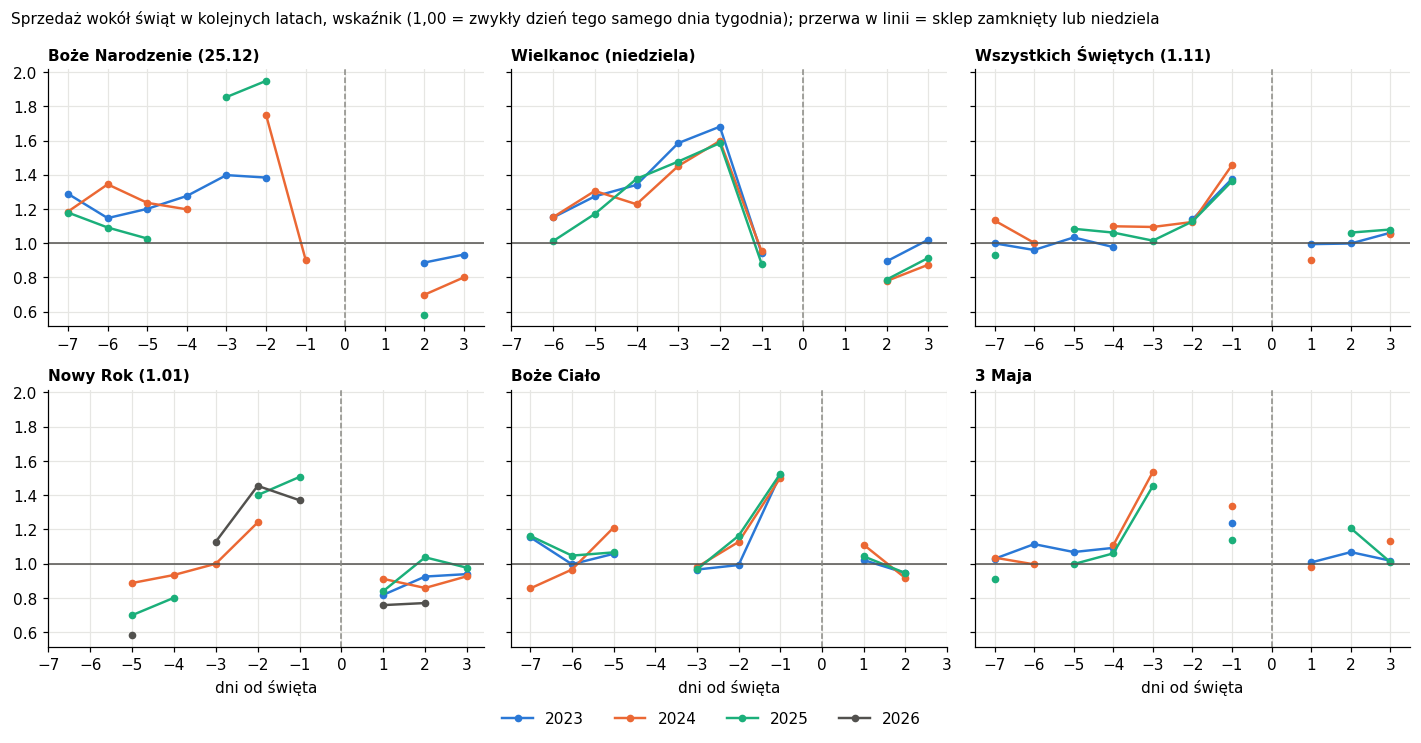

Różnica między najwyższym a najniższym rokiem (w punktach wskaźnika; puste = dane z najwyżej jednego roku):
    Boże Narodzenie (25.12)  Wielkanoc (niedziela)  Wszystkich Świętych (1.11)  Nowy Rok (1.01)  Boże Ciało  3 Maja
-7                     0.11                    NaN                        0.20              NaN        0.31    0.13
-6                     0.25                   0.14                        0.04              NaN        0.08    0.12
-5                     0.21                   0.13                        0.05             0.30        0.15    0.07
-4                     0.08                   0.15                        0.12             0.13         NaN    0.05
-3                     0.46                   0.13                        0.08             0.13        0.01    0.08
-2                     0.56                   0.10                        0.02             0.21        0.17     NaN
-1                      NaN                   0.07                        0.09  

In [15]:
# Profil sprzedaży wokół świąt osobno w każdym roku (te same święta i ten sam wskaźnik co wyżej)
# Dzień 0 to faktyczna data święta w danym roku, także dla świąt ruchomych (Wielkanoc, Boże Ciało = Wielkanoc + 60 dni)
KOL_ROK = {**LATA_KOL, 2026: "#52514e"}
prof_rok = {}
for nazwa, daty in WYBRANE.items():
    t = pd.DataFrame({d.year: [dz["Wskaznik"].get(d + pd.Timedelta(days=o), np.nan) for o in OFFS] for d in daty}, index=OFFS)
    prof_rok[nazwa] = t.dropna(axis=1, how="all")            # bez lat, w których święto leży poza zakresem danych

# Dla każdego święta i roku: faktyczna data (święta ruchome mają co roku inną) i inne święta w tym samym oknie
for nazwa, t in prof_rok.items():
    print(nazwa)
    for d in WYBRANE[nazwa]:
        if d.year not in t.columns: continue
        okno = swieta[(swieta.index >= d + pd.Timedelta(days=OFFS[0])) & (swieta.index <= d + pd.Timedelta(days=OFFS[-1])) & (swieta.index != d)]
        inne = ", ".join(f"{n} ({(x - d).days:+d})" for x, n in okno.items()) or "brak"
        print(f"  {d.year}: {d.strftime('%d.%m')} ({DNI[d.dayofweek]}) | inne święta w oknie: {inne}")
    print(t.round(2).T.to_string()); print()

fig, axs = plt.subplots(2, 3, figsize=(13, 6.5), sharey=True)
for ax, (nazwa, t) in zip(axs.ravel(), prof_rok.items()):
    for r in t.columns:
        ax.plot(t.index, t[r].values, marker="o", ms=4, lw=1.6, color=KOL_ROK.get(r, SZARY), label=str(r))
    ax.axhline(1, color="#52514e", lw=1)
    ax.axvline(0, color=SZARY, lw=1, ls="--")
    ax.set_title(nazwa, fontsize=10)
    ax.set_xticks(OFFS)
for ax in axs[1]: ax.set_xlabel("dni od święta")
uchwyty = {l: h for ax in axs.ravel() for h, l in zip(*ax.get_legend_handles_labels())}
fig.legend([uchwyty[l] for l in sorted(uchwyty)], sorted(uchwyty), frameon=False, ncol=len(uchwyty), loc="lower center", bbox_to_anchor=(0.5, -0.04))
plt.suptitle("Sprzedaż wokół świąt w kolejnych latach, wskaźnik (1,00 = zwykły dzień tego samego dnia tygodnia); przerwa w linii = sklep zamknięty lub niedziela", x=0.01, ha="left", fontsize=10)
plt.tight_layout(); plt.show()

# Rozrzut między latami: jak bardzo profil tego samego święta różni się z roku na rok
rozrzut = pd.DataFrame({n: t.max(axis=1) - t.min(axis=1) for n, t in prof_rok.items()})
print("Różnica między najwyższym a najniższym rokiem (w punktach wskaźnika; puste = dane z najwyżej jednego roku):")
print(rozrzut.where(pd.DataFrame({n: t.notna().sum(axis=1) for n, t in prof_rok.items()}) >= 2).round(2).to_string())

#### Objaśnienie: dni rekordowe
**Po co ta komórka.** Patrzymy na skrajności: 8 najlepszych i 8 najsłabszych dni w całej historii. To prosty test, czy nasze rozumienie danych jest poprawne. Jeśli rekordy da się wyjaśnić kalendarzem, to dobrze. Jeśli nie, w danych jest coś, czego jeszcze nie rozumiemy.

**Co robi kod.**
- `sort_values("Wartosc")` sortuje dni rosnąco. `head(8)` daje najsłabsze, a `tail(8)[::-1]` najlepsze w kolejności od największego.
- Funkcja `opisz(d)` szuka najbliższego święta. `np.argmin(np.abs(odl))` zwraca pozycję najmniejszej odległości. Jeśli święto jest dalej niż 7 dni, opis zostaje pusty.
- Zapis `(+2 dni)` oznacza, że święto wypada 2 dni po danym dniu.

**Jak czytać wynik.** Wszystkie 8 najlepszych dni leży tuż przed świętem: trzy razy Wielki Piątek (2 dni przed Wielkanocą), cztery razy dni przed Bożym Narodzeniem i raz dzień przed 11 listopada. Obrót wynosi wtedy 31–35 tys. zł przy typowych 19 tys. Wśród najsłabszych dni połowa to dni tuż po świętach, a pozostałe to zwykłe dni w lipcu i sierpniu, czyli w najsłabszych miesiącach roku. Skrajności są więc wyjaśnione przez kalendarz i sezon.

**Czego to uczy.** W szeregach czasowych wartość odstająca nie zawsze jest błędem w danych. Tutaj to prawdziwe, powtarzalne zdarzenia. Usunięcie ich jako „anomalii” byłoby błędem, bo to właśnie te dni są dla sklepu najważniejsze.

In [16]:
# Najlepsze i najsłabsze dni w całych danych (dni handlowe Pn-So), z opisem święta
top = dz[dz["Handlowy"] & (dz["DzienTyg"] < 6)].sort_values("Wartosc")
def opisz(d):
    # najbliższe święto, w odległości do 7 dni
    odl = (swieta.index - d).days
    i = int(np.argmin(np.abs(odl)))
    return f"{swieta.iloc[i]} ({int(odl[i]):+d} dni)" if abs(odl[i]) <= 7 else ""
for tytul, czesc in [("Najwyższa sprzedaż", top.tail(8)[::-1]), ("Najniższa sprzedaż (Pn-So)", top.head(8))]:
    t = czesc[["Wartosc", "Paragony"]].copy()
    t["DzienTyg"] = [DNI[i] for i in czesc["DzienTyg"]]
    t["Okolice"] = [opisz(d) for d in czesc.index]
    print(tytul); print(t.round(0).to_string()); print()

Najwyższa sprzedaż
            Wartosc  Paragony DzienTyg                                    Okolice
Data                                                                             
2023-04-07  35314.0      1300       Pt             Niedziela Wielkanocna (+2 dni)
2024-03-29  34377.0      1267       Pt             Niedziela Wielkanocna (+2 dni)
2025-12-23  33943.0      1307       Wt         Wigilia Bożego Narodzenia (+1 dni)
2025-04-18  33492.0      1252       Pt             Niedziela Wielkanocna (+2 dni)
2025-12-22  31674.0      1218       Pn         Wigilia Bożego Narodzenia (+2 dni)
2024-12-23  31434.0      1165       Pn  Boże Narodzenie (pierwszy dzień) (+2 dni)
2023-11-10  31378.0      1201       Pt    Narodowe Święto Niepodległości (+1 dni)
2023-12-23  30974.0      1083       So  Boże Narodzenie (pierwszy dzień) (+2 dni)

Najniższa sprzedaż (Pn-So)
            Wartosc  Paragony DzienTyg                                 Okolice
Data                                                  

#### Objaśnienie: niedziele handlowe jako osobny przypadek
**Po co ta komórka.** Niedziel handlowych jest tylko 21 w ponad trzech latach. To za mało, żeby model nauczył się ich sam, więc oglądamy je osobno.

**Co robi kod.**
- `nd` to niedziele (dzień tygodnia 6), w które była sprzedaż.
- Dla każdej bierzemy sprzedaż z soboty dzień wcześniej (`d - pd.Timedelta(days=1)`). Metoda `.get(klucz, np.nan)` zwraca brak, jeśli takiej daty nie ma, zamiast przerywać działanie błędem.
- `Nd/So` to stosunek sprzedaży niedzielnej do sobotniej.

**Jak czytać wynik.** Niedziela handlowa daje zwykle 16–29% sprzedaży z poprzedniej soboty. Niedziele przed Wielkanocą i w grudniu wypadają lepiej niż te w styczniu czy czerwcu, a ostatnia niedziela przed Bożym Narodzeniem osiąga nawet 38–43% soboty.

**Wniosek dla prognozy.** Niedziela handlowa to nie jest „zwykły dzień otwarty”. Gdyby model potraktował ją jak sobotę, zawyżyłby prognozę cztero- lub pięciokrotnie. Gdyby potraktował ją jak zwykłą niedzielę, dałby zero. Dlatego w cechach dla modelu jest osobna flaga `CzyNiedzielaHandlowa`.

**Ogólna lekcja.** Rzadkie zdarzenia warto obejrzeć ręcznie w tabeli. Przy 21 obserwacjach żadna statystyka nie zastąpi przejrzenia danych własnymi oczami.

In [17]:
# Niedziele handlowe: czy sprzedaż odbiega od zwykłej niedzieli handlowej i od soboty?
nd = dz[(dz["DzienTyg"] == 6) & dz["Handlowy"]]
sob_przed = [dz["Wartosc"].get(d - pd.Timedelta(days=1), np.nan) for d in nd.index]
t = pd.DataFrame({"Wartosc": nd["Wartosc"].round(0), "SobotaPrzed": np.round(sob_przed, 0), "Okolice": [opisz(d) for d in nd.index]})
t["Nd/So"] = (t["Wartosc"] / t["SobotaPrzed"]).round(2)
print(t.to_string())

            Wartosc  SobotaPrzed                                    Okolice  Nd/So
Data                                                                              
2023-01-29   4181.0      21522.0                                              0.19
2023-04-02   5780.0      23365.0             Niedziela Wielkanocna (+7 dni)   0.25
2023-06-25   3151.0      19363.0                                              0.16
2023-12-10   4602.0      22917.0                                              0.20
2023-12-17   6518.0      22453.0                                              0.29
2024-01-28   4297.0      20833.0                                              0.21
2024-03-24   6286.0      24109.0             Niedziela Wielkanocna (+7 dni)   0.26
2024-04-28   4032.0      21850.0                  Święto Państwowe (+3 dni)   0.18
2024-06-30   3543.0      20479.0                                              0.17
2024-08-25   3996.0      19159.0                                              0.21
2024

## 6. Szeregi czasowe
Szereg sprzedaży dziennej Pn-So (niedziele pomijamy, bo prawie zawsze są zamknięte). Święta w Pn-So nie mają sprzedaży, więc na potrzeby dekompozycji uzupełniamy je interpolacją (to tylko kilkadziesiąt dni). Wymaga biblioteki `statsmodels`.


**Sześć kroków analizy szeregu czasowego w tej sekcji:**
1. indeks o stałej częstotliwości: szereg `ts` (Pn-So) i tabela `dz` z sekcji 1,
2. wykres i dekompozycja STL,
3. autokorelacja (ACF, PACF) i testy stacjonarności (ADF, KPSS),
4. podział chronologiczny: uczymy się na przeszłości, sprawdzamy na przyszłości,
5. model (Holt-Winters) i punkty odniesienia,
6. porównanie błędów modelu i punktów odniesienia.

#### Objaśnienie: przygotowanie szeregu i średnie kroczące
**Po co ta komórka.** Metody z tej sekcji (dekompozycja, autokorelacja) wymagają szeregu **regularnego i bez dziur**. Budujemy więc szereg `ts_i`, który spełnia te warunki.

**Dwie decyzje i ich powody.**
- **Pomijamy niedziele.** Prawie zawsze są zamknięte, więc w szeregu byłoby co siódme zero. Po ich usunięciu „tydzień” ma 6 kroków (Pn–So).
- **Święta uzupełniamy interpolacją.** Święto w dzień powszedni to brak sprzedaży. Wstawiamy tam `NaN` (brak danych), a potem `interpolate()` wypełnia lukę wartością pośrednią między dniami sąsiednimi.

**Uwaga o interpolacji.** Interpolacja tworzy liczby, których nie było w rzeczywistości. Jest dopuszczalna tylko dlatego, że dotyczy 35 dni z 966 i służy wyłącznie do rysowania i dekompozycji. Do uczenia modelu takich wartości nie używamy.

**Średnia krocząca.** Dla każdego dnia liczymy średnią z ostatnich N dni. Uśrednianie wygładza przypadkowe wahania i odsłania wolniejsze zmiany.
- `rolling(6).mean()` to średnia z 6 dni handlowych, czyli z jednego tygodnia. Usuwa rytm tygodnia, bo w każdym oknie jest po jednym poniedziałku, wtorku itd.
- `rolling(26).mean()` to średnia z około 4 tygodni. Pokazuje trend i sezon roczny.

**Jak czytać wykres.** Szara linia to surowe dane dzienne, bardzo poszarpane. Niebieska (tydzień) pokazuje krótkie fale, w tym szczyty świąteczne. Pomarańczowa (miesiąc) pokazuje ogólny poziom: tu widać coroczne wzniesienie w grudniu i dołek w lipcu.

Dni Pn-So w szeregu: 966, uzupełnionych (święta): 35


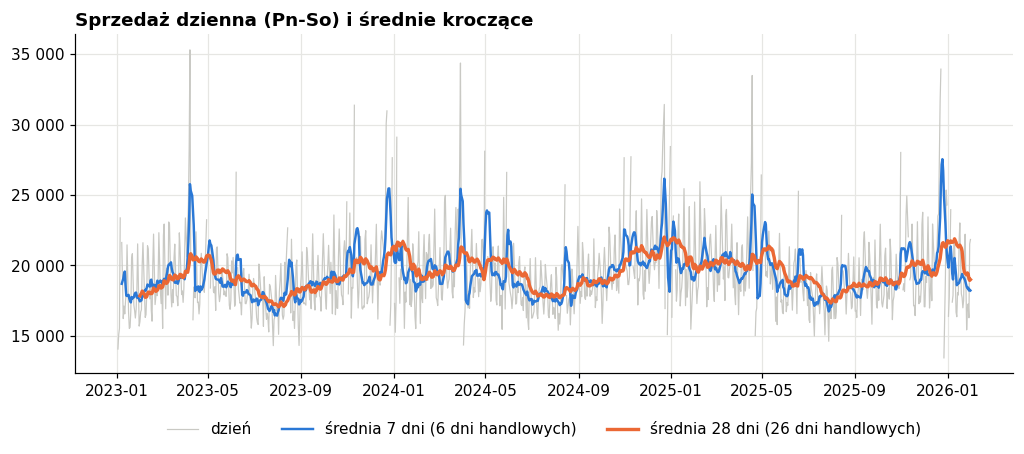

In [18]:
# Szereg Pn-So: święta (brak sprzedaży) uzupełnione interpolacją, tylko do dekompozycji i ACF
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf

ts = dz.loc[dz["DzienTyg"] < 6, "Wartosc"].astype(float)
ts[~dz.loc[ts.index, "Handlowy"]] = np.nan
n_braki = int(ts.isna().sum())
ts_i = ts.interpolate(limit_direction="both")
print(f"Dni Pn-So w szeregu: {len(ts_i)}, uzupełnionych (święta): {n_braki}")

# Średnie kroczące (7 i 28 dni handlowych) na tle surowych danych
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(ts.index, ts.values, color="#c9c9c4", lw=0.8, label="dzień")
ax.plot(ts.index, ts_i.rolling(6, min_periods=6).mean(), color=NIEB, lw=1.6, label="średnia 7 dni (6 dni handlowych)")
ax.plot(ts.index, ts_i.rolling(26, min_periods=26).mean(), color=POM, lw=2.2, label="średnia 28 dni (26 dni handlowych)")
ax.yaxis.set_major_formatter(zl)
ax.set_title("Sprzedaż dzienna (Pn-So) i średnie kroczące")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.show()

#### Objaśnienie: dekompozycja szeregu na składniki
**Po co ta komórka.** To serce analizy szeregów czasowych. Rozkładamy sprzedaż na trzy części, które się sumują:

**sprzedaż = trend + sezonowość + reszta**

- **Trend**: wolno zmieniający się poziom.
- **Sezonowość**: powtarzalny wzorzec, tutaj tygodniowy.
- **Reszta**: wszystko, czego dwa pierwsze składniki nie wyjaśniają (święta, pogoda, promocje, przypadek).

**Metoda STL.** To popularny algorytm dekompozycji. Jego parametry:
- `period=6`: długość sezonu, czyli 6 dni handlowych w tygodniu.
- `seasonal=7`: jak szybko wzorzec tygodnia może się zmieniać w czasie (mała wartość pozwala na szybsze zmiany).
- `trend=79`: szerokość okna wygładzania trendu, około 13 tygodni. Dzięki temu trend zawiera też wolne zmiany w ciągu roku.
- `robust=True`: dni nietypowe (święta) mają mniejszy wpływ na trend i sezon, więc trafiają do reszty.

**Dlaczego nie wydzielamy sezonu rocznego.** Mamy tylko 3 lata, czyli 3 powtórzenia roku. Z trzech obserwacji nie da się wiarygodnie oszacować wzorca.

**Jak czytać wynik.**
- Udział w wariancji mówi, ile zmienności szeregu przypada na każdy składnik: trend 6,7%, tydzień 35,3%, reszta 57,5%. Rytm tygodnia jest więc ważny, ale ponad połowa zmienności to „reszta”.
- Kluczowe zdanie: 83% reszty pochodzi z dni w okolicach świąt, które stanowią tylko 24% dni. Reszta nie jest więc przypadkowym szumem. To efekt kalendarza, który da się przewidzieć.
- Wzorzec tygodniowy w złotówkach: od poniedziałku do czwartku około 900–1400 zł poniżej poziomu, piątek +1750 zł, sobota +2500 zł.

**Wniosek.** Dobry model dla tego sklepu potrzebuje przede wszystkim dnia tygodnia i informacji o świętach. Trend ma małe znaczenie.

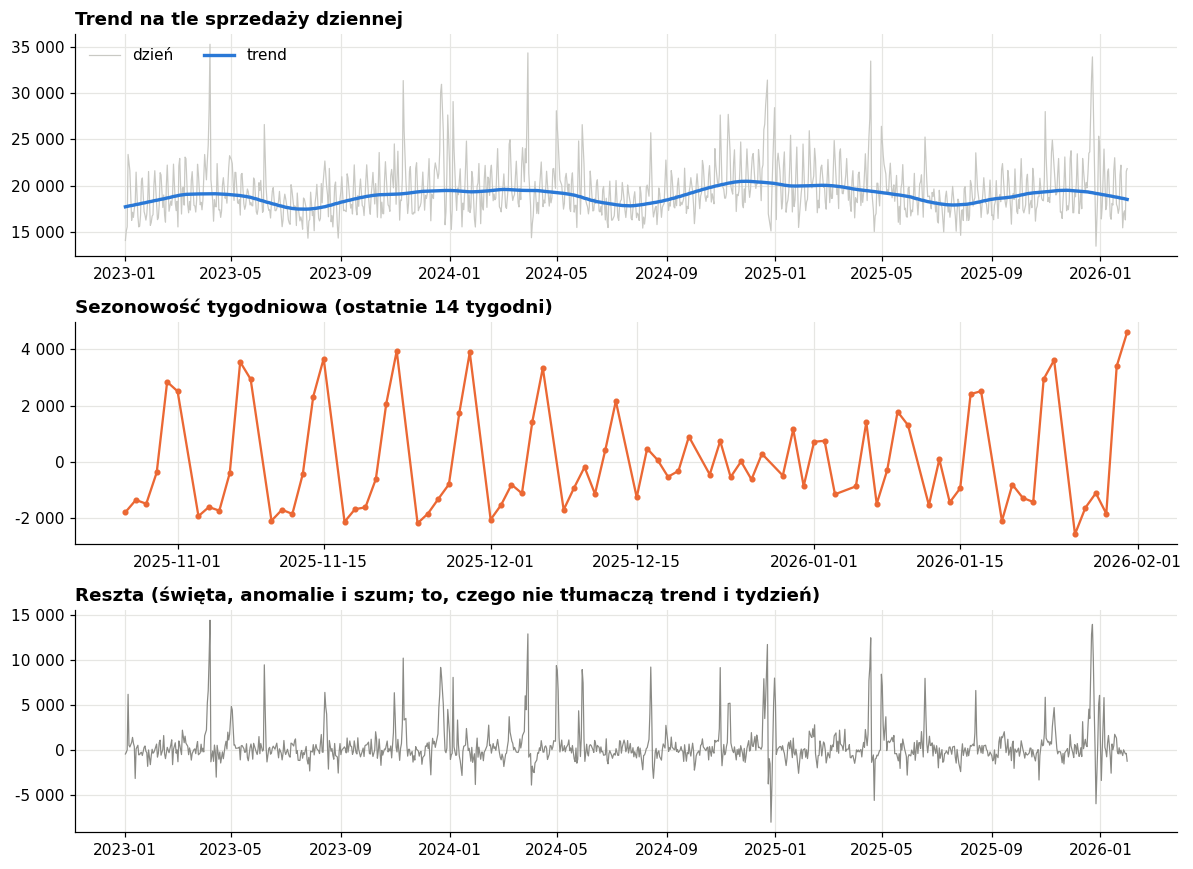

Udział w wariancji szeregu, %:
Trend       6.7
Tydzien    35.3
Reszta     57.5
Reszta: 83 % sumy kwadratów pochodzi z dni w okolicach świąt (±4 dni), a to 24 % dni
Wzorzec tygodniowy (średnia składnika wg dnia tygodnia), zł:
Data
Pn   -1134.0
Wt    -876.0
Śr   -1372.0
Cz    -889.0
Pt    1753.0
So    2517.0


In [19]:
# Dekompozycja STL: trend (z wolnymi zmianami rocznymi) + sezonowość tygodniowa (6 dni) + reszta
# Sezonowości rocznej nie wydzielamy: przy 3 latach danych byłyby tylko 3 powtórzenia roku i model by się "przeuczył".
y = pd.Series(ts_i.values)                       # indeks całkowity: statsmodels wymaga regularnych kroków
res = STL(y, period=6, seasonal=7, trend=79, robust=True).fit()   # trend=79 dni handlowych ≈ 13 tygodni
dek = pd.DataFrame({
    "Obserwacja": ts_i.values,
    "Trend": res.trend.values,
    "Tydzien": res.seasonal.values,
    "Reszta": res.resid.values,
}, index=ts_i.index)

fig, axs = plt.subplots(3, 1, figsize=(11, 8))
axs[0].plot(dek.index, dek["Obserwacja"], color="#c9c9c4", lw=0.8, label="dzień")
axs[0].plot(dek.index, dek["Trend"], color=NIEB, lw=2.2, label="trend")
axs[0].set_title("Trend na tle sprzedaży dziennej")
axs[0].legend(frameon=False, ncol=2, loc="upper left")
axs[1].plot(dek.index[-84:], dek["Tydzien"].iloc[-84:], color=POM, lw=1.5, marker="o", ms=3)
axs[1].set_title("Sezonowość tygodniowa (ostatnie 14 tygodni)")
axs[2].plot(dek.index, dek["Reszta"], color=SZARY, lw=0.8)
axs[2].set_title("Reszta (święta, anomalie i szum; to, czego nie tłumaczą trend i tydzień)")
for ax in axs: ax.yaxis.set_major_formatter(zl)
plt.tight_layout(); plt.show()

# Ile zmienności tłumaczy każdy składnik (wariancja składnika / wariancja szeregu; nie sumują się do 100 %)
udzial = (dek[["Trend", "Tydzien", "Reszta"]].var() / dek["Obserwacja"].var() * 100).round(1)
print("Udział w wariancji szeregu, %:"); print(udzial.to_string())
bl = dz.loc[dek.index, "BliskoSwieta"].values
print(f"Reszta: {(dek['Reszta'][bl]**2).sum() / (dek['Reszta']**2).sum() * 100:.0f} % sumy kwadratów pochodzi z dni w okolicach świąt (±4 dni), a to {bl.mean()*100:.0f} % dni")
print("Wzorzec tygodniowy (średnia składnika wg dnia tygodnia), zł:")
print(dek.groupby(dek.index.dayofweek)["Tydzien"].mean().round(0).rename(index=dict(enumerate(DNI))).to_string())

#### Objaśnienie: autokorelacja (ACF)
**Po co ta komórka.** Sprawdzamy, czy sprzedaż „pamięta” swoją przeszłość, czyli czy dzisiejsza wartość jest podobna do wartości sprzed kilku dni.

**Pojęcia.**
- **Opóźnienie (lag)** to liczba kroków wstecz. Lag 1 to poprzedni dzień handlowy, lag 6 to ten sam dzień tygodnia tydzień wcześniej.
- **Autokorelacja** to korelacja szeregu z jego własną przesuniętą kopią. Przyjmuje wartości od −1 do 1. Blisko 1 oznacza, że wartości odległe o dany lag są do siebie podobne. Blisko 0 oznacza brak związku.
- **ACF** to wykres autokorelacji dla kolejnych lagów.

**Jak czytać wykres.**
- Każdy słupek to autokorelacja dla jednego lagu.
- Niebieskie pasmo wokół zera to granica przypadku. Słupek wystający poza pasmo oznacza zależność istotną statystycznie.
- Pomarańczowe linie przerywane zaznaczają lag 6 i 12, czyli jeden i dwa tygodnie.

**Lewy wykres (surowy szereg).** Słupki przy lagach 6, 12, 18, 24 wyraźnie wystają (około 0,3–0,4), a między nimi autokorelacja spada w okolice zera. Sprzedaż jest więc podobna do sprzedaży z tego samego dnia tygodnia tydzień, dwa i trzy tygodnie wcześniej. To potwierdzenie sezonowości tygodniowej. Wysoki jest też lag 1 (około 0,5): dzień jest podobny do dnia poprzedniego.

**Prawy wykres (reszta po dekompozycji).** Po usunięciu trendu i tygodnia słupki przy lagach 6 i 12 znikają, czyli dekompozycja wyciągnęła z szeregu cały rytm tygodnia. Zostają dwa wyraźne słupki: lag 1 (około 0,5) i lag 2 (około 0,2). Oznacza to, że odchylenia od normy trwają po kilka dni z rzędu: jeśli wczoraj sprzedaż była powyżej oczekiwań, dziś zwykle też jest. Tak wyglądają kilkudniowe fale wokół świąt.

**Zastosowanie.** ACF podpowiada, które opóźnienia warto dać modelowi jako cechy. Tutaj są to wielokrotności tygodnia, dlatego w sekcji 7 powstają kolumny `lag7`, `lag14`, `lag21`, `lag28` (w dniach kalendarzowych tydzień to 7 dni, a w tym szeregu bez niedziel 6 kroków).

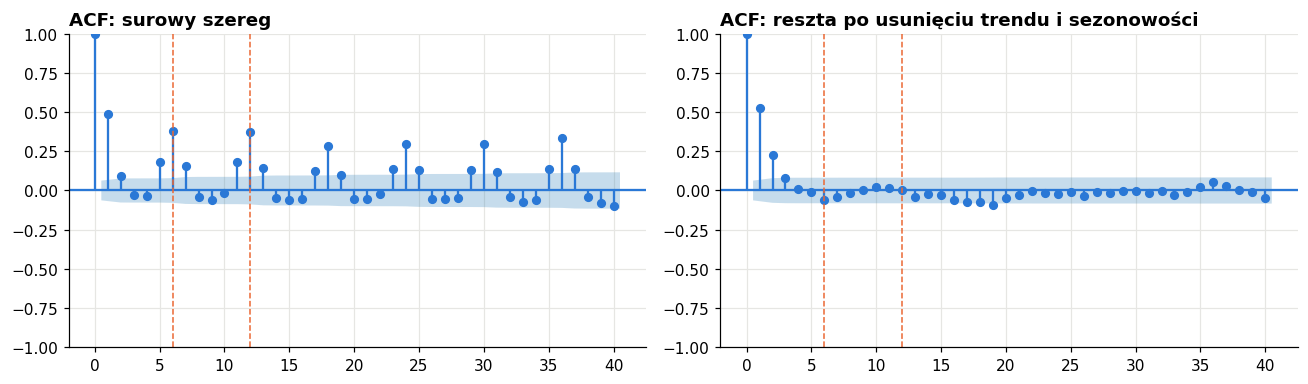

In [20]:
# Autokorelacja: surowy szereg i reszta po dekompozycji (kroki = dni handlowe Pn-So, tydzień = lag 6)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
plot_acf(ts_i.values, lags=40, ax=axs[0], color=NIEB, vlines_kwargs={"colors": NIEB})
axs[0].set_title("ACF: surowy szereg")
plot_acf(dek["Reszta"].values, lags=40, ax=axs[1], color=NIEB, vlines_kwargs={"colors": NIEB})
axs[1].set_title("ACF: reszta po usunięciu trendu i sezonowości")
for ax in axs:
    ax.axvline(6, color=POM, ls="--", lw=1); ax.axvline(12, color=POM, ls="--", lw=1)
plt.tight_layout(); plt.show()

### Stacjonarność i PACF
Szereg stacjonarny ma stałą średnią i wariancję w czasie. Sprawdzamy to dwoma testami o odwrotnych hipotezach:
- **ADF**: hipoteza zerowa to *brak* stacjonarności. p < 0,05 przemawia za stacjonarnością.
- **KPSS**: hipoteza zerowa to stacjonarność. p < 0,05 przemawia *przeciw* stacjonarności.

Szereg uznajemy za stacjonarny, gdy oba testy się zgadzają (ADF p < 0,05 i KPSS p ≥ 0,05). Badamy trzy wersje: surowy szereg, różnicę tygodniową (dzień minus ten sam dzień tydzień wcześniej, czyli 6 dni handlowych) i resztę po dekompozycji STL. **PACF** pokazuje korelację z opóźnieniem po odjęciu wpływu opóźnień pośrednich.

#### Objaśnienie: stacjonarność i PACF
**Po co ta komórka.** Wiele klasycznych modeli (np. ARIMA) zakłada, że szereg jest **stacjonarny**. Sprawdzamy to testami statystycznymi.

**Stacjonarność prostymi słowami.** Szereg jest stacjonarny, gdy „wygląda tak samo” w każdym okresie: ma stałą średnią, stały rozrzut i brak trendu. Szereg, który stale rośnie, nie jest stacjonarny, bo jego średnia zmienia się w czasie.

**Wartość p.** Każdy test zwraca liczbę p od 0 do 1. Mała wartość (poniżej 0,05) oznacza, że dane przeczą hipotezie zerowej testu, więc ją odrzucamy.

**Dwa testy o odwrotnych hipotezach.**
- **ADF**: hipoteza zerowa to „szereg jest niestacjonarny”. Małe p przemawia *za* stacjonarnością.
- **KPSS**: hipoteza zerowa to „szereg jest stacjonarny”. Małe p przemawia *przeciw* stacjonarności.

Stosujemy oba, bo każdy może się mylić. Wniosek jest pewny, gdy się zgadzają.

**Co robi kod.**
- `testy_stacjonarnosci(x)` liczy oba p i wpisuje wniosek słowami.
- `ts_i.diff(6)` to **różnicowanie sezonowe**: od każdego dnia odejmujemy ten sam dzień tydzień wcześniej. To standardowy sposób usuwania sezonowości i trendu.
- Badamy trzy wersje: szereg surowy, różnicę tygodniową i resztę po STL.
- `warnings.simplefilter("ignore")` wycisza komunikat, który pojawia się, gdy p wypada poza tablicami testu (wtedy podawane jest 0,01 albo 0,10).

**PACF (autokorelacja cząstkowa).** Zwykła ACF dla lagu 12 zawiera w sobie wpływ lagu 6 (bo dziś zależy od zeszłego tygodnia, a zeszły tydzień od jeszcze wcześniejszego). PACF pokazuje *bezpośredni* związek z danym lagiem po odjęciu wpływu lagów pośrednich. Wysoki słupek przy lagu 6 i niskie przy 12 i 18 oznaczają, że wystarczy pamiętać jeden tydzień wstecz.

**Jak czytać wynik.** W tabeli patrz na kolumnę `Wniosek`. Na wykresach PACF szukaj słupków wystających poza niebieskie pasmo.

                   ADF_p  KPSS_p          Wniosek
surowy szereg        0.0  0.0405  testy niezgodne
różnica tygodniowa   0.0     0.1      stacjonarny
reszta po STL        0.0     0.1      stacjonarny


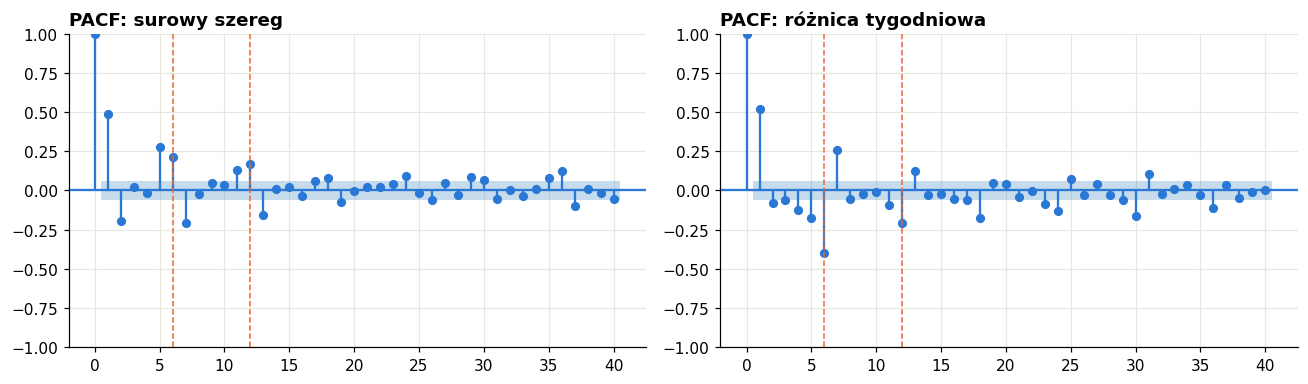

In [21]:
# Krok 3: testy stacjonarności (ADF, KPSS) i PACF
import warnings
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_pacf

def testy_stacjonarnosci(x):
    x = pd.Series(np.asarray(x, dtype=float)).dropna()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")          # KPSS ostrzega, gdy p wychodzi poza tablice (podaje wtedy 0,01 lub 0,10)
        p_adf = adfuller(x, autolag="AIC")[1]
        p_kpss = kpss(x, regression="c", nlags="auto")[1]
    if p_adf < 0.05 and p_kpss >= 0.05:   wniosek = "stacjonarny"
    elif p_adf >= 0.05 and p_kpss < 0.05: wniosek = "niestacjonarny"
    else:                                  wniosek = "testy niezgodne"
    return pd.Series({"ADF_p": round(p_adf, 4), "KPSS_p": round(p_kpss, 4), "Wniosek": wniosek})

roznica_tyg = ts_i.diff(6)                       # różnica tygodniowa: 6 dni handlowych Pn-So
st = pd.DataFrame({
    "surowy szereg": testy_stacjonarnosci(ts_i),
    "różnica tygodniowa": testy_stacjonarnosci(roznica_tyg),
    "reszta po STL": testy_stacjonarnosci(dek["Reszta"]),
}).T
print(st.to_string())

fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
plot_pacf(ts_i.values, lags=40, ax=axs[0], method="ywm", color=NIEB, vlines_kwargs={"colors": NIEB})
axs[0].set_title("PACF: surowy szereg")
plot_pacf(roznica_tyg.dropna().values, lags=40, ax=axs[1], method="ywm", color=NIEB, vlines_kwargs={"colors": NIEB})
axs[1].set_title("PACF: różnica tygodniowa")
for ax in axs:
    ax.axvline(6, color=POM, ls="--", lw=1); ax.axvline(12, color=POM, ls="--", lw=1)
plt.tight_layout(); plt.show()

### Baseline (punkt odniesienia dla modelu)
Prosta prognoza „ten sam dzień tygodnia w poprzednich tygodniach”, liczona tylko z przeszłości. Ostatnie 13 tygodni danych to zbiór testowy. Każdy model uczący się będzie musiał dać lepszy wynik niż te dwie metody.

#### Objaśnienie: punkt odniesienia (baseline) i pomiar błędu
**Po co ta komórka.** Zanim zbudujemy jakikolwiek model, sprawdzamy, jak dobrze prognozują metody banalne. To jest **baseline**, czyli poprzeczka. Model, który jej nie przeskoczy, jest niepotrzebny, niezależnie od tego, jak jest skomplikowany.

**Dwie proste prognozy.**
- **Tydzień temu**: jutro sprzedamy tyle, ile w ten sam dzień tygodnia tydzień wcześniej. `s_h.shift(7)` przesuwa szereg o 7 dni, więc w wierszu danej daty pojawia się wartość sprzed tygodnia.
- **Średnia z 4 tygodni**: średnia z tego samego dnia tygodnia z czterech poprzednich tygodni. `pd.concat([...], axis=1).mean(axis=1)` skleja cztery przesunięte kolumny i uśrednia je wierszami, pomijając braki.

Linijka `dz["Wartosc"].where(dz["Handlowy"])` zamienia dni zamknięte na `NaN`. Dzięki temu zero ze święta nie trafia do średniej jako „bardzo słaby dzień”.

**Zbiór testowy.** Ostatnie 13 tygodni (91 dni) odkładamy do oceny. W szeregach czasowych podział jest zawsze **chronologiczny**: oceniamy na okresie późniejszym niż ten, z którego pochodzi prognoza. Losowy podział pozwoliłby „podglądać przyszłość”.

**Trzy miary błędu.**
- **MAE**: średni błąd bezwzględny w złotówkach. „Mylimy się średnio o tyle złotych dziennie”.
- **WAPE**: suma błędów podzielona przez sumę sprzedaży, w procentach. Dni o dużej sprzedaży ważą więcej.
- **MAPE**: średni błąd procentowy. Każdy dzień waży tyle samo.

**Jak czytać wynik.** Na wszystkich 66 dniach obie metody mylą się o około 12% (około 2400 zł dziennie). Po rozbiciu widać dwie różne sytuacje:
- **Poza okolicami świąt** (46 dni) wygrywa „tydzień temu”: 6,6% wobec 9,9%.
- **W okolicach świąt** (20 dni) wygrywa średnia: 15,8% wobec 22,9%. Pojedynczy tydzień bywa nietypowy, a uśrednienie czterech łagodzi takie wyskoki.

**Wniosek.** Zwykłe dni są łatwe (błąd około 7%). Cały problem prognozowania tego sklepu siedzi w okolicach świąt.

Zbiór testowy: 2025-11-03 … 2026-01-31, dni: 66

wszystkie dni (dni: 66)
        Tydzien_temu  Srednia_4_tygodni
MAE_zl        2392.0             2362.9
WAPE_%          11.9               11.8
MAPE_%          11.7               11.7

poza okolicami świąt (dni: 46)
        Tydzien_temu  Srednia_4_tygodni
MAE_zl        1276.4             1905.1
WAPE_%           6.6                9.9
MAPE_%           6.8               10.2

okolice świąt (dni: 20)
        Tydzien_temu  Srednia_4_tygodni
MAE_zl        4957.7             3415.7
WAPE_%          22.9               15.8
MAPE_%          22.8               15.1


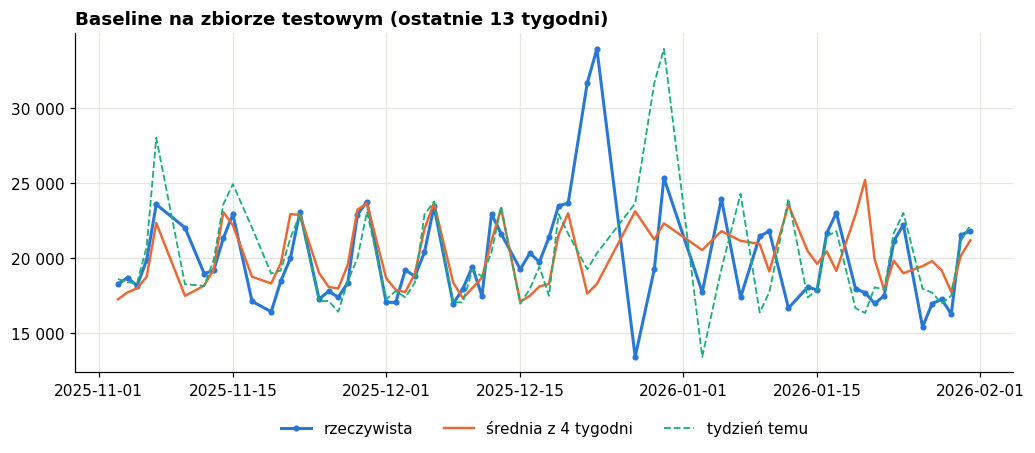

In [ ]:
# Dwa proste baseline'y: (1) dokładnie tydzień wcześniej, (2) średnia z 4 poprzednich tygodni tego dnia tygodnia
s_h = dz["Wartosc"].where(dz["Handlowy"])               # dni zamknięte = brak (nie zero)
pred_t1 = s_h.shift(7)# 1) tydzień wcześniej
pred_t4 = pd.concat([s_h.shift(7 * k) for k in range(1, 5)], axis=1).mean(axis=1) # 2) średnia z 4 tygodni wcześniej

TEST_DNI = 91
koniec = dz.index.max()
test_idx = dz.index[(dz.index > koniec - pd.Timedelta(days=TEST_DNI)) & dz["Handlowy"] & (dz["DzienTyg"] < 6)]
tab = pd.DataFrame({"Rzeczywista": s_h.loc[test_idx], "Tydzien_temu": pred_t1.loc[test_idx], "Srednia_4_tygodni": pred_t4.loc[test_idx]}).dropna()
tab["Okolice_swiat"] = dz.loc[tab.index, "BliskoSwieta"]

def metryki(t, kol):
    e = t[kol] - t["Rzeczywista"]
    return pd.Series({"MAE_zl": e.abs().mean(), "WAPE_%": e.abs().sum() / t["Rzeczywista"].sum() * 100, "MAPE_%": (e.abs() / t["Rzeczywista"]).mean() * 100})

print(f"Zbiór testowy: {tab.index.min().date()} … {tab.index.max().date()}, dni: {len(tab)}")
for nazwa, t in [("wszystkie dni", tab), ("poza okolicami świąt", tab[~tab["Okolice_swiat"]]), ("okolice świąt", tab[tab["Okolice_swiat"]])]:
    print(f"\n{nazwa} (dni: {len(t)})")
    print(pd.DataFrame({k: metryki(t, k) for k in ["Tydzien_temu", "Srednia_4_tygodni"]}).round(1).to_string())

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(tab.index, tab["Rzeczywista"], color=NIEB, lw=2, marker="o", ms=3, label="rzeczywista")
ax.plot(tab.index, tab["Srednia_4_tygodni"], color=POM, lw=1.6, label="średnia z 4 tygodni")
ax.plot(tab.index, tab["Tydzien_temu"], color=MOR, lw=1.2, ls="--", label="tydzień temu")
ax.yaxis.set_major_formatter(zl)
ax.set_title("Baseline na zbiorze testowym (ostatnie 13 tygodni)")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.show()

### Model: Holt-Winters a punkt odniesienia
Kroki 4-6 na jednym modelu. **Holt-Winters** (wygładzanie wykładnicze z trendem i sezonowością tygodniową) uczy się na pełnym szeregu dziennym, razem z dniami zamkniętymi (sprzedaż 0), bo wymaga równych odstępów. Punkt odniesienia to średnia z tego samego dnia tygodnia z 48 ostatnich dni otwartych.

Ocena jest kroczącą walidacją w czasie: 6 okien po 28 dni, w każdym model widzi tylko dane sprzed okna. W dni zamknięte obie prognozy ustawiamy na 0 (kalendarz znamy z góry), a błąd liczymy tylko z dni otwartych. Kolumna `HW_lepszy` pokazuje, czy model wygrał z punktem odniesienia.

#### Objaśnienie: pierwszy prawdziwy model i uczciwa walidacja
**Po co ta komórka.** Budujemy klasyczny model prognostyczny i sprawdzamy, czy wygrywa z punktem odniesienia. To pełny cykl pracy z szeregiem czasowym: podział, model, prognoza, pomiar błędu.

**Model Holta-Wintersa.** Inaczej: potrójne wygładzanie wykładnicze. Model śledzi trzy rzeczy i każdą aktualizuje po każdym nowym dniu:
- **poziom**: ile sprzedajemy „teraz”,
- **trend**: czy poziom rośnie, czy spada (`trend="add"`),
- **sezon**: poprawka dla każdego dnia tygodnia (`seasonal="add"`, `seasonal_periods=7`).

„Wykładnicze” oznacza, że nowsze obserwacje ważą więcej niż starsze. „add” oznacza model addytywny: składniki się dodaje.

**Walidacja krocząca (walk-forward).** Jedno okno testowe to za mało, bo wynik może być przypadkowy. Powtarzamy więc ocenę 6 razy na kolejnych oknach po 28 dni:
1. `ucz` to wszystko przed oknem, `tst` to 28 dni okna (krok 4),
2. model uczy się tylko na `ucz` i prognozuje 28 dni naprzód (krok 5),
3. liczymy błąd na `tst` (krok 6).

Model nigdy nie widzi danych z okresu, na którym jest oceniany.

**Wykorzystanie kalendarza.** `.where(~zt, 0)` ustawia prognozę na 0 w dni zamknięte. Wiemy z góry, kiedy sklep nie pracuje, więc nie każemy modelowi tego zgadywać. Błąd liczymy tylko z dni otwartych (`[~zt]`).

**Punkt odniesienia.** Średnia z tego samego dnia tygodnia z 48 ostatnich dni otwartych (około 8 tygodni).

**Jak czytać wynik.** Każdy wiersz tabeli to jedno okno. `HW_%` i `srednia_dnia_%` to błąd jako procent średniej sprzedaży dziennej. Kolumna `HW_lepszy` mówi, czy model wygrał. Ostatnia linijka podsumowuje wszystkie okna.

**Czego się spodziewać.** Na danych tego sklepu, liczonych w sztukach, Holt-Winters nie wygrał z prostą średnią w żadnym z sześciu okien. To częsta i ważna lekcja: bardziej złożony model nie musi być lepszy, a bez porównania z baseline'em nie da się tego stwierdzić.

            MAE_HW_zl  MAE_srednia_dnia_zl  HW_%  srednia_dnia_%  HW_lepszy
okno_od                                                                    
2025-08-17     1232.4                893.9   6.9             5.0      False
2025-09-14     1052.7               1033.6   5.6             5.5      False
2025-10-12     1396.3               1474.1   7.1             7.5       True
2025-11-09     1416.4                982.3   7.2             5.0      False
2025-12-07     4297.4               4366.2  22.2            22.5       True
2026-01-04     1595.6               1965.7   8.7            10.7       True

Średnio z 6 okien: Holt-Winters 9.6 %, średnia dnia tygodnia 9.4 % | Holt-Winters lepszy w 3 z 6 okien


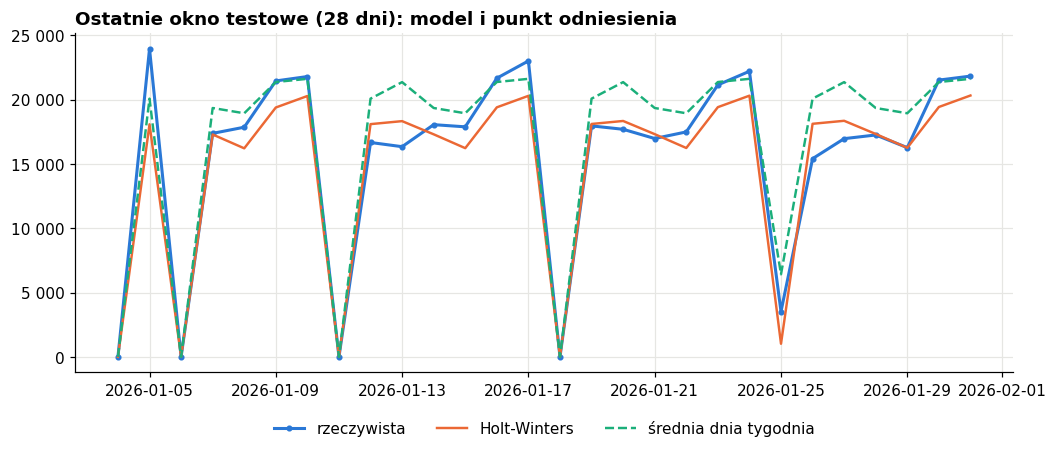

In [23]:
# Kroki 4-6: podział chronologiczny, model Holta-Wintersa, punkt odniesienia i porównanie błędów
import warnings
from statsmodels.tsa.holtwinters import ExponentialSmoothing

y_hw = dz["Wartosc"].astype(float)               # pełny szereg dzienny (dni zamknięte = 0)
zamk_hw = dz["Zamkniety"]                        # True = sklep zamknięty
H_HW, OKNA_HW = 28, 6
wiersze_hw, ostatnie = [], None
for k in range(OKNA_HW):
    kon = len(y_hw) - k * H_HW
    ucz, tst = y_hw.iloc[:kon - H_HW], y_hw.iloc[kon - H_HW:kon]          # krok 4: przeszłość / przyszłość
    zt = zamk_hw.reindex(tst.index)

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m_hw = ExponentialSmoothing(ucz, trend="add", seasonal="add", seasonal_periods=7).fit()   # krok 5: model
    p_hw = pd.Series(np.asarray(m_hw.forecast(H_HW)), index=tst.index).where(~zt, 0)

    otw = ucz[~zamk_hw.reindex(ucz.index)].iloc[-48:]                      # krok 5: punkt odniesienia
    sr_dnia = otw.groupby(otw.index.dayofweek).mean()
    p_sr = pd.Series(tst.index.dayofweek.map(sr_dnia), index=tst.index).fillna(0).where(~zt, 0)

    mae_hw = (tst - p_hw)[~zt].abs().mean()                                # krok 6: błędy na dniach otwartych
    mae_sr = (tst - p_sr)[~zt].abs().mean()
    srednia = tst[~zt].mean()
    wiersze_hw.append({"okno_od": tst.index[0].date(), "MAE_HW_zl": mae_hw, "MAE_srednia_dnia_zl": mae_sr,
                       "HW_%": 100 * mae_hw / srednia, "srednia_dnia_%": 100 * mae_sr / srednia,
                       "HW_lepszy": bool(mae_hw < mae_sr)})
    if k == 0:
        ostatnie = (tst, p_hw, p_sr)

por_hw = pd.DataFrame(wiersze_hw[::-1]).set_index("okno_od")
print(por_hw.round(1).to_string())
print(f"\nŚrednio z {OKNA_HW} okien: Holt-Winters {por_hw['HW_%'].mean():.1f} %, średnia dnia tygodnia {por_hw['srednia_dnia_%'].mean():.1f} %"
      f" | Holt-Winters lepszy w {int(por_hw['HW_lepszy'].sum())} z {OKNA_HW} okien")

tst, p_hw, p_sr = ostatnie
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(tst.index, tst.values, color=NIEB, lw=2, marker="o", ms=3, label="rzeczywista")
ax.plot(tst.index, p_hw.values, color=POM, lw=1.6, label="Holt-Winters")
ax.plot(tst.index, p_sr.values, color=MOR, lw=1.6, ls="--", label="średnia dnia tygodnia")
ax.yaxis.set_major_formatter(zl)
ax.set_title("Ostatnie okno testowe (28 dni): model i punkt odniesienia")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.show()

#### Objaśnienie: wykrywanie dni nietypowych
**Po co ta komórka.** Szukamy dni, w których sprzedaż wyraźnie odbiega od tego, co wynika z trendu i rytmu tygodnia. Takie dni nazywamy **anomaliami**.

**Pomysł.** Reszta z dekompozycji STL to „sprzedaż minus to, czego się spodziewaliśmy”. Dzień z bardzo dużą resztą (dodatnią lub ujemną) jest nietypowy.

**Jak zdecydować, co znaczy „bardzo duża”.** Klasyczny sposób to z-score: o ile odchyleń standardowych wartość leży od średniej. Ma jednak wadę: same anomalie zawyżają odchylenie standardowe i przez to się maskują. Używamy więc wersji odpornej:
- zamiast średniej bierzemy **medianę**,
- zamiast odchylenia standardowego bierzemy **MAD**, czyli medianę bezwzględnych odchyleń od mediany,
- stała `0,6745` przelicza MAD tak, żeby wynik był porównywalny ze zwykłym z-score.

Próg `3,5` to powszechnie stosowana wartość dla tej metody.

**Co robi kod.**
- `z = 0.6745 * (r - r.median()) / mad` to zmodyfikowany z-score dla każdego dnia.
- `anom[~anom["Uzupelniony"]]` usuwa dni, które były uzupełnione interpolacją. To nie są prawdziwe dane, więc nie mogą być anomaliami.
- Funkcja `opisz(d)` z sekcji o dniach rekordowych dopisuje najbliższe święto.

**Jak czytać wynik.** Znaleziono 69 dni nietypowych na 931. Ujemne `z` to dni słabsze od oczekiwań, dodatnie lepsze. Najsłabsze są dni tuż po świętach (27 grudnia, wtorek po Wielkanocy), a najlepsze dni tuż przed świętami. Przy większości anomalii kolumna `Okolice` nie jest pusta.

**Wniosek.** Większość „anomalii” to nie błędy w danych ani losowe zdarzenia, tylko efekt świąt. Dni z pustą kolumną `Okolice` warto sprawdzić osobno: mogła to być promocja, awaria, pogoda albo lokalne wydarzenie.

In [24]:
# Anomalie: dni z dużą resztą po dekompozycji (modyfikowany z-score na MAD, próg 3,5)
r = dek["Reszta"]
mad = (r - r.median()).abs().median()
z = 0.6745 * (r - r.median()) / mad
anom = dek.loc[z.abs() > 3.5, ["Obserwacja", "Reszta"]].copy()
anom["z"] = z[anom.index].round(1)
anom["DzienTyg"] = [DNI[i] for i in anom.index.dayofweek]
anom["Uzupelniony"] = ts.isna().reindex(anom.index)
anom = anom[~anom["Uzupelniony"]].drop(columns="Uzupelniony")   # dni uzupełnione interpolacją nie są prawdziwymi danymi
anom["Okolice"] = [opisz(d) for d in anom.index]          # opisz() z komórki z dniami rekordowymi
print(f"Dni z |z| > 3,5 (bez uzupełnionych): {len(anom)} z {len(r) - n_braki}")
print(anom.sort_values("z").round(0).to_string())

Dni z |z| > 3,5 (bez uzupełnionych): 69 z 931
            Obserwacja   Reszta     z DzienTyg                                          Okolice
Data                                                                                           
2024-12-27     15077.0  -8061.0  -9.0       Pt           Boże Narodzenie (drugi dzień) (-1 dni)
2025-12-27     13421.0  -6004.0  -7.0       So           Boże Narodzenie (drugi dzień) (-1 dni)
2025-04-22     15014.0  -5632.0  -7.0       Wt                Poniedziałek Wielkanocny (-1 dni)
2024-12-28     19278.0  -4123.0  -5.0       So           Boże Narodzenie (drugi dzień) (-2 dni)
2024-04-02     14339.0  -3921.0  -5.0       Wt                Poniedziałek Wielkanocny (-1 dni)
2024-12-24     16926.0  -3797.0  -4.0       Wt        Boże Narodzenie (pierwszy dzień) (+1 dni)
2024-01-30     15501.0  -3860.0  -4.0       Wt                                                 
2025-10-24     18792.0  -3358.0  -4.0       Pt                                            

## 7. Cechy dla modelu: przygotowanie
Budujemy tu tylko to, co model będzie mógł znać **w chwili prognozy**, czyli bez wycieku przyszłości (zapis do jednego pliku jest w sekcji 15, po części o klasach):
- cechy kalendarzowe i świąteczne (tabela `kal`), także na dni po końcu danych (do końca roku 2026), bo święta znamy z góry,
- sprzedaż dzienna sklepu (cel prognozy) i opóźnienia liczone wyłącznie z przeszłości (tabela `dz_model`),
- `baseline_metryki.csv`: wyniki prostych metod, które model musi pobić (to raport, nie cechy).

Celowo **nie zapisujemy** trendu, reszty z STL, wskaźnika wokół świąt ani indeksu sezonowości: liczone były na całych danych (także na przyszłości względem dnia prognozy), więc użyte jako cechy dałyby zawyżone wyniki na testach.

#### Objaśnienie: inżynieria cech kalendarzowych
**Po co ta komórka.** Model uczenia maszynowego nie rozumie dat. Trzeba mu podać informacje z daty w postaci liczb. Przygotowanie takich kolumn nazywa się **inżynierią cech** (feature engineering).

**Cecha** to jedna kolumna, którą model dostaje na wejściu, np. „dzień tygodnia” albo „ile dni do święta”.

**Najważniejsza zasada.** Cechą może być tylko to, co **znamy w chwili robienia prognozy**. Kalendarz znamy na lata naprzód, więc tabela `kal` sięga do końca 2026 roku, choć dane sprzedaży kończą się w styczniu.

**Grupy cech.**
- **Podstawowe**: rok, miesiąc, dzień miesiąca, dzień tygodnia, tydzień roku, dzień roku.
- **Święta**: `CzySwieto` (0 lub 1) i nazwa święta.
- **Odległość od świąt**: `DniDoSwieta`, `DniOdSwieta`, `DzienPrzedSwietem`, `DzienPoSwiecie`, `BliskoSwieta`. Wcześniejsze sekcje pokazały, że sprzedaż rośnie na kilka dni przed świętem, więc sama flaga święta nie wystarcza.
- **Duże sezony**: `DniDoWielkanocy` i `DniDoBozegoNarodzenia`. Wielkanoc jest ruchoma, więc numer miesiąca jej nie wyznacza.
- **Otwarcie sklepu**: `CzyOtwarty` (z danych, znane tylko dla przeszłości) i `CzyOtwartyRegula` (z reguły: Pn–So poza świętami, znane zawsze).

**Co robi kod (trudniejsze miejsca).**
- `np.searchsorted(sw_idx.values, dni.values)` dla każdego dnia znajduje pozycję najbliższego święta, które dopiero nastąpi. To szybki sposób wyszukiwania w posortowanej liście.
- Święta pobieramy także z roku przed i po zakresie kalendarza. Bez tego dla 27–31 grudnia 2026 nie ma „następnego święta” i `DniDoSwieta` wychodziło 0, jakby to było święto.
- `DniDoBozegoNarodzenia` na początku stycznia jest ujemne (np. −7 dla 1 stycznia), bo liczymy od ostatnich świąt, a nie do świąt za prawie rok.
- `np.clip(x, 0, 30)` obcina wartości do przedziału 0–30. Dla sprzedaży nie ma znaczenia, czy do święta jest 40, czy 60 dni, a obcięcie upraszcza modelowi zadanie.
- `.astype("int8")` zapisuje małe liczby całkowite w jednym bajcie, co oszczędza pamięć.
- `.where(dni <= ost_dane)` wstawia `NaN` dla dni po końcu danych tam, gdzie informacji nie mamy (np. lista niedziel handlowych na dalszą część 2026).

**Jak czytać wynik.** Tabela ma 1461 wierszy (4 lata po dniu) i 19 kolumn. Wydruk pokazuje tydzień wokół Wielkanocy 2025: w kolejnych wierszach `DniDoSwieta` maleje, a `DniDoWielkanocy` odlicza dni do niedzieli wielkanocnej.

In [25]:
# Cechy kalendarzowe i świąteczne (znane z góry, także dla dni po końcu danych)
OSTATNI_DZIEN = pd.Timestamp("2026-12-31")
dni = pd.date_range("2023-01-01", OSTATNI_DZIEN, freq="D")   # od początku kalendarza (1 stycznia 2023)
# święta także z roku przed i po zakresie: inaczej 27-31.12 ostatniego roku nie mają „następnego święta”
# (DniDoSwieta wychodziło 0), a 31.12 nie jest oznaczony jako dzień przed Nowym Rokiem
sw_all = swieta_polska(range(dni.year.min() - 1, dni.year.max() + 2))
sw_idx = pd.DatetimeIndex(sorted(pd.Timestamp(d) for d in sw_all))
sw_nazwa = {pd.Timestamp(d): n for d, n in sw_all.items()}
wielkanoc = {y: pd.Timestamp(easter(y)) for y in dni.year.unique()}

kal = pd.DataFrame(index=dni); kal.index.name = "Data"
kal["Rok"] = dni.year.astype("int16")
kal["Miesiac"] = dni.month.astype("int8")
kal["DzienMiesiaca"] = dni.day.astype("int8")
kal["DzienTyg"] = dni.dayofweek.astype("int8")
kal["TydzienRoku"] = dni.isocalendar().week.values.astype("int8")
kal["DzienRoku"] = dni.dayofyear.astype("int16")
kal["CzySwieto"] = dni.isin(sw_idx).astype("int8")
kal["NazwaSwieta"] = pd.Series(dni.map(lambda d: sw_nazwa.get(d, "")), index=dni)

# odległość (w dniach) do następnego i od poprzedniego święta (ograniczona do 30)
poz = np.searchsorted(sw_idx.values, dni.values)                       # indeks następnego święta (>= data)
nast = sw_idx.values[np.minimum(poz, len(sw_idx) - 1)]
poprz = sw_idx.values[np.maximum(poz - 1, 0)]
kal["DniDoSwieta"] = np.clip((nast - dni.values).astype("timedelta64[D]").astype(int), 0, 30).astype("int8")
kal["DniOdSwieta"] = np.clip((dni.values - poprz).astype("timedelta64[D]").astype(int), 0, 30).astype("int8")
kal["DzienPrzedSwietem"] = dni.map(lambda d: int((d + pd.Timedelta(days=1)) in sw_nazwa)).astype("int8")
kal["DzienPoSwiecie"] = dni.map(lambda d: int((d - pd.Timedelta(days=1)) in sw_nazwa)).astype("int8")
kal["BliskoSwieta"] = ((kal["DniDoSwieta"] <= 4) | (kal["DniOdSwieta"] <= 4)).astype("int8")

# święta ruchome i duże sezony: dni do Wielkanocy i do Bożego Narodzenia (ze znakiem, ograniczone)
kal["DniDoWielkanocy"] = np.clip([(wielkanoc[d.year] - d).days for d in dni], -30, 30).astype("int8")
# Boże Narodzenie: do świąt tego roku, a na początku stycznia (od świąt minęło mniej niż 14 dni) — od poprzednich
def dni_do_bn(d):
    do = (pd.Timestamp(d.year, 12, 25) - d).days
    od_poprz = (pd.Timestamp(d.year - 1, 12, 25) - d).days          # ujemne
    return od_poprz if od_poprz >= -14 else do
kal["DniDoBozegoNarodzenia"] = np.clip([dni_do_bn(d) for d in dni], -14, 60).astype("int8")

# czy sklep otwarty: z danych dla dni do końca danych (dni po końcu danych = brak informacji)
ost_dane = dz.index.max()
otwarty = dz["Handlowy"].astype("int8").reindex(dni).fillna(0)   # dni bez wiersza w danych (np. 1 stycznia) = zamknięte
kal["CzyOtwarty"] = otwarty.where(dni <= ost_dane)                       # NaN dla przyszłości
# niedziela handlowa z kalendarza w pliku (z przepisów); NaN po końcu danych, bo listy na 2026 plik nie zawiera
kal["CzyNiedzielaHandlowa"] = kal_pq["CzyNiedzielaHandlowa"].reindex(dni).astype("float").where(dni <= ost_dane)
kal["CzyDlugiWeekend"] = kal_pq["CzyDlugiWeekend"].reindex(dni).astype("float").where(dni <= ost_dane)
kal["CzyOtwartyRegula"] = ((kal["DzienTyg"] < 6) & (kal["CzySwieto"] == 0)).astype("int8")   # reguła: Pn-So poza świętami

print(kal.shape, kal.index.min().date(), kal.index.max().date())
print(kal.loc["2025-04-16":"2025-04-22"].drop(columns=["Rok", "DzienRoku", "TydzienRoku"]).to_string())

(1461, 19) 2023-01-01 2026-12-31
            Miesiac  DzienMiesiaca  DzienTyg  CzySwieto               NazwaSwieta  DniDoSwieta  DniOdSwieta  DzienPrzedSwietem  DzienPoSwiecie  BliskoSwieta  DniDoWielkanocy  DniDoBozegoNarodzenia  CzyOtwarty  CzyNiedzielaHandlowa  CzyDlugiWeekend  CzyOtwartyRegula
Data                                                                                                                                                                                                                                                                     
2025-04-16        4             16         2          0                                      4           30                  0               0             1                4                     60         1.0                   0.0              0.0                 1
2025-04-17        4             17         3          0                                      3           30                  0               0             1             

#### Objaśnienie: zmienna celu i cechy opóźnione
**Po co ta komórka.** Do cech kalendarzowych dokładamy to, co model ma przewidywać, oraz informację o niedawnej sprzedaży.

**Pojęcia.**
- **Zmienna celu (target)** to wielkość, którą prognozujemy. Tutaj: `Wartosc`, czyli sprzedaż dnia.
- **Cecha opóźniona (lag)** to wartość celu sprzed określonej liczby dni. `Wartosc_lag7` to sprzedaż sprzed tygodnia.

**Gdzie są opóźnienia.** Same kolumny `lag` liczymy w sekcji 15, na pełnym kalendarzu do końca 2026. Tu tylko opisujemy pomysł.

**Dlaczego opóźnienia są tak przydatne.** Analiza ACF pokazała, że sprzedaż jest podobna do sprzedaży z tego samego dnia tygodnia w poprzednich tygodniach. Lag 7, 14, 21 i 28 to dokładnie ta informacja podana modelowi wprost.

**Dlaczego to nie jest wyciek danych.** `shift(7)` przesuwa wartości w dół o 7 wierszy. W wierszu z 31 stycznia pojawia się więc sprzedaż z 24 stycznia, którą w dniu prognozy już znamy. Gdybyśmy użyli `shift(-7)` (przesunięcie w górę), model dostałby dane z przyszłości.

**Co robi kod.**
- `s_h = dz["Wartosc"].where(dz["Handlowy"])` zamienia dni zamknięte na brak. Opóźnienie „sprzed tygodnia”, które trafia na święto, będzie puste, a nie równe zero.
- `Wartosc_sr4tyg` to średnia z czterech opóźnień. `mean(axis=1)` uśrednia wierszami i pomija braki.
- Druga część zapisuje do pliku `baseline_metryki.csv` wyniki prostych prognoz z sekcji 6. Każdy przyszły model będzie z nimi porównywany.

**Jak czytać wynik.** Wydruk pokazuje cztery ostatnie dni danych: cel i dane kontrolne.

**Uwaga.** `Wartosc` to cel, a kolumny z prefiksem `cel_` (`cel_Sztuki`, `cel_Paragony` itd.) to dane kontrolne z tego samego dnia. Nie wolno podawać ich modelowi jako cech, bo w chwili prognozy ich nie znamy. Prefiks ma to przypominać.

In [26]:
# Sprzedaż dzienna sklepu: cel prognozy (Wartosc) i dane kontrolne z tego samego dnia (prefiks cel_ = nie są cechami)
dz_model = dz[["Wartosc", "Sztuki", "Paragony", "Pozycje", "SredniParagon"]].copy()
dz_model = dz_model.rename(columns={k: f"cel_{k}" for k in ["Sztuki", "Paragony", "Pozycje", "SredniParagon"]})
# Opóźnienia (lag7…lag28, sr4tyg) liczymy w sekcji 15 na pełnym kalendarzu do końca 2026

os.makedirs("dane/interim", exist_ok=True)

# Metryki baseline'u (zbiór testowy z sekcji 6) jako poprzeczka dla modelu
wiersze = []
for nazwa, t in [("wszystkie dni", tab), ("poza okolicami świąt", tab[~tab["Okolice_swiat"]]), ("okolice świąt", tab[tab["Okolice_swiat"]])]:
    for metoda in ["Tydzien_temu", "Srednia_4_tygodni"]:
        m = metryki(t, metoda)
        wiersze.append({"zakres": nazwa, "metoda": metoda, "dni": len(t), **m.round(2).to_dict(),
                        "test_od": str(tab.index.min().date()), "test_do": str(tab.index.max().date())})
pd.DataFrame(wiersze).to_csv("dane/interim/baseline_metryki.csv", index=False)

print("Przygotowano: kal", kal.shape, "| dz_model", dz_model.shape, "| zapisano baseline_metryki.csv", len(wiersze), "wierszy")
print(dz_model.tail(4).round(1).to_string())

Przygotowano: kal (1461, 19) | dz_model (1126, 5) | zapisano baseline_metryki.csv 6 wierszy
            Wartosc  cel_Sztuki  cel_Paragony  cel_Pozycje  cel_SredniParagon
Data                                                                         
2026-01-28  17254.7      3378.7           848         3281               20.3
2026-01-29  16271.6      3256.9           736         3124               22.1
2026-01-30  21523.1      4051.1           860         3842               25.0
2026-01-31  21833.5      4235.9           801         4037               27.3


# Część II. Sprzedaż i sezonowość w podziale na klasy A/B/C/D
Czy towary klas A, B, C i D sprzedają się w czasie inaczej: dzień tygodnia, miesiąc, święta? Klasy pochodzą z kolumny `KategoriaABCD` (martwe towary dostają D). Sekcje numerujemy dalej (8–15), a importy i ustawienia wykresów z części I są wspólne.

**Uwaga o klasie D.** D oznacza towar, który przestał się sprzedawać do końca danych. Klasa jest więc wyznaczona na podstawie przyszłości (względem większości dni), co jest dobre do opisu, ale ryzykowne jako cecha modelu (wyciek przyszłości). Wrócimy do tego w ostatniej sekcji.

#### Objaśnienie: stałe używane w części II
**Po co ta komórka.** Definiujemy listę klas towarów i przypisujemy każdej stały kolor.

**Co robi kod.**
- `KLASY` to lista w ustalonej kolejności. Dzięki niej tabele i wykresy zawsze pokazują klasy jako A, B, C, D, a nie w przypadkowym porządku.
- `KOL` to słownik „klasa: kolor”.

**Dlaczego to ważne.** Na każdym wykresie w tej części klasa A jest niebieska, B pomarańczowa, C morska, D szara. Czytelnik nie musi za każdym razem sprawdzać legendy. To drobna rzecz, która bardzo ułatwia czytanie analizy.

**Konwencja.** Nazwy pisane wielkimi literami oznaczają **stałe**, czyli wartości ustawiane raz i niezmieniane w dalszym kodzie.

In [27]:
# Stałe części II: klasy i ich kolory (ten sam kolor klasy na każdym wykresie)
KLASY = ["A", "B", "C", "D"]
KOL = {"A": NIEB, "B": POM, "C": MOR, "D": SZARY}

#### Objaśnienie: sprzedaż z podziałem na klasy ABC
**Po co ta komórka.** Wczytujemy sprzedaż jeszcze raz, tym razem z kolumną `KategoriaABCD`, która mówi, do jakiej klasy należy towar.

**Analiza ABC.** To klasyczna metoda w handlu i logistyce, oparta na zasadzie Pareto: niewielka część towarów daje większość obrotu. Towary dzieli się na klasy według ich znaczenia dla sprzedaży:
- **A**: najważniejsze towary, które razem dają większość wartości sprzedaży,
- **B**: towary o średnim znaczeniu,
- **C**: długa lista towarów o małym udziale,
- **D**: w tym projekcie dodatkowa klasa. Z dalszych wyników widać, że jej sprzedaż wygasa do zera w 2025 roku.

**Co robi kod.**
- `klasa_tow = df.groupby("SKU")["KategoriaABCD"].first()` tworzy słownik „towar: klasa”, po jednym wpisie na towar.
- `assert ... nunique().max() == 1` sprawdza, że żaden towar nie ma dwóch różnych klas. Gdyby miał, dalsze sumy po klasach byłyby niejednoznaczne.
- `pd.Categorical(..., categories=KLASY)` zamienia kolumnę na typ kategoryczny o ustalonej kolejności. Oszczędza to pamięć i wymusza porządek A, B, C, D w wynikach.
- `.copy()` tworzy niezależną kopię tabeli, żeby dopisanie kolumny nie wywołało ostrzeżenia pandas.

**Uwaga o nazwie.** Zmienna `s` oznacza w części II tabelę wierszy sprzedaży. W innych miejscach (i w wielu podręcznikach) `s` bywa nazwą pojedynczego szeregu. W części III celowo użyto innych nazw, żeby niczego nie nadpisać.

**Jak czytać wynik.** Liczba wierszy i zakres dat są takie same jak w części I, a „Wiersze bez klasy: 0” potwierdza, że każda sprzedaż ma przypisaną klasę.

In [28]:
# Wczytanie sprzedaży z klasą towaru
PLIK = "dane/interim/fact_inka_final.parquet"
kol = ["SKU", "Data", "DokId", "TypDok", "IloscPlus", "Wartosc", "KategoriaABCD"]
df = pd.read_parquet(PLIK, columns=kol)
klasa_tow = df.groupby("SKU", observed=True)["KategoriaABCD"].first()          # jedna klasa na towar
assert df.groupby("SKU", observed=True)["KategoriaABCD"].nunique().max() == 1, "klasa towaru nie jest stała"

s = df[(df["DokId"] != -1) & (df["TypDok"] == 21)].copy()
s["Klasa"] = pd.Categorical(s["KategoriaABCD"], categories=KLASY)
del df
print(f"Wierszy sprzedaży: {len(s):,}".replace(",", " "), "| zakres:", s["Data"].min().date(), "…", s["Data"].max().date())
print("Wiersze bez klasy:", int(s["Klasa"].isna().sum()))

Wierszy sprzedaży: 3 373 975 | zakres: 2023-01-02 … 2026-01-31
Wiersze bez klasy: 0


## 8. Skład klas
Ile jest towarów w każdej klasie, jaką część wartości i sztuk sprzedają.

#### Objaśnienie: zasada Pareto w danych sklepu
**Po co ta komórka.** Sprawdzamy, ile towarów jest w każdej klasie i jaką część sprzedaży daje każda z nich.

**Co robi kod.**
- `value_counts()` liczy towary w każdej klasie.
- Cztery wywołania `groupby("Klasa")` liczą: ile różnych towarów się sprzedało, łączną wartość, liczbę sztuk i liczbę paragonów.
- `observed=False` każe pokazać wszystkie klasy z listy, także takie, w których nic by się nie sprzedało.
- `Towary_%` i `Wartosc_%` to udziały procentowe: wartość podzielona przez sumę kolumny.

**Jak czytać wynik.** Klasa A to 21,8% towarów, które dają 79,2% wartości sprzedaży. To niemal podręcznikowa zasada 20/80. Klasa C to 31,7% towarów i tylko 3,5% wartości. Średnia sprzedaż na towar wynosi 5255 zł w klasie A i 159 zł w klasie C, czyli różni się ponad trzydziestokrotnie.

**Jak czytać wykres.** Dla każdej klasy są dwa słupki: szary (udział w liczbie towarów) i niebieski (udział w wartości). W klasie A niebieski jest dużo wyższy od szarego, w C i D odwrotnie.

**Wniosek dla prognozowania.** Dokładność prognozy ma największe znaczenie dla klasy A, bo tam jest prawie cały obrót. Towary z klasy C sprzedają się rzadko, więc ich szeregi dzienne składają się głównie z zer i zwykle nie warto budować dla nich osobnych, złożonych modeli.

   Towary  TowarySprzedane     Wartosc     Sztuki  Paragony  Towary_%  Wartosc_%  SrWartoscNaTowar
A    2727             2727  14331710.0  2783018.8    754705      21.8       79.2            5255.5
B    2701             2701   2434093.4   576830.0    302509      21.6       13.5             901.2
C    3955             3955    628340.3   135822.7     89393      31.7        3.5             158.9
D    3098             3098    698938.3   137574.6     84643      24.8        3.9             225.6


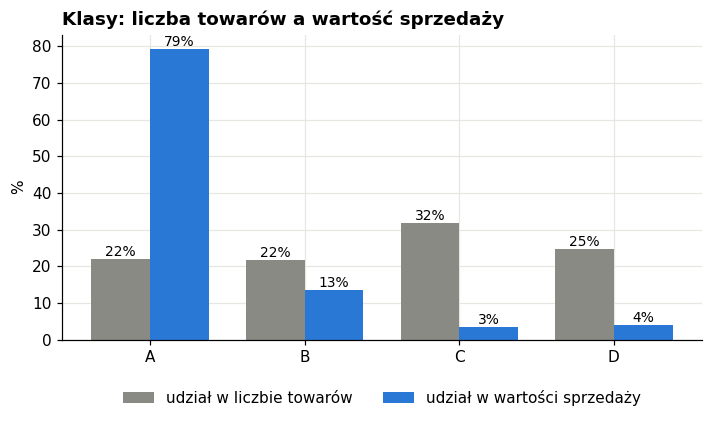

In [29]:
# Towary, wartość i sztuki wg klasy
skl = pd.DataFrame({
    "Towary": klasa_tow.value_counts().reindex(KLASY),
    "TowarySprzedane": s.groupby("Klasa", observed=False)["SKU"].nunique(),
    "Wartosc": s.groupby("Klasa", observed=False)["Wartosc"].sum(),
    "Sztuki": s.groupby("Klasa", observed=False)["IloscPlus"].sum(),
    "Paragony": s.groupby("Klasa", observed=False)["DokId"].nunique(),
})
skl["Towary_%"] = skl["Towary"] / skl["Towary"].sum() * 100
skl["Wartosc_%"] = skl["Wartosc"] / skl["Wartosc"].sum() * 100
skl["SrWartoscNaTowar"] = skl["Wartosc"] / skl["TowarySprzedane"]
print(skl.round(1).to_string())

fig, ax = plt.subplots(figsize=(7.5, 3.6))
x = np.arange(4); w = 0.38
ax.bar(x - w/2, skl["Towary_%"], w, color=SZARY, label="udział w liczbie towarów")
ax.bar(x + w/2, skl["Wartosc_%"], w, color=NIEB, label="udział w wartości sprzedaży")
for xi, a, b in zip(x, skl["Towary_%"], skl["Wartosc_%"]):
    ax.text(xi - w/2, a, f"{a:.0f}%", ha="center", va="bottom", fontsize=9)
    ax.text(xi + w/2, b, f"{b:.0f}%", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x, KLASY); ax.set_ylabel("%")
ax.set_title("Klasy: liczba towarów a wartość sprzedaży")
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.show()

## 9. Klasy w czasie
Dla każdej klasy sprzedaż miesięczna. Jeśli D jest „historyczne”, jego udział powinien spadać z czasem.

#### Objaśnienie: kilka szeregów czasowych naraz
**Po co ta komórka.** Do tej pory mieliśmy jeden szereg: sprzedaż całego sklepu. Teraz budujemy cztery, po jednym dla każdej klasy, i sprawdzamy, jak zmieniały się w czasie.

**Format długi i szeroki.**
- **Długi**: jeden wiersz to para (dzień, klasa). Tak wygląda `dk` po `groupby(["Data", "Klasa"])`.
- **Szeroki**: jeden wiersz to dzień, a każda klasa ma własną kolumnę. Tak wygląda `W` po `pivot(...)`.

Do analizy szeregów wygodniejszy jest format szeroki, bo każda kolumna jest gotowym szeregiem czasowym.

**Co robi kod.**
- `reindex(kalendarz).fillna(0)` daje pełny kalendarz z zerami w dni bez sprzedaży, tak jak w części I.
- `W["Razem"]` to suma klas. Powinna odpowiadać sprzedaży sklepu z części I.
- `to_period("M")` zamienia daty na miesiące, co pozwala zsumować sprzedaż miesięcznie. Ostatni miesiąc jest usuwany, jeśli nie jest pełny.
- `udzial = mm.div(mm.sum(axis=1), axis=0) * 100` dzieli każdy wiersz przez jego sumę i daje udziały procentowe.

**Jak czytać wykresy.**
- Górny to **wykres warstwowy**: klasy ułożone jedna na drugiej. Wysokość całości to sprzedaż sklepu, a grubość warstwy to sprzedaż klasy.
- Dolny pokazuje udział każdej klasy w sprzedaży miesiąca.

**Jak czytać wynik.** Udział klasy A jest stabilny: 77–81%. Klasa D spada z 10,0% w 2023 do 2,1% w 2024 i 0% w 2025, czyli te towary zniknęły ze sprzedaży. Klasa C rośnie z 1,4% do 5,3%.

**Wniosek.** Klasy D i C nie mają stałego poziomu, tylko wyraźny trend (spadkowy i rosnący). To zmienia sposób czytania ich sezonowości w następnych komórkach.

Dni: 1126 | dni handlowe: 952


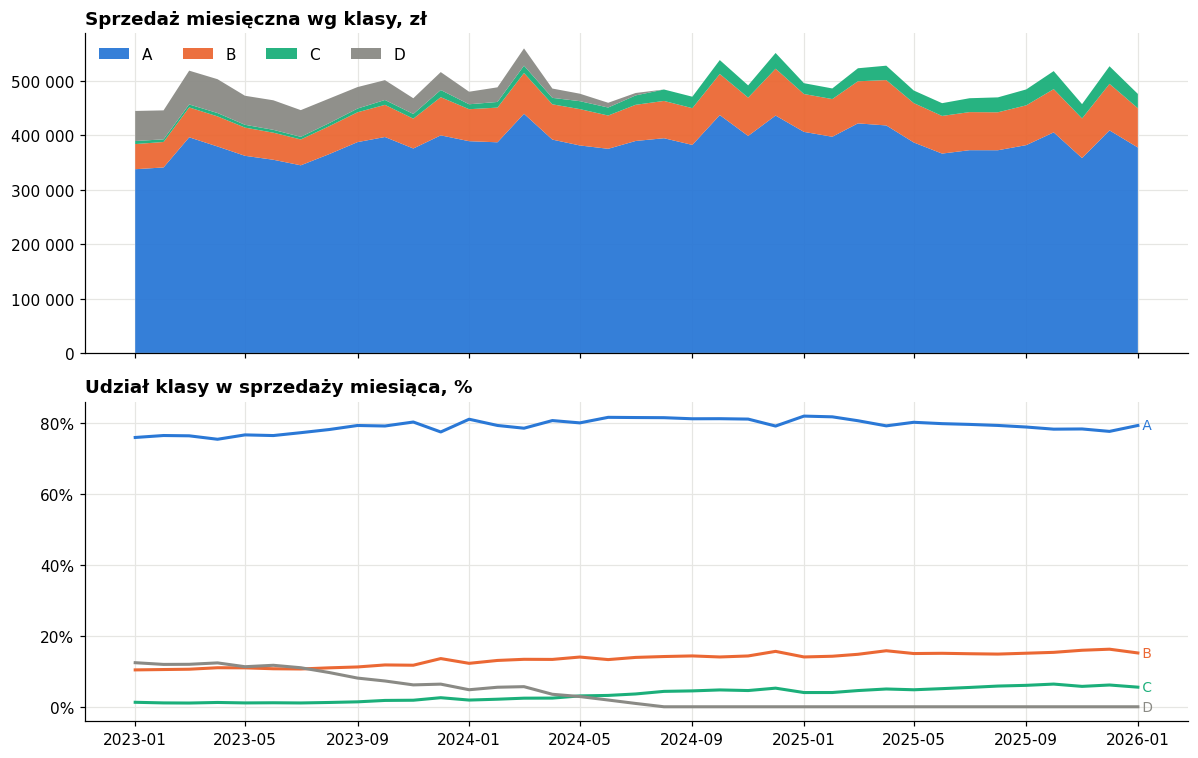

Klasa          A         B         C         D
Rok                                           
2023   4445687.0  643340.0   80589.0  573080.0
2024   4807483.0  825694.0  210786.0  125858.0
2025   4700683.0  892783.0  310622.0       0.0

Klasa     A     B    C     D
Rok                         
2023   77.4  11.2  1.4  10.0
2024   80.5  13.8  3.5   2.1
2025   79.6  15.1  5.3   0.0


In [30]:
# Tabela dzienna: wartość, sztuki, paragony i liczba różnych towarów wg klasy na pełnym kalendarzu
kalendarz = pd.date_range(s["Data"].min(), s["Data"].max(), freq="D")
g = s.groupby(["Data", "Klasa"], observed=False)
dk = pd.DataFrame({
    "Wartosc": g["Wartosc"].sum(), "Sztuki": g["IloscPlus"].sum(),
    "Paragony": g["DokId"].nunique(), "LiczbaTowarow": g["SKU"].nunique(),
}).reset_index()
W = dk.pivot(index="Data", columns="Klasa", values="Wartosc").reindex(kalendarz).fillna(0)[KLASY]
W.index.name = "Data"
W["Razem"] = W[KLASY].sum(axis=1)
W["Rok"], W["Miesiac"], W["DzienTyg"] = W.index.year, W.index.month, W.index.dayofweek
W["Handlowy"] = W["Razem"] > 0
print("Dni:", len(W), "| dni handlowe:", int(W["Handlowy"].sum()))

# Pełne miesiące (bez ostatniego, jeśli niepełny)
mm = W.groupby([W.index.to_period("M")])[KLASY].sum()
ost = W.index.max()
if ost != ost + pd.offsets.MonthEnd(0):
    mm = mm.iloc[:-1]
udzial = mm.div(mm.sum(axis=1), axis=0) * 100

fig, axs = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax = axs[0]
ax.stackplot(mm.index.to_timestamp(), [mm[k] for k in KLASY], colors=[KOL[k] for k in KLASY], labels=KLASY, alpha=0.95)
ax.yaxis.set_major_formatter(zl); ax.set_title("Sprzedaż miesięczna wg klasy, zł")
ax.legend(frameon=False, ncol=4, loc="upper left")
ax = axs[1]
for k in KLASY:
    ax.plot(udzial.index.to_timestamp(), udzial[k], color=KOL[k], lw=2, label=k)
    ax.text(udzial.index.to_timestamp()[-1], udzial[k].iloc[-1], f" {k}", color=KOL[k], va="center", fontsize=9)
ax.set_title("Udział klasy w sprzedaży miesiąca, %")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
plt.tight_layout(); plt.show()

rr = W[W["Rok"].isin([2023, 2024, 2025])].groupby("Rok")[KLASY].sum()
print(rr.round(0).to_string()); print(); print((rr.div(rr.sum(axis=1), axis=0) * 100).round(1).to_string())

## 10. Dzień tygodnia wg klasy
Indeks = średnia sprzedaż danego dnia tygodnia (tylko dni handlowe) / średnia Pn-So. 1,00 to przeciętny dzień. Niedziele pomijamy (prawie zawsze zamknięte).

#### Objaśnienie: czy rytm tygodnia jest wspólny dla klas
**Po co ta komórka.** Sprawdzamy, czy każda klasa ma własny wzorzec tygodnia, czy wszystkie zachowują się tak samo. Od odpowiedzi zależy, czy model potrzebuje osobnych cech dla klas.

**Indeks dnia tygodnia.** Średnia sprzedaż klasy w danym dniu tygodnia podzielona przez średnią sprzedaż tej klasy we wszystkie dni. Wartość 1,00 to dzień przeciętny.

**Dlaczego indeks, a nie złotówki.** Klasa A sprzedaje kilkadziesiąt razy więcej niż C. Na wykresie w złotówkach linia C byłaby płaska przy zerze. Indeks sprowadza wszystkie klasy do wspólnej skali, więc można porównać sam *kształt* tygodnia.

**Co robi kod.**
- `hd` to dni handlowe od poniedziałku do soboty.
- Zapis `{k: ... for k in KLASY + ["Razem"]}` to słownik budowany w pętli: dla każdej klasy liczymy jej indeks.

**Jak czytać wynik.** Kolumny tabeli są niemal identyczne. We wszystkich klasach poniedziałek–środa to około 0,90–0,96, piątek około 1,09, sobota około 1,12. Na wykresie linie prawie się pokrywają.

**Wniosek.** Rytm tygodnia jest wspólny dla całego sklepu. Nie trzeba liczyć osobnych wzorców tygodnia dla klas, co upraszcza model. Taki wynik „nie ma różnicy” jest równie cenny jak odkrycie różnicy, bo oszczędza pracy.

       A     B     C     D  Razem
Pn  0.94  0.93  0.93  0.90   0.93
Wt  0.95  0.96  0.93  0.95   0.95
Śr  0.94  0.94  0.95  0.94   0.94
Cz  0.96  0.96  0.99  0.99   0.96
Pt  1.09  1.09  1.08  1.10   1.09
So  1.12  1.11  1.11  1.12   1.12


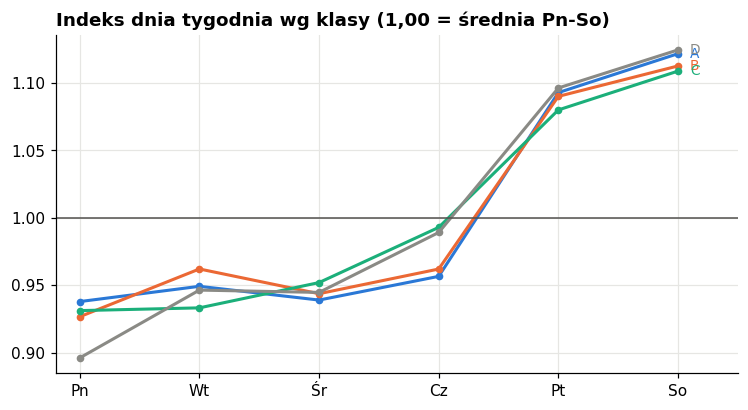

In [31]:
# Indeks dnia tygodnia dla każdej klasy
hd = W[W["Handlowy"] & (W["DzienTyg"] < 6)]
idx_dt = pd.DataFrame({k: hd.groupby("DzienTyg")[k].mean() / hd[k].mean() for k in KLASY + ["Razem"]})
idx_dt.index = DNI[:6]
print(idx_dt.round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 4))
for k in KLASY:
    ax.plot(idx_dt.index, idx_dt[k], marker="o", ms=4, lw=2, color=KOL[k])
    ax.text(5.1, idx_dt[k].iloc[-1], k, color=KOL[k], va="center", fontsize=9)
ax.axhline(1, color="#52514e", lw=1)
ax.set_xlim(-0.2, 5.5)
ax.set_title("Indeks dnia tygodnia wg klasy (1,00 = średnia Pn-So)")
plt.show()

## 11. Miesiąc wg klasy
Indeks miesiąca: średnia dzienna sprzedaż w miesiącu (dni handlowe Pn-So) podzielona przez średnią tego roku, uśredniona po pełnych latach 2023–2025.

#### Objaśnienie: sezonowość roczna klas i pułapka trendu
**Po co ta komórka.** Liczymy indeks miesiąca osobno dla każdej klasy, żeby sprawdzić, czy klasy różnią się sezonowością roczną.

**Co robi kod.**
- `pe` to dni handlowe Pn–So z pełnych lat 2023–2025.
- Funkcja `indeks_mies` liczy dla każdego roku średnią dzienną w miesiącu, dzieli ją przez średnią tego roku, a potem uśrednia wynik z trzech lat. Dzielenie *w obrębie roku* ma usunąć wpływ zmian poziomu między latami.

**Jak czytać wynik.**
- **A i B** mają łagodną, wiarygodną sezonowość: grudzień 1,10 (A) i 1,26 (B), lipiec około 0,90.
- **C** rośnie od 0,71 w styczniu do 1,66 w grudniu.
- **D** spada z około 2,0 w marcu do 0,35 w grudniu.

**Pułapka: trend udający sezonowość.** Liczby dla C i D wyglądają jak bardzo silny sezon, ale nim nie są. Klasa D wygasała przez cały okres, więc w każdym roku początek był wyższy niż koniec. Klasa C rosła, więc odwrotnie. Indeks liczony w obrębie roku nie odróżnia „co roku w grudniu jest więcej” od „z miesiąca na miesiąc jest coraz więcej”.

**Lekcja.** Zanim zinterpretujesz sezonowość, sprawdź, czy szereg nie ma trendu. Jeśli ma, trzeba go najpierw usunąć (np. dekompozycją) albo wstrzymać się z wnioskami. Następna komórka z opisem mówi to samo wprost dla tego wykresu.

        A     B     C     D  Razem
sty  0.98  0.89  0.71  1.69   0.97
lut  1.01  0.95  0.72  1.89   1.01
mar  1.04  1.01  0.80  2.07   1.05
kwi  1.04  1.04  0.88  1.49   1.05
maj  1.00  1.00  0.85  1.26   1.00
cze  0.96  0.93  0.86  0.99   0.96
lip  0.90  0.88  0.85  0.70   0.90
sie  0.95  0.95  1.01  0.46   0.95
wrz  0.98  0.98  1.10  0.40   0.97
paź  1.01  1.03  1.29  0.37   1.01
lis  1.04  1.08  1.28  0.32   1.03
gru  1.10  1.26  1.66  0.35   1.11


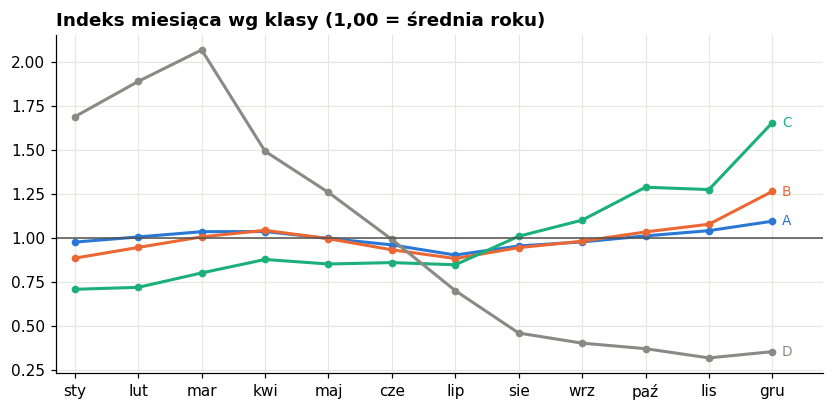

In [32]:
# Indeks miesiąca dla każdej klasy
pe = W[W["Handlowy"] & (W["DzienTyg"] < 6) & W["Rok"].isin([2023, 2024, 2025])]
def indeks_mies(kol_):
    po_roku = pe.groupby(["Rok", "Miesiac"])[kol_].mean().unstack(0)
    return (po_roku / po_roku.mean()).mean(axis=1)
idx_m = pd.DataFrame({k: indeks_mies(k) for k in KLASY + ["Razem"]})
idx_m.index = MIES
print(idx_m.round(2).to_string())

fig, ax = plt.subplots(figsize=(9, 4))
for k in KLASY:
    ax.plot(MIES, idx_m[k], marker="o", ms=4, lw=2, color=KOL[k])
    ax.text(11.15, idx_m[k].iloc[-1], k, color=KOL[k], va="center", fontsize=9)
ax.axhline(1, color="#52514e", lw=1); ax.set_xlim(-0.3, 11.8)
ax.set_title("Indeks miesiąca wg klasy (1,00 = średnia roku)")
plt.show()

**Jak czytać ten wykres.** Dla A i B indeks to rzeczywista sezonowość (łagodna: grudzień około 1,10 dla A i 1,26 dla B, lipiec około 0,90). Dla C i D to głównie **trend**, a nie sezon: D wygasa (sprzedaż spada do zera w 2025), więc jego indeks maleje przez cały rok, a C rośnie (jego udział w sprzedaży wzrósł z 1 % do 5 %), więc indeks rośnie ku grudniowi. Nie interpretujemy tych dwóch linii jako sezonowości.

## 12. Święta wg klasy
Wskaźnik jak w notebooku o sprzedaży w czasie: dzień / mediana tego samego dnia tygodnia w oknie ±42 dni (bez dni w okolicach świąt), osobno dla każdej klasy.

#### Objaśnienie: efekt świąt w podziale na klasy
**Po co ta komórka.** W części I policzyliśmy, o ile sprzedaż sklepu rośnie przed świętami. Teraz powtarzamy to osobno dla każdej klasy.

**Co robi kod.** Logika jest taka sama jak w sekcji 5:
- zaznaczamy dni w odległości do 4 dni od święta (`BliskoSwieta`),
- dla każdego dnia liczymy normę: medianę sprzedaży klasy z tego samego dnia tygodnia w oknie ±42 dni, bez dni okołoświątecznych i bez samego ocenianego dnia,
- **wskaźnik = sprzedaż klasy w danym dniu / norma**.

Warunek `okno.median() > 0` chroni przed dzieleniem przez zero w klasach, które w części okresu nic nie sprzedawały.

**Jak czytać tabele.** Wiersze to klasy, kolumny to dni względem święta (−2 oznacza dwa dni przed). Wartość 2,06 oznacza sprzedaż ponad dwukrotnie wyższą niż zwykle.

**Jak czytać wynik.** Dwa dni przed Bożym Narodzeniem: A 1,59, B 2,06, C 2,45. Dwa dni przed Wielkanocą: A 1,51, B 1,91, C 2,75. Im niższa klasa, tym silniejszy wzrost przedświąteczny. Po świętach wszystkie klasy spadają do 0,66–0,76 normy.

**Dlaczego tak może być.** Klasa A to towary kupowane codziennie, więc ich sprzedaż rośnie przed świętami umiarkowanie. W klasach B i C jest więcej towarów okazjonalnych, kupowanych głównie na święta.

**Ostrożność.** Wyniki dla C i D opierają się na małych kwotach. Jeśli norma to kilkadziesiąt złotych dziennie, kilka dodatkowych sprzedaży daje ogromny wskaźnik. Zasada ogólna: im mniejsze liczby w mianowniku, tym mniej ufamy wskaźnikom procentowym.

Boże Narodzenie (25.12)
     -7    -6    -5    -4    -3    -2    -1   0   1     2     3
A  1.17  1.16  1.11  1.17  1.58  1.59  0.88 NaN NaN  0.74  0.88
B  1.44  1.32  1.36  1.47  1.77  2.06  0.99 NaN NaN  0.69  0.82
C  1.42  1.62  1.33  2.00  2.25  2.45  1.27 NaN NaN  0.66  0.85
D  1.40  1.09  1.42  1.89  1.99  2.06   NaN NaN NaN  0.76  0.93

Wielkanoc (niedziela)
   -7    -6    -5    -4    -3    -2    -1   0   1     2     3
A NaN  1.09  1.21  1.27  1.44  1.51  0.85 NaN NaN  0.82  0.95
B NaN  1.20  1.39  1.40  1.67  1.91  1.04 NaN NaN  0.77  0.87
C NaN  1.21  1.60  1.64  2.01  2.75  1.14 NaN NaN  0.75  0.94
D NaN  1.13  1.69  1.71  1.92  3.06  2.12 NaN NaN  0.93  1.06

Wszystkich Świętych (1.11)
     -7    -6    -5    -4    -3    -2    -1   0     1     2     3
A  1.03  0.98  1.08  1.04  1.06  1.13  1.39 NaN  0.96  1.06  1.07
B  1.02  0.95  0.94  1.08  1.05  1.11  1.32 NaN  0.90  0.97  1.11
C  1.08  0.97  0.95  1.29  0.97  1.25  1.91 NaN  0.93  0.87  0.97
D  0.88  1.08  1.19  0.99   NaN

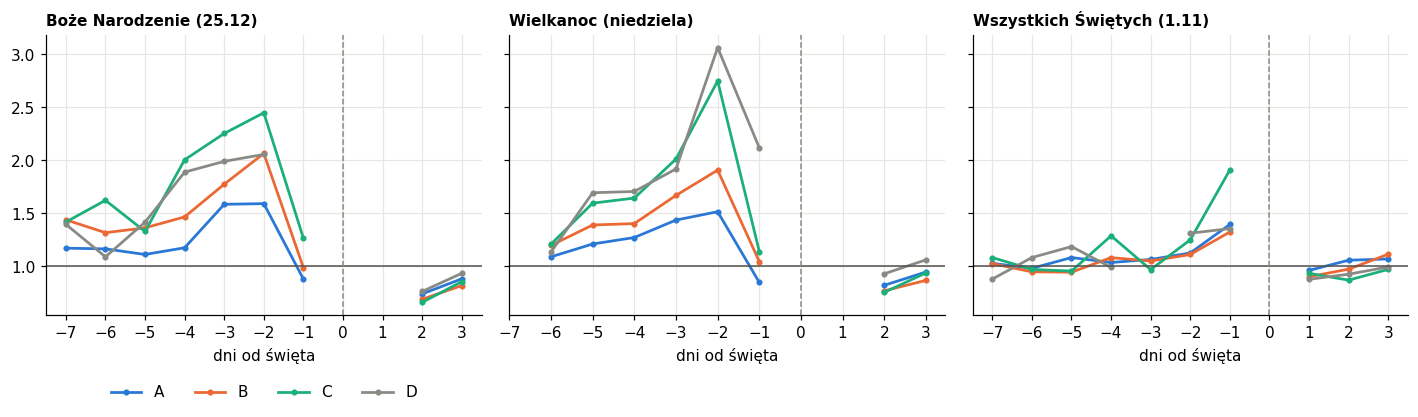

In [33]:
# Wskaźnik względem normy, osobno dla klas
lata = range(W.index.year.min(), W.index.year.max() + 1)
sw = swieta_polska(lata)
dni_sw = pd.DatetimeIndex(sorted(pd.Timestamp(d) for d in sw.keys()))
bl = np.zeros(len(W), dtype=bool)
for d in dni_sw:
    bl |= (np.abs((W.index - d).days) <= 4)
W["BliskoSwieta"] = bl
ok = W["Handlowy"] & (W["DzienTyg"] < 6)
zw = W[ok & ~W["BliskoSwieta"]]

def wskaznik(kol_):
    wyn = pd.Series(np.nan, index=W.index)
    for d in W.index[ok]:
        okno = zw[(zw["DzienTyg"] == d.dayofweek) & (zw.index != d) & (np.abs((zw.index - d).days) <= 42)][kol_]
        if len(okno) >= 3 and okno.median() > 0:
            wyn[d] = W.at[d, kol_] / okno.median()
    return wyn
WS = pd.DataFrame({k: wskaznik(k) for k in KLASY + ["Razem"]})

WYBRANE = {
    "Boże Narodzenie (25.12)": [pd.Timestamp(y, 12, 25) for y in lata],
    "Wielkanoc (niedziela)": [pd.Timestamp(easter(y)) for y in lata],
    "Wszystkich Świętych (1.11)": [pd.Timestamp(y, 11, 1) for y in lata],
}
OFFS = list(range(-7, 4))
prof = {}
for nazwa, daty in WYBRANE.items():
    prof[nazwa] = pd.DataFrame({k: [np.nanmean([WS[k].get(d + pd.Timedelta(days=o), np.nan) for d in daty]) if any(not np.isnan(WS[k].get(d + pd.Timedelta(days=o), np.nan)) for d in daty) else np.nan for o in OFFS] for k in KLASY}, index=OFFS)
for n, t in prof.items():
    print(n); print(t.round(2).T.to_string()); print()

fig, axs = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, (n, t) in zip(axs, prof.items()):
    for k in KLASY:
        ax.plot(t.index, t[k], marker="o", ms=3, lw=1.8, color=KOL[k], label=k)
    ax.axhline(1, color="#52514e", lw=1); ax.axvline(0, color=SZARY, lw=1, ls="--")
    ax.set_title(n, fontsize=10); ax.set_xticks(OFFS); ax.set_xlabel("dni od święta")
axs[0].legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.2))
plt.tight_layout(); plt.show()

## 13. Towary sezonowe w klasach A, B, C
Dla każdego towaru sprawdzamy, czy sprzedaż skupia się w trzech kolejnych miesiącach roku. Towar uznajemy za sezonowy, gdy **w obu latach 2024 i 2025** co najmniej 55 % rocznej wartości przypada na trzy kolejne miesiące (losowy towar miałby około 25 %), a okna szczytu w obu latach różnią się najwyżej o jeden miesiąc. Towary z roczną sprzedażą poniżej 500 zł w którymś z lat pomijamy, bo wynik byłby przypadkowy.

#### Objaśnienie: automatyczne wykrywanie towarów sezonowych
**Po co ta komórka.** Chcemy znaleźć pojedyncze towary sezonowe (np. lody albo znicze) bez ręcznego przeglądania tysięcy pozycji. Potrzebna jest reguła, którą da się policzyć.

**Reguła.** Towar jest sezonowy, jeśli spełnia wszystkie warunki:
1. w roku 2024 co najmniej 55% rocznej sprzedaży przypada na trzy kolejne miesiące,
2. to samo w roku 2025,
3. te trzymiesięczne okna w obu latach zaczynają się w tym samym miesiącu albo różnią się o jeden,
4. roczna sprzedaż w każdym z lat wynosi co najmniej 500 zł.

**Skąd próg 55%.** Towar sprzedający się równo przez cały rok ma w dowolnych trzech miesiącach 3/12, czyli 25% sprzedaży. 55% to ponad dwa razy więcej.

**Dlaczego wymagamy dwóch lat.** Jeden rok może być przypadkiem: promocja, wprowadzenie towaru do oferty, jednorazowe duże zamówienie. Powtórzenie w drugim roku w tym samym okresie świadczy o prawdziwym sezonie.

**Co robi kod.**
- `M[r]` to tabela „towar × miesiąc” ze sprzedażą w roku `r`.
- `np.roll(a, -1, axis=1)` przesuwa kolumny o jeden miesiąc *po okręgu* (po grudniu wraca styczeń). Suma `a + roll(-1) + roll(-2)` daje sprzedaż z trzech kolejnych miesięcy dla każdego możliwego początku, także dla okna listopad–styczeń.
- `okna.max(axis=1) / suma` to udział najlepszego okna, a `argmax` wskazuje miesiąc, w którym się ono zaczyna.
- `np.minimum(rozn, 12 - rozn)` liczy odległość między miesiącami po okręgu: grudzień i styczeń dzieli 1, a nie 11.

**Jak czytać wynik.** W klasie A sezonowych jest 19 z 2289 ocenianych towarów (0,8%), w klasie B 3 z 72. W klasach C i D żaden towar nie przekroczył progu 500 zł rocznie w obu latach, więc nie da się ich ocenić.

**Wniosek.** Towary sezonowe to mały ułamek oferty. Większość asortymentu sprzedaje się w miarę równo przez cały rok.

**Uwaga.** Ta flaga jest liczona na całych danych, razem z przyszłością względem dowolnego dnia prognozy. Dlatego nie trafia do pliku z cechami dla modelu (wyciek danych).

In [34]:
# Koncentracja sprzedaży w 3 kolejnych miesiącach (okno kołowe: lis-sty-lut też się liczy)
s["Rok"] = s["Data"].dt.year
s["Mies"] = s["Data"].dt.month
M = {}
for r in (2024, 2025):
    t = s[s["Rok"] == r].groupby(["SKU", "Mies"])["Wartosc"].sum().unstack(fill_value=0).reindex(columns=range(1, 13), fill_value=0)
    M[r] = t
wspolne = M[2024].index.intersection(M[2025].index)
wyniki = pd.DataFrame(index=wspolne)
for r in (2024, 2025):
    a = M[r].loc[wspolne].to_numpy()
    suma = a.sum(axis=1)
    okna = a + np.roll(a, -1, axis=1) + np.roll(a, -2, axis=1)
    wyniki[f"Suma_{r}"] = suma
    wyniki[f"Udzial3M_{r}"] = np.where(suma > 0, okna.max(axis=1) / np.where(suma > 0, suma, 1), np.nan)
    wyniki[f"StartSzczytu_{r}"] = okna.argmax(axis=1) + 1
rozn = (wyniki["StartSzczytu_2024"] - wyniki["StartSzczytu_2025"]).abs()
wyniki["RoznicaOkien"] = np.minimum(rozn, 12 - rozn)
wyniki["MaDane"] = (wyniki["Suma_2024"] >= 500) & (wyniki["Suma_2025"] >= 500)
wyniki["CzySezonowyDane"] = (wyniki["MaDane"] & (wyniki["Udzial3M_2024"] >= 0.55) & (wyniki["Udzial3M_2025"] >= 0.55) & (wyniki["RoznicaOkien"] <= 1)).astype("int8")
wyniki["Klasa"] = klasa_tow.reindex(wyniki.index).values
tab_sez = wyniki[wyniki["MaDane"]].groupby("Klasa", observed=False).agg(
    TowaryZDanymi=("CzySezonowyDane", "size"), Sezonowe=("CzySezonowyDane", "sum"))
tab_sez["Sezonowe_%"] = tab_sez["Sezonowe"] / tab_sez["TowaryZDanymi"] * 100
print(tab_sez.reindex(KLASY).fillna(0).round(1).to_string())

       TowaryZDanymi  Sezonowe  Sezonowe_%
Klasa                                     
A             2289.0      19.0         0.8
B               72.0       3.0         4.2
C                0.0       0.0         0.0
D                0.0       0.0         0.0


#### Objaśnienie: sprawdzenie wyników zdrowym rozsądkiem
**Po co ta komórka.** Poprzednia komórka oznaczyła towary sezonowe według reguły liczbowej. Teraz patrzymy na ich nazwy, żeby ocenić, czy reguła ma sens.

**Co robi kod.**
- `nazwy` to słownik „SKU: nazwa towaru”, wczytany z pliku.
- `sez` to towary oznaczone jako sezonowe, posortowane według łącznej wartości sprzedaży w latach 2024–2025.
- `Szczyt` to trzymiesięczne okno z największą sprzedażą w 2025 roku. Zapis `(int(a)+1) % 12` to arytmetyka po okręgu: reszta z dzielenia przez 12 sprawia, że po grudniu następuje styczeń.
- Wykres słupkowy liczy, ile towarów sezonowych zaczyna swój szczyt w każdym miesiącu.

**Jak czytać wynik.** Na liście są arbuz (czerwiec–sierpień), nektarynka i brzoskwinia (lipiec–wrzesień), lody (wiosna i lato), czereśnia (maj–lipiec, 100% sprzedaży w oknie), śliwka (sierpień–październik) i szyszki z likierem (zima). To towary, które każdy uznałby za sezonowe, więc reguła działa.

**Przykłady wątpliwe.** Na liście są też masło i napój energetyczny, których nikt nie nazwałby sezonowymi. Zwróć uwagę na kolumny `Udzial3M`: napój ma 0,57 w 2024 i 0,99 w 2025. Prawie cała sprzedaż w jednym oknie wygląda raczej na towar wprowadzony lub wycofany w trakcie roku albo na promocję niż na sezon.

**Lekcja.** Każda automatyczna reguła daje trochę fałszywych trafień. Dlatego wynik zawsze warto obejrzeć oczami kogoś, kto zna towar. Ten krok nazywa się **walidacją merytoryczną** i jest równie ważny jak obliczenia.

                                        Nazwa Klasa  Wartosc_24_25  Udzial3M_2024  Udzial3M_2025   Szczyt
SKU                                                                                                      
51629                       ARBUZ CZERWONY KG     A       12725.49           0.55           0.80  cze–sie
51899                 NEKTARYNKA KG HISZPANIA     A        7383.03           0.75           0.95  lip–wrz
66058   LODY TIRAMISU SOS CZEKOLADA 0,9L SPAR     A        6515.00           0.58           0.60  maj–lip
51764               BRZOSKWINIA 1KG HISZPANIA     A        5133.09           0.75           0.89  lip–wrz
17619  SZYSZKA FIGARO Z LIKIEREM ADVOCAT/CZEK     A        4761.35           0.82           0.97  gru–lut
18573          NAPÓJ ENER RED BULL 2PAK 500ML     A        3419.93           0.57           0.99  mar–maj
65702       LODY BURZA CHMURKA MIX 90ML KORAL     A        3086.37           0.60           0.66  kwi–cze
14329    MASŁO EXTRA KOST WARMIA 200G POLMLEK 

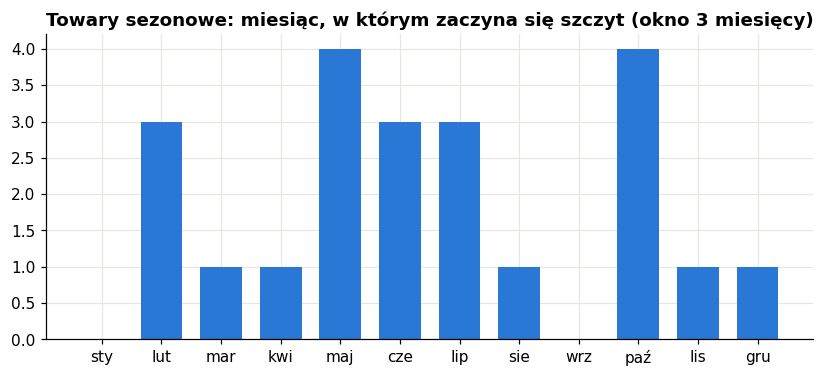

In [35]:
# Najważniejsze towary sezonowe wg wartości w 2024-2025, z oknem szczytu
nazwy = pd.read_parquet(PLIK, columns=["SKU", "NazwaTow"]).drop_duplicates("SKU").set_index("SKU")["NazwaTow"]
sez = wyniki[wyniki["CzySezonowyDane"] == 1].copy()
sez["Wartosc_24_25"] = sez["Suma_2024"] + sez["Suma_2025"]
sez["Szczyt"] = [f"{MIES[(int(a)-1)]}–{MIES[(int(a)+1) % 12]}" for a in sez["StartSzczytu_2025"]]
sez["Nazwa"] = nazwy.reindex(sez.index).astype(str).str.slice(0, 38)
print(sez.sort_values("Wartosc_24_25", ascending=False).head(15)[["Nazwa", "Klasa", "Wartosc_24_25", "Udzial3M_2024", "Udzial3M_2025", "Szczyt"]].round(2).to_string())

# Które miesiące są szczytem dla towarów sezonowych
fig, ax = plt.subplots(figsize=(9, 3.6))
sr = sez["StartSzczytu_2025"].value_counts().reindex(range(1, 13), fill_value=0)
ax.bar(MIES, sr.values, color=NIEB, width=0.7)
ax.set_title("Towary sezonowe: miesiąc, w którym zaczyna się szczyt (okno 3 miesięcy)")
plt.show()

## 14. Wnioski (część II)
- **A to prawie cały sklep:** 22 % towarów daje 79 % wartości. Udział A jest stabilny (77–81 %), więc ogólny wzór tygodnia i roku to w praktyce wzór klasy A.
- **Dzień tygodnia jest wspólny dla wszystkich klas** (piątek i sobota około 1,1, poniedziałek–środa około 0,93). Osobnych indeksów tygodnia dla klas nie trzeba.
- **Sezon roczny jest słaby w A (grudzień 1,10) i mocniejszy w B (1,26).** C i D nie nadają się do oceny sezonu na tych danych (trend zasłania sezon).
- **Święta różnicują klasy:** przed Bożym Narodzeniem i Wielkanocą sprzedaż rośnie we wszystkich klasach, ale im niższa klasa, tym silniej (dwa dni przed Wielkanocą: A około 1,5, B 1,9, C 2,7). Wnioski dla C i D opierają się na małych kwotach, więc są niepewne.
- **Towary sezonowe to głównie A** (owoce, lody, szyszki-likier, energetyki). W klasach C i D nie ma towarów z wystarczającą sprzedażą w 2024–2025 do oceny sezonowości.
- **Klasa D to historia:** jej udział spada z 10 % w 2023 do zera w 2025. W prognozie przyszłości D nie ma znaczenia, ale w danych treningowych wprowadza szum.

## 15. Zapis: jeden plik z cechami dla modelu
Wszystko trafia do **jednego pliku** `dane/interim/cechy_model.parquet`, jeden wiersz na dzień (od 2023-01-01 do 2026-12-31):
- **cechy kalendarzowe i świąteczne** z sekcji 7 (znane z góry, także dla dni po końcu danych),
- **sprzedaż dzienna sklepu** (`Wartosc`, `Sztuki`, `Paragony`, ...) i jej opóźnienia (`Wartosc_lag7` ... `Wartosc_sr4tyg`),
- **sprzedaż dzienna wg klasy** (`Wartosc_A` ... `Wartosc_D`) i jej opóźnienia 7 i 14 dni (`Wartosc_A_lag7` ...).

**Co jest cechą, a co celem.** Kolumny z sprzedażą z tego samego dnia (`Wartosc`, `Sztuki`, `Paragony`, `Pozycje`, `SredniParagon`, `Handlowy`, `Wartosc_A` ... `Wartosc_D`) to **cele lub dane do kontroli**: w chwili prognozy ich nie znamy, więc nie wolno ich podawać modelowi jako cech. Cechami są kolumny kalendarzowe i wszystkie z `_lag` oraz `_sr4tyg` w nazwie. Dni po końcu danych mają puste kolumny sprzedaży.

Nie zapisujemy: indeksów sezonowości klas ani flagi `CzySezonowyDane` (liczone na całych danych, więc dałyby wyciek przyszłości) oraz cech na poziomie towaru (inna ziarnistość: jeden wiersz na towar i dzień to już `fact_inka_final.parquet`).

#### Objaśnienie: zapis gotowej tabeli cech
**Po co ta komórka.** Zbieramy wszystko, co przygotowaliśmy, w jedną tabelę i zapisujemy do pliku. Z tego pliku będzie się uczył model prognostyczny.

**Zasada: jedno ziarno.** Plik ma jeden wiersz na dzień. Wszystkie kolumny opisują ten sam dzień. Dzięki temu nie trzeba niczego łączyć przed uczeniem modelu.

**Co robi kod.**
- `kal.join(dz_model, how="left")` dokleja do kalendarza kolumny sprzedaży. „Left” oznacza, że zostają wszystkie dni z kalendarza (do końca 2026), a dla dni bez danych sprzedaży kolumny są puste.
- Opóźnienia liczymy ponownie na pełnym kalendarzu. Dzięki temu pierwsze dni po końcu danych mają już wartości `lag7`, `lag14` itd. z ostatnich znanych tygodni. To pozwoli zrobić prognozę na luty 2026.
- Dla każdej klasy dodajemy jej sprzedaż dzienną (`cel_Wartosc_A` itd., dane kontrolne) oraz opóźnienia 7 i 14 dni (cechy).
- `assert cechy.index.is_unique and ...is_monotonic_increasing` sprawdza, że każda data występuje raz i że daty są po kolei.
- `to_parquet(..., compression="zstd")` zapisuje plik ze skuteczną kompresją.

**Jak czytać wynik.** Plik ma 1461 wierszy (cztery lata po dniu) i 41 kolumn (dawna kolumna `Handlowy` była kopią `CzyOtwarty`). Kolumny z opóźnieniami mają po 509 braków. To oczekiwane: puste są pierwsze dni danych (nie ma wcześniejszej historii), opóźnienia trafiające na dni zamknięte oraz dni w 2026 roku, dla których sprzedaż sprzed tygodnia jeszcze nie istnieje.

**Cechy i cel.** W pliku są dwa rodzaje kolumn i trzeba je rozróżniać:
- **cechy** (wolno podać modelowi): kalendarz oraz wszystko z `_lag` i `_sr4tyg` w nazwie,
- **cel i dane kontrolne** (nie wolno): `Wartosc` oraz wszystko z prefiksem `cel_` (`cel_Sztuki`, `cel_Paragony`, `cel_Wartosc_A` itd.).

Podanie modelowi sprzedaży z dnia, który ma przewidzieć, dałoby świetny wynik na testach i bezużyteczny model w praktyce.

In [36]:
# Jeden plik: kalendarz + sprzedaż dzienna + sprzedaż wg klas (wszystko po indeksie Data)
cechy = kal.join(dz_model, how="left")

# Opóźnienia liczymy na pełnym kalendarzu (do końca 2026), żeby dni tuż po końcu danych miały je z przeszłości
pelny = dz["Wartosc"].where(dz["Handlowy"]).reindex(cechy.index)       # dni zamknięte = brak, nie zero
for k in (1, 2, 3, 4):
    cechy[f"Wartosc_lag{7 * k}"] = pelny.shift(7 * k)
cechy["Wartosc_sr4tyg"] = cechy[[f"Wartosc_lag{7 * k}" for k in (1, 2, 3, 4)]].mean(axis=1)

wk = W[KLASY].reindex(cechy.index)                        # puste dla dni po końcu danych
for k in KLASY:
    cechy[f"cel_Wartosc_{k}"] = wk[k]                       # ten sam dzień: dane kontrolne, nie cecha
sk = W[KLASY].where(W["Handlowy"], np.nan).reindex(cechy.index)
for k in KLASY:
    for lag in (7, 14):
        cechy[f"Wartosc_{k}_lag{lag}"] = sk[k].shift(lag)

assert cechy.index.is_unique and cechy.index.is_monotonic_increasing
cechy.reset_index().to_parquet("dane/interim/cechy_model.parquet", compression="zstd", index=False)

print("Zapisano: cechy_model.parquet", cechy.shape, "|", cechy.index.min().date(), "…", cechy.index.max().date())
print("Kolumny:", list(cechy.columns))
print("Cel i dane kontrolne (nie podawać modelowi):", ["Wartosc"] + [c for c in cechy.columns if c.startswith("cel_")])
print("Braki w kolumnach lag (początek danych i dni zamknięte są puste):")
print(cechy.filter(like="lag").isna().sum().to_string())

Zapisano: cechy_model.parquet (1461, 41) | 2023-01-01 … 2026-12-31
Kolumny: ['Rok', 'Miesiac', 'DzienMiesiaca', 'DzienTyg', 'TydzienRoku', 'DzienRoku', 'CzySwieto', 'NazwaSwieta', 'DniDoSwieta', 'DniOdSwieta', 'DzienPrzedSwietem', 'DzienPoSwiecie', 'BliskoSwieta', 'DniDoWielkanocy', 'DniDoBozegoNarodzenia', 'CzyOtwarty', 'CzyNiedzielaHandlowa', 'CzyDlugiWeekend', 'CzyOtwartyRegula', 'Wartosc', 'cel_Sztuki', 'cel_Paragony', 'cel_Pozycje', 'cel_SredniParagon', 'Wartosc_lag7', 'Wartosc_lag14', 'Wartosc_lag21', 'Wartosc_lag28', 'Wartosc_sr4tyg', 'cel_Wartosc_A', 'cel_Wartosc_B', 'cel_Wartosc_C', 'cel_Wartosc_D', 'Wartosc_A_lag7', 'Wartosc_A_lag14', 'Wartosc_B_lag7', 'Wartosc_B_lag14', 'Wartosc_C_lag7', 'Wartosc_C_lag14', 'Wartosc_D_lag7', 'Wartosc_D_lag14']
Cel i dane kontrolne (nie podawać modelowi): ['Wartosc', 'cel_Sztuki', 'cel_Paragony', 'cel_Pozycje', 'cel_SredniParagon', 'cel_Wartosc_A', 'cel_Wartosc_B', 'cel_Wartosc_C', 'cel_Wartosc_D']
Braki w kolumnach lag (początek danych i dni 

# Część III. Szeregi czasowe wg asortymentu (AsId)
Każdy asortyment (`AsId`) to osobny szereg dzienny. Sprawdzamy, jak dobrze prosty punkt odniesienia prognozuje sprzedaż asortymentu, żeby wiedzieć, które grupy wymagają lepszego modelu.

**Ta część jest samodzielna:** wczytuje dane z pliku i nie korzysta ze zmiennych z części I i II (`dz`, `s`, `zamkniete`), więc można ją uruchomić na świeżym jądrze bez „Run All”. Własne nazwy (`panel`, `zamk`, `s_sklep`) nie nadpisują niczego z wcześniejszych sekcji.

## 16. Panel dzienny: jeden szereg na asortyment
Wiersze to dni (pełny kalendarz), kolumny to asortymenty. Dzień bez sprzedaży asortymentu dostaje 0. Miarę wybiera `MIARA`: ilość (`IloscPlus`) albo wartość w zł (`Wartosc`). Ilość lepiej oddaje popyt, ale w asortymencie z towarami na sztuki i na wagę miesza jednostki; wartość w zł tego problemu nie ma.

#### Objaśnienie: panel, czyli wiele szeregów w jednej tabeli
**Po co ta komórka.** Budujemy osobny szereg dzienny dla każdego asortymentu (grupy towarów). Sklep jako całość jest łatwy do prognozowania, ale zamówienia składa się na grupy towarów, więc tam prognoza jest najbardziej potrzebna.

**Pojęcia.**
- **Asortyment (`AsId`)** to grupa towarowa z systemu sprzedaży. Każdy towar należy do jednego asortymentu.
- **Panel** to tabela, w której wiersze są dniami, a każda kolumna jest osobnym szeregiem czasowym. Wszystkie szeregi mają wspólny kalendarz.

**Co robi kod.**
- Komórka jest samodzielna: ma własne importy i sama wczytuje dane. Można ją uruchomić zaraz po starcie jądra.
- `MIARA` wybiera, co sumujemy. Ilość (`IloscPlus`) lepiej oddaje popyt, ale w asortymencie z towarami na sztuki i na wagę miesza jednostki. Wartość w zł (`Wartosc`) nie ma tego problemu, ale zawiera zmiany cen.
- `zamk_plik` to kalendarz z pliku: dla każdej daty flaga, czy sklep był zamknięty. Liczymy ją *przed* odfiltrowaniem sprzedaży, bo dni zamknięte nie mają wierszy sprzedaży.
- `pivot_table(index="Data", columns="AsId", ..., aggfunc="sum")` sumuje sprzedaż dla każdej pary (dzień, asortyment) i układa wynik w formacie szerokim.
- `.reindex(dni).fillna(0)` dodaje brakujące dni i wstawia zera. Zero jest tu poprawne, bo brak wiersza oznacza brak sprzedaży.
- `s_sklep = panel.sum(axis=1)` to suma wierszami, czyli sprzedaż całego sklepu.

**Jak czytać wynik.** Pierwsza linijka podaje rozmiar panelu: liczbę dni i liczbę asortymentów. Druga to kontrola: powinno wyjść 174 dni zamkniętych i sprzedaż równa 0 w te dni. Jeśli wcześniej uruchomiono część I, trzecia linijka porównuje sumę panelu z tabelą dzienną. Różnica bliska zera oznacza, że żadna sprzedaż nie zginęła ani się nie powieliła.

**Hierarchia.** Sprzedaż tworzy poziomy: sklep, asortyment, towar. Im niższy poziom, tym szereg jest bardziej zaszumiony i trudniejszy do prognozowania, bo w sumie przypadkowe wahania poszczególnych towarów częściowo się znoszą.

In [37]:
# Panel dzienny wg asortymentu (komórka samodzielna: własne importy i wczytanie danych)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if os.path.basename(os.getcwd()) != "analiza_sprzedazy_w_sklepie":
    os.chdir("../..")

PLIK = "dane/interim/fact_inka_final.parquet"
MIARA = "IloscPlus"          # "IloscPlus" = ilość, "Wartosc" = zł

fa = pd.read_parquet(PLIK, columns=["Data", "DokId", "TypDok", "AsId", "CzyZamkniety", MIARA])
zamk_plik = fa.groupby("Data")["CzyZamkniety"].max().eq(1)               # kalendarz z pliku: jedna flaga na dzień
fa = fa[(fa["DokId"] != -1) & (fa["TypDok"] == 21)]                      # sprzedaż, jak w części I

dni = pd.date_range(fa["Data"].min(), fa["Data"].max(), freq="D")
dni.name = "Data"
zamk = zamk_plik.reindex(dni, fill_value=False)                          # maska dni zamkniętych (True = zamknięty)
panel = (fa.pivot_table(index="Data", columns="AsId", values=MIARA, aggfunc="sum", observed=True)
           .reindex(dni).fillna(0))
s_sklep = panel.sum(axis=1)                                              # szereg całego sklepu = suma asortymentów
del fa

print(f"Panel: {panel.shape[0]} dni x {panel.shape[1]} asortymentów | {dni.min().date()} … {dni.max().date()}")
print(f"Dni zamkniętych: {int(zamk.sum())} | sprzedaż w dni zamknięte: {float(s_sklep[zamk].sum()):.2f} (powinno być 0)")
if "dz" in globals():                                                    # kontrola z częścią I, jeśli była uruchomiona
    kol_dz = "Sztuki" if MIARA == "IloscPlus" else "Wartosc"
    print("Różnica względem tabeli dziennej z części I:", float((s_sklep - dz[kol_dz]).abs().max()))

Panel: 1126 dni x 239 asortymentów | 2023-01-02 … 2026-01-31
Dni zamkniętych: 174 | sprzedaż w dni zamknięte: 0.00 (powinno być 0)
Różnica względem tabeli dziennej z części I: 9.094947017729282e-13


## 17. Punkt odniesienia i jego błąd (walk-forward)
**Prognoza:** średnia sprzedaż z tego samego dnia tygodnia, liczona z 48 ostatnich dni otwartych (około 8 tygodni). W dni zamknięte prognoza wynosi 0, bo kalendarz znamy z góry.

**Ocena:** 6 kolejnych okien po 28 dni (od najstarszego `okno_1` do najnowszego `okno_6`). W każdym oknie prognoza powstaje wyłącznie z danych sprzed okna. Błąd podajemy w procentach średniej sprzedaży:
- **dzienny**: średni błąd bezwzględny w dni otwarte / średnia sprzedaż dzienna w dni otwarte,
- **tygodniowy**: ten sam rachunek na sumach tygodniowych (4 tygodnie w oknie). Szum dzienny znosi się w sumie tygodnia, więc ten błąd pokazuje, czy prognoza trafia w poziom sprzedaży.

Okno, w którym asortyment nie miał sprzedaży, dostaje brak (`NaN`) i jest liczone w kolumnie `puste_okna`.

#### Objaśnienie: ta sama ocena dla setek szeregów
**Po co ta komórka.** Sprawdzamy, jak dobrze prosta prognoza działa dla każdego asortymentu. Wynik pokaże, które grupy są łatwe, a które wymagają lepszego modelu.

**Prognoza naiwna.** Dla każdego dnia tygodnia bierzemy średnią sprzedaż z tego samego dnia tygodnia z 48 ostatnich dni otwartych. W dni zamknięte prognoza wynosi 0.

**Funkcja `ocena_naiwnej` krok po kroku.**
1. Pętla `for k in range(okna)` wyznacza 6 okien testowych po 28 dni, licząc od końca danych.
2. `train` to wszystko przed oknem, `test` to okno.
3. `tr` to 48 ostatnich dni otwartych z `train`.
4. `srednie` to średnia dla każdego dnia tygodnia.
5. `prog` to prognoza: każdemu dniu okna przypisujemy średnią jego dnia tygodnia, a dni zamknięte zerujemy.
6. Liczymy błąd i dzielimy go przez średnią sprzedaż, żeby dostać procent.

**Dlaczego błąd w procentach.** Asortymenty różnią się wielkością wielokrotnie. Błąd 50 sztuk jest mały dla dużej grupy i ogromny dla małej. Podzielenie przez średnią sprzedaż daje miarę porównywalną między grupami.

**Błąd dzienny i tygodniowy.** Dzienny mierzy trafność dzień po dniu. Tygodniowy porównuje sumy z całych tygodni (`reshape(-1, 7)` dzieli 28 dni na 4 tygodnie). W sumie tygodnia przypadkowe wahania dzienne się znoszą, więc błąd tygodniowy pokazuje, czy prognoza trafia w ogólny poziom.

**Co robi reszta kodu.**
- `panel.apply(lambda k_: ...)` wykonuje funkcję dla każdej kolumny, czyli dla każdego asortymentu. `.T` obraca wynik tak, żeby asortymenty były w wierszach.
- `udzial_%` to udział asortymentu w sprzedaży sklepu.
- `pd.cut(...)` zamienia błąd tygodniowy na etykietę: do 10% dobra, 10–14% przeciętna, powyżej słaba.
- `puste_okna` liczy okna, w których asortyment nie sprzedał nic. Błędu procentowego nie da się wtedy policzyć (dzielenie przez zero), więc taki asortyment dostaje osobną etykietę.

**Jak czytać wynik.**
- Pierwsze trzy linijki dotyczą całego sklepu i są punktem porównania.
- Podsumowanie ocen mówi, ile asortymentów trafiło do każdej grupy i jaki mają łączny udział w sprzedaży.
- Tabela pokazuje 30 największych asortymentów. Porównaj kolumny `dzienny_%` i `tygodniowy_%`: jeśli tygodniowy jest o połowę niższy, problemem jest zwykły szum dzienny. Jeśli oba są wysokie, zmienia się poziom sprzedaży (sezon, trend, promocje).

In [38]:
# Ocena punktu odniesienia dla sklepu i dla każdego asortymentu
def ocena_naiwnej(szereg, zamk, h=28, okna=6, tygodniowo=False):
    # zwraca błąd procentowy w kolejnych oknach (okno_1 = najstarsze)
    wyn = []
    for k in range(okna):
        koniec = len(szereg) - k * h
        train, test = szereg.iloc[:koniec - h], szereg.iloc[koniec - h:koniec]
        zt = zamk.reindex(test.index)
        tr = train[~zamk.reindex(train.index)].iloc[-48:]                # 48 ostatnich dni otwartych
        srednie = tr.groupby(tr.index.dayofweek).mean()
        prog = pd.Series(test.index.dayofweek.map(srednie), index=test.index).fillna(0).where(~zt, 0)
        if tygodniowo:
            t, p = test.values.reshape(-1, 7).sum(axis=1), prog.values.reshape(-1, 7).sum(axis=1)
            wyn.append(100 * np.abs(t - p).mean() / t.mean() if t.mean() > 0 else np.nan)
        else:
            sr = test[~zt].mean()
            wyn.append(100 * (test - prog)[~zt].abs().mean() / sr if sr > 0 else np.nan)
    return pd.Series(wyn[::-1], index=[f"okno_{i + 1}" for i in range(okna)])

H, OKNA = 28, 6
okresy = [f"{s_sklep.index[len(s_sklep) - (OKNA - i) * H].date()}" for i in range(OKNA)]
print("Początki okien testowych:", okresy)
print("Sklep, błąd dzienny %:   ", ocena_naiwnej(s_sklep, zamk, H, OKNA).round(1).tolist())
print("Sklep, błąd tygodniowy %:", ocena_naiwnej(s_sklep, zamk, H, OKNA, tygodniowo=True).round(1).tolist())

tab_dz = panel.apply(lambda k_: ocena_naiwnej(k_, zamk, H, OKNA)).T
tab_tyg = panel.apply(lambda k_: ocena_naiwnej(k_, zamk, H, OKNA, tygodniowo=True)).T
porownanie = pd.DataFrame({
    "dzienny_%": tab_dz.mean(axis=1),
    "tygodniowy_%": tab_tyg.mean(axis=1),
    "puste_okna": tab_dz.isna().sum(axis=1),
    "udzial_%": 100 * panel.sum() / panel.sum().sum(),
}).sort_values("udzial_%", ascending=False)

# Ocena wg błędu tygodniowego: do 10 % dobra, 10-14 % przeciętna, powyżej słaba; puste okna = osobna grupa
porownanie["ocena"] = pd.cut(porownanie["tygodniowy_%"], [0, 10, 14, np.inf],
                             labels=["dobra", "przeciętna", "słaba"], include_lowest=True).astype(object)
porownanie.loc[porownanie["puste_okna"] > 0, "ocena"] = "puste okna"
porownanie["ocena"] = porownanie["ocena"].fillna("puste okna")

podsum = porownanie.groupby("ocena").agg(asortymenty=("udzial_%", "size"), udzial_proc=("udzial_%", "sum"))
print("\nPodsumowanie ocen (liczba asortymentów i ich łączny udział w sprzedaży, %):")
print(podsum.reindex(["dobra", "przeciętna", "słaba", "puste okna"]).fillna(0).round(1).to_string())
print("\n30 największych asortymentów:")
print(porownanie.head(30).round(1).to_string())

Początki okien testowych: ['2025-08-17', '2025-09-14', '2025-10-12', '2025-11-09', '2025-12-07', '2026-01-04']
Sklep, błąd dzienny %:    [4.3, 4.7, 7.1, 4.6, 19.6, 9.2]
Sklep, błąd tygodniowy %: [3.4, 2.1, 5.4, 2.2, 9.9, 7.4]

Podsumowanie ocen (liczba asortymentów i ich łączny udział w sprzedaży, %):
            asortymenty  udzial_proc
ocena                               
dobra                14         22.8
przeciętna           33         35.0
słaba               154         41.8
puste okna           38          0.4

30 największych asortymentów:
      dzienny_%  tygodniowy_%  puste_okna  udzial_%       ocena
AsId                                                           
119         9.0           5.4           0       5.2       dobra
102        22.9          15.5           0       3.8       słaba
217        20.3          14.0           0       3.5       słaba
322        15.7           8.4           0       3.5       dobra
326        21.0          12.5           0       3.3  przecię

## 18. Asortymenty, z którymi punkt odniesienia sobie nie radzi
Spośród 30 największych asortymentów bierzemy 6 o najwyższym błędzie tygodniowym i pokazujemy ich sprzedaż tygodniową oraz błąd w kolejnych oknach. Na wykresach szukamy przyczyny: powtarzalne szczyty w tych samych miesiącach (sezon roczny), stały wzrost lub spadek (trend, zmiany w ofercie), pojedyncze wysokie słupki (promocje, jednorazowe zakupy).

#### Objaśnienie: diagnoza trudnych asortymentów
**Po co ta komórka.** Liczba mówi, *że* prognoza jest zła. Nie mówi *dlaczego*. Żeby to ustalić, trzeba obejrzeć szereg na wykresie.

**Co robi kod.**
- `trudne` to 6 asortymentów o najwyższym błędzie tygodniowym spośród 30 największych. Ograniczenie do największych ma sens: błąd w grupie o udziale 0,1% nie ma znaczenia dla sklepu.
- `tab_tyg.loc[trudne]` pokazuje błąd tych asortymentów w każdym z sześciu okien osobno.
- `resample("W").sum()` zamienia szereg dzienny na tygodniowy przez sumowanie. To zmiana **częstotliwości** szeregu.
- `.iloc[1:-1]` usuwa pierwszy i ostatni tydzień, które zwykle są niepełne i wyglądałyby jak sztuczne spadki.
- `sharex=True` daje wszystkim wykresom wspólną oś czasu, więc łatwo porównać je w pionie.

**Jak czytać tabelę.** Sprawdź, czy błąd jest wysoki we wszystkich oknach, czy tylko w niektórych. Wysoki błąd tylko w `okno_5` (grudzień) i `okno_6` (styczeń) wskazuje na efekt świąt. Wysoki we wszystkich oknach wskazuje na stałą nieregularność.

**Jak czytać wykresy.** Szukaj jednego z trzech obrazów:
- **Powtarzalne szczyty w tych samych miesiącach każdego roku**: sezonowość roczna. Średnia z ostatnich 8 tygodni jej nie przewidzi. Potrzebna jest informacja o miesiącu albo sprzedaż sprzed roku.
- **Stały wzrost lub spadek**: trend, np. zmiany w ofercie. Średnia z przeszłości zawsze będzie spóźniona.
- **Pojedyncze wysokie słupki**: promocje albo jednorazowe duże zakupy. Bez informacji o promocjach nie da się ich przewidzieć.

**Lekcja.** W analizie danych wykres i liczba uzupełniają się. Liczba pozwala szybko przejrzeć setki szeregów i wskazać podejrzane, a wykres pozwala zrozumieć przyczynę.

Błąd tygodniowy w kolejnych oknach, %:
      okno_1  okno_2  okno_3  okno_4  okno_5  okno_6
AsId                                                
75      26.1   159.0   106.4    54.7    14.0    11.7
223     18.9    14.7    14.8    24.4    50.2    40.7
98       7.6    16.0     7.0     7.1    14.5    92.2
112     10.2    25.2    13.1     8.8    17.2    28.9
313     13.0    13.5    19.6     4.2    22.0    26.7
97       4.8    14.0    10.4    11.7    27.4    29.6


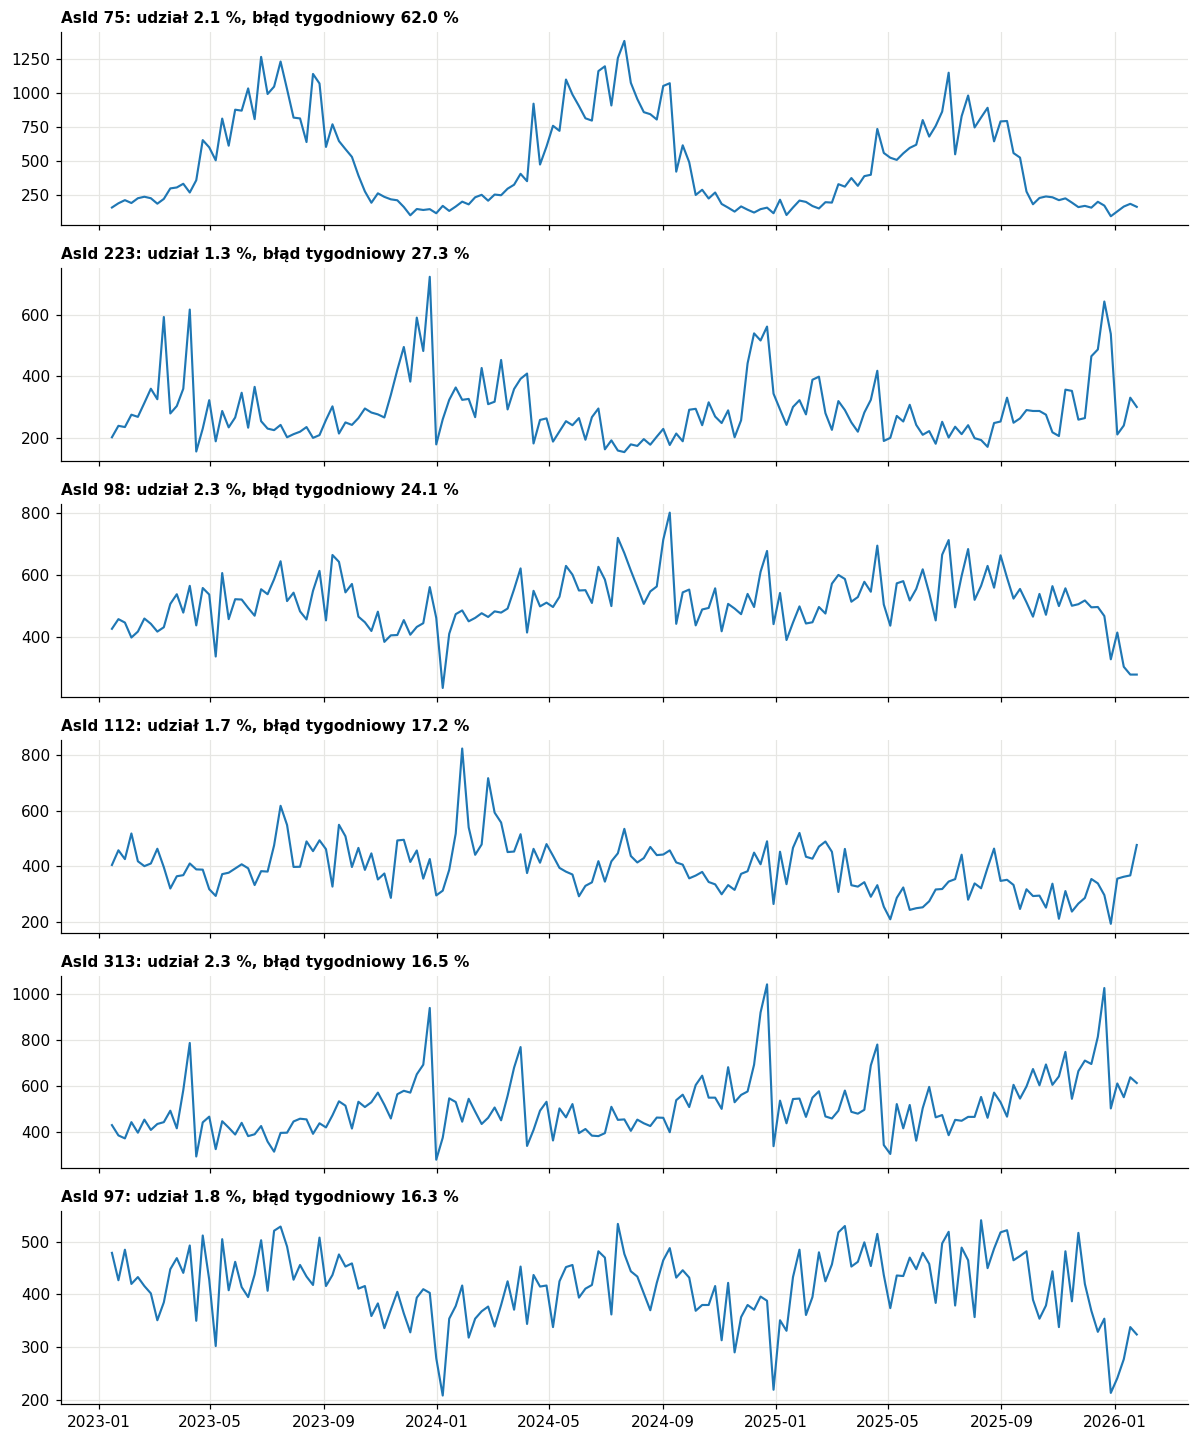

In [39]:
# Sprzedaż tygodniowa i błąd w oknach dla najtrudniejszych dużych asortymentów
trudne = porownanie.head(30).sort_values("tygodniowy_%", ascending=False).head(6).index.tolist()
print("Błąd tygodniowy w kolejnych oknach, %:")
print(tab_tyg.loc[trudne].round(1).to_string())

tyg = panel[trudne].resample("W").sum().iloc[1:-1]            # bez niepełnego pierwszego i ostatniego tygodnia
fig, axs = plt.subplots(len(trudne), 1, figsize=(11, 2.2 * len(trudne)), sharex=True)
for ax, a in zip(np.atleast_1d(axs), trudne):
    ax.plot(tyg.index, tyg[a].values, lw=1.4)
    ax.set_title(f"AsId {a}: udział {porownanie.at[a, 'udzial_%']:.1f} %, błąd tygodniowy {porownanie.at[a, 'tygodniowy_%']:.1f} %", fontsize=10)
plt.tight_layout(); plt.show()

## 19. Jak czytać wyniki (część III)
- **Poprzeczka dla modelu.** Każdy model prognozujący sprzedaż asortymentu musi dać mniejszy błąd niż punkt odniesienia z sekcji 17, liczony tą samą metodą (te same okna, tylko dane z przeszłości).
- **Błąd dzienny a tygodniowy.** Jeśli błąd tygodniowy jest dużo niższy od dziennego, problemem asortymentu jest szum dzienny i prognoza tygodniowa wystarcza. Jeśli oba są wysokie, zmienia się poziom sprzedaży (sezon roczny, trend, promocje) i potrzebne są cechy kalendarzowe albo sprzedaż sprzed roku.
- **Okno grudniowe** (zwykle `okno_5`) ma wyższy błąd w całym sklepie: szczyt przedświąteczny wynika z kalendarza, a nie z ostatnich tygodni.
- **Puste okna** oznaczają asortyment martwy, sezonowy albo wprowadzony lub wycofany w ostatnim półroczu. Błąd procentowy nie ma tam sensu; takie asortymenty oceniamy osobno.
- **Zapis.** Wyników tej części nie dopisujemy do `cechy_model.parquet`: plik ma jeden wiersz na dzień, a tu ziarnem jest asortyment i dzień.